In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Dataset Structure And Feature Identification 

In [3]:
# EDA Step 01.1 — Dataset Loading and Initial Inspection
#
# Research Question:
# What is the structure of our insurance renewal dataset?
#
# Purpose:
# Load the original cleaned dataset, preserve it, and inspect
# dimensions, sample records, column names, and data types.

import pandas as pd
import numpy as np

df = pd.read_csv("cleaned.csv")

# Independent copy for exploratory analysis
eda_df = df.copy(deep=True)

print("Dataset dimensions:")
print(f"Rows: {eda_df.shape[0]:,}")
print(f"Columns: {eda_df.shape[1]}")

print("\nFirst five observations:")
display(eda_df.head())

print("\nRandom five observations:")
display(eda_df.sample(n=min(5, len(eda_df)), random_state=42))

print("\nColumn names:")
display(pd.DataFrame({
    "Column": eda_df.columns,
    "Pandas dtype": eda_df.dtypes.astype(str).values
}))

Dataset dimensions:
Rows: 123,269
Columns: 44

First five observations:


,ID,ID_policy,ID_insured,period,date_effect_insured,date_lapse_insured,date_effect_policy,date_lapse_policy,year_effect_insured,year_lapse_insured,...,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,C_C,target_premium,age_difference
0,10000_1,10000,1,2017,2004-07-01,NaN,2004-07-01,NaN,2004,NaN,...,18.0,67.0,91.0,17.0,23.0,72.0,70.0,C3,630.3600,1
1,10000_1,10000,1,2018,2004-07-01,NaN,2004-07-01,NaN,2004,NaN,...,13.0,66.0,90.0,18.0,23.0,72.0,70.0,C3,652.5858,1
2,10001_1,10001,1,2017,2004-07-09,NaN,2004-07-09,NaN,2004,NaN,...,98.0,7.0,4.0,97.0,1.0,1.0,100.0,C1,2882.5400,1
3,10001_1,10001,1,2018,2004-07-09,NaN,2004-07-09,NaN,2004,NaN,...,98.0,7.0,4.0,97.0,1.0,1.0,100.0,C1,3038.3931,1
4,10002_1,10002,1,2017,2004-08-01,NaN,2004-08-01,NaN,2004,NaN,...,90.0,24.0,20.0,80.0,6.0,2.0,99.0,C1,2010.9100,1



Random five observations:


,ID,ID_policy,ID_insured,period,date_effect_insured,date_lapse_insured,date_effect_policy,date_lapse_policy,year_effect_insured,year_lapse_insured,...,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,C_C,target_premium,age_difference
28970,17766_3,17766,3,2017,1991-06-01,NaN,1989-10-01,NaN,1991,NaN,...,88.0,12.0,8.0,92.0,3.0,1.0,100.0,C3,878.2200,1
85360,33763_1,33763,1,2018,2017-01-01,NaN,2017-01-01,NaN,2017,NaN,...,38.0,64.0,52.0,47.0,21.0,14.0,92.0,C4,787.3788,1
3049,10829_2,10829,2,2017,2005-10-31,NaN,2005-10-31,NaN,2005,NaN,...,34.0,23.0,54.0,56.0,6.0,16.0,95.0,C3,610.0400,1
4624,11217_1,11217,1,2017,2005-06-01,NaN,2005-06-01,NaN,2005,NaN,...,23.0,92.0,77.0,16.0,45.0,45.0,67.0,C6,1457.5800,1
32263,18629_1,18629,1,2017,1992-03-01,2018-04-01,1992-03-01,2018-04-01,1992,2018.0,...,99.0,3.0,3.0,99.0,1.0,1.0,100.0,C3,1112.0100,1



Column names:


,Column,Pandas dtype
0,ID,str
1,ID_policy,int64
2,ID_insured,int64
3,period,int64
4,date_effect_insured,str
5,date_lapse_insured,str
6,date_effect_policy,str
7,date_lapse_policy,str
8,year_effect_insured,int64
9,year_lapse_insured,float64


In [4]:
# Inspect available premium-related columns
premium_cols = [
    col for col in df.columns
    if "premium" in col.lower() or "period" in col.lower()
]

print("Premium and year-related columns:")
print(premium_cols)

display(df[premium_cols].head(10))

Premium and year-related columns:
['period', 'previous_premium', 'target_premium']


,period,previous_premium,target_premium
0,2017,573.24,630.360000
1,2018,630.36,652.585800
2,2017,2885.57,2882.540000
3,2018,2882.54,3038.393100
4,2017,1877.82,2010.910000
5,2018,2010.91,1602.354900
6,2017,1137.26,1230.180000
7,2018,1230.18,849.968656
8,2017,1065.90,1242.360000
9,2018,1242.36,858.666600


The dataset contains 123,269 rows and 44 columns, covering insurance records from 2017 and 2018.

Some customers appear in both years, showing that the dataset has a longitudinal structure.

Our target, target_premium, represents the following year's insurance premium, making this a regression problem.

The dataset contains numerical, categorical, date, and identifier variables. Some dates are currently stored as strings.

Repeated customer records are expected and should not automatically be treated as duplicates.

In [5]:
# EDA Step 01.2 — Feature Type Classification
#
# Research Question:
# What types of variables are present in our dataset?
#
# Purpose:
# Classify features by their statistical meaning
# without modifying the original dataset.

feature_groups = {
    "Identifier": [
        "ID", "ID_policy", "ID_insured"
    ],

    "Target": [
        "target_premium"
    ],

    "Date": [
        "date_effect_insured", "date_lapse_insured",
        "date_effect_policy", "date_lapse_policy"
    ],

    "Categorical": [
        "type_policy", "type_policy_dg", "type_product",
        "reimbursement", "new_business",
        "distribution_channel", "gender",
        "C_H", "C_C"
    ],

    "Numerical - Discrete": [
        "period", "year_effect_insured",
        "year_lapse_insured", "year_effect_policy",
        "year_lapse_policy", "lapse",
        "n_medical_services", "n_insured_pc",
        "n_insured_mun", "n_insured_prov",
        "seniority_insured", "seniority_policy",
        "age", "age_difference"
    ],

    "Numerical - Continuous": [
        "exposure_time", "previous_premium",
        "cost_claims_year", "IICIMUN", "IICIPROV",
        "C_GI", "C_II", "C_IE_P", "C_IE_S",
        "C_IE_T", "C_GE_P", "C_GE_S", "C_GE_T"
    ]
}

# Create a column-to-type mapping
type_mapping = {
    column: group
    for group, columns in feature_groups.items()
    for column in columns
}

# Create classification table
feature_type_summary = pd.DataFrame({
    "Feature": eda_df.columns,
    "Data Type": eda_df.dtypes.astype(str).values,
    "Feature Type": [
        type_mapping.get(col, "Unclassified")
        for col in eda_df.columns
    ]
})

display(feature_type_summary)

print("\nFeature Type Distribution:")
display(feature_type_summary["Feature Type"].value_counts())

print("\nUnclassified Features:")
print(
    feature_type_summary.loc[
        feature_type_summary["Feature Type"] == "Unclassified",
        "Feature"
    ].tolist()
)

,Feature,Data Type,Feature Type
0,ID,str,Identifier
1,ID_policy,int64,Identifier
2,ID_insured,int64,Identifier
3,period,int64,Numerical - Discrete
4,date_effect_insured,str,Date
5,date_lapse_insured,str,Date
6,date_effect_policy,str,Date
7,date_lapse_policy,str,Date
8,year_effect_insured,int64,Numerical - Discrete
9,year_lapse_insured,float64,Numerical - Discrete



Feature Type Distribution:


Feature Type
Numerical - Discrete      14
Numerical - Continuous    13
Categorical                9
Date                       4
Identifier                 3
Target                     1
Name: count, dtype: int64


Unclassified Features:
[]


In [6]:
# EDA Step 01.3 — Feature Cardinality and Variability
#
# Research Question:
# How much variation does each feature contain?
#
# Purpose:
# Examine unique values, dominant values, and missingness
# without modifying the original dataset.

import numpy as np
import pandas as pd

cardinality_summary = pd.DataFrame({
    "Feature": eda_df.columns,
    "Unique Values": eda_df.nunique(dropna=True).values,
    "Unique %": (
        eda_df.nunique(dropna=True).values / len(eda_df) * 100
    ).round(2),
    "Missing %": (
        eda_df.isna().mean().values * 100
    ).round(2),
    "Dominant Value %": [
        eda_df[col].value_counts(
            normalize=True, dropna=False
        ).iloc[0] * 100
        for col in eda_df.columns
    ]
})

cardinality_summary["Dominant Value %"] = (
    cardinality_summary["Dominant Value %"].round(2)
)

display(cardinality_summary)

,Feature,Unique Values,Unique %,Missing %,Dominant Value %
0,ID,69737,56.57,0.00,0.00
1,ID_policy,32543,26.40,0.00,0.97
2,ID_insured,1205,0.98,0.00,42.25
3,period,2,0.00,0.00,51.48
4,date_effect_insured,4822,3.91,0.00,4.81
5,date_lapse_insured,437,0.35,83.72,83.72
6,date_effect_policy,3034,2.46,0.00,5.42
7,date_lapse_policy,257,0.21,85.97,85.97
8,year_effect_insured,86,0.07,0.00,9.56
9,year_lapse_insured,2,0.00,83.72,83.72


In [7]:
# Research Question:
# Which features have little or no variation?
#
# Purpose:
# Identify potential candidates for removal during preprocessing.

constant_features = cardinality_summary[
    cardinality_summary["Unique Values"] <= 1
]

near_constant_features = cardinality_summary[
    (cardinality_summary["Unique Values"] > 1) &
    (cardinality_summary["Dominant Value %"] >= 99)
]

print("Constant Features:")
display(constant_features)

print("\nNear-Constant Features (>= 99% dominant value):")
display(near_constant_features)

Constant Features:


,Feature,Unique Values,Unique %,Missing %,Dominant Value %
13,lapse,1,0.0,0.0,100.0



Near-Constant Features (>= 99% dominant value):


,Feature,Unique Values,Unique %,Missing %,Dominant Value %


In [8]:
# Research Question:
# Which features contain many distinct values?
#
# Purpose:
# Identify high-cardinality variables that may require
# special handling during preprocessing.

high_cardinality_features = cardinality_summary[
    cardinality_summary["Unique Values"] > 100
].sort_values(
    "Unique Values", ascending=False
)

print("High-Cardinality Features (>100 unique values):")
display(high_cardinality_features)

High-Cardinality Features (>100 unique values):


,Feature,Unique Values,Unique %,Missing %,Dominant Value %
0,ID,69737,56.57,0.00,0.00
42,target_premium,37358,30.31,0.00,0.55
1,ID_policy,32543,26.40,0.00,0.97
25,cost_claims_year,9272,7.52,0.00,22.76
24,previous_premium,5833,4.73,0.00,0.72
4,date_effect_insured,4822,3.91,0.00,4.81
6,date_effect_policy,3034,2.46,0.00,5.42
2,ID_insured,1205,0.98,0.00,42.25
30,IICIMUN,875,0.71,4.88,13.98
5,date_lapse_insured,437,0.35,83.72,83.72


In [9]:
# EDA Step 01.4.1 — Reporting Years
#
# Research Question:
# How many observations belong to each reporting year?
#
# Purpose:
# Verify the chronological structure and corresponding target years.

year_summary = (
    eda_df.groupby("period")
    .agg(
        Observations=("ID", "size"),
        Unique_IDs=("ID", "nunique"),
        Unique_Policies=("ID_policy", "nunique"),
        Unique_Insured=("ID_insured", "nunique"),
        Missing_Targets=("target_premium", lambda x: x.isna().sum())
    )
    .reset_index()
)

# Based on our next-year premium prediction definition
year_summary["Expected_Target_Year"] = year_summary["period"] + 1

display(year_summary)

,period,Observations,Unique_IDs,Unique_Policies,Unique_Insured,Missing_Targets,Expected_Target_Year
0,2017,63455,63455,29970,1204,0,2018
1,2018,59814,59814,29288,227,0,2019


In [10]:
# EDA Step 01.4.2 — Duplicate Verification
#
# Research Question:
# Are there duplicate observations or repeated ID-year combinations?
#
# Purpose:
# Detect potential data-quality problems without removing any rows.

exact_duplicates = eda_df.duplicated().sum()

id_period_duplicates = eda_df.duplicated(
    subset=["ID", "period"]
).sum()

print(f"Exact duplicate rows: {exact_duplicates:,}")
print(f"Duplicate (ID, period) combinations: {id_period_duplicates:,}")

# Inspect duplicate ID-year records
duplicate_records = eda_df.loc[
    eda_df.duplicated(
        subset=["ID", "period"],
        keep=False
    )
].sort_values(["ID", "period"])

display(duplicate_records.head(20))

Exact duplicate rows: 0
Duplicate (ID, period) combinations: 0


,ID,ID_policy,ID_insured,period,date_effect_insured,date_lapse_insured,date_effect_policy,date_lapse_policy,year_effect_insured,year_lapse_insured,...,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,C_C,target_premium,age_difference


In [11]:
# EDA Step 04.6: Examine whether C_II missingness varies by insurance product type.
# Calculate the percentage of missing C_II values within each product category.
# Visualize the results to identify possible associations with observed policy characteristics.

missing_by_product = (
    df.groupby("type_product")["C_II"]
      .apply(lambda s: s.isna().mean() * 100)
      .sort_values(ascending=False)
)

display(
    missing_by_product.rename("Missing (%)").to_frame().round(2)
)

,Missing (%)
type_product,
P,6.41
S,6.21
I,5.58
D,1.04


In [12]:
# EDA Step 01.4.3 — Longitudinal Structure
#
# Research Question:
# How many IDs appear in multiple reporting years?
#
# Purpose:
# Understand repeated observations and potential dependencies
# between development and test data.

id_year_counts = (
    eda_df.groupby("ID")["period"].nunique()
)

insured_year_counts = (
    eda_df.groupby("ID_insured")["period"].nunique()
)

print("IDs appearing in both years:",
      (id_year_counts == 2).sum())

print("Insured IDs appearing in both years:",
      (insured_year_counts == 2).sum())

print("\nNumber of reporting years per ID:")
display(id_year_counts.value_counts().sort_index())

print("\nNumber of reporting years per insured ID:")
display(insured_year_counts.value_counts().sort_index())

IDs appearing in both years: 53532
Insured IDs appearing in both years: 226

Number of reporting years per ID:


period
1    16205
2    53532
Name: count, dtype: int64


Number of reporting years per insured ID:


period
1    979
2    226
Name: count, dtype: int64

In [13]:
# EDA Step 01.5.1 — Seniority Redundancy
#
# Research Question:
# Are seniority variables derived from reporting year and start year?
#
# Purpose:
# Identify deterministic relationships between features
# without modifying the original dataset.

seniority_checks = {
    "Insured Seniority": (
        eda_df["period"] - eda_df["year_effect_insured"],
        eda_df["seniority_insured"]
    ),
    "Policy Seniority": (
        eda_df["period"] - eda_df["year_effect_policy"],
        eda_df["seniority_policy"]
    )
}

results = []

for name, (calculated, actual) in seniority_checks.items():

    valid = calculated.notna() & actual.notna()

    matches = calculated[valid].eq(actual[valid])

    results.append({
        "Relationship": name,
        "Compared Rows": valid.sum(),
        "Matching Rows": matches.sum(),
        "Match %": round(matches.mean() * 100, 2),
        "Mismatching Rows": (~matches).sum()
    })

redundancy_summary = pd.DataFrame(results)

display(redundancy_summary)

,Relationship,Compared Rows,Matching Rows,Match %,Mismatching Rows
0,Insured Seniority,123269,123269,100.0,0
1,Policy Seniority,123269,123269,100.0,0


In [14]:
# EDA Step 01.5.2 — Lapse Date and Year Investigation
#
# Research Question:
# Do lapse dates represent events occurring after the reporting year?
#
# Purpose:
# Examine lapse timing and identify potential future-information leakage
# without modifying the original dataset.

lapse_columns = [
    ("date_lapse_insured", "year_lapse_insured"),
    ("date_lapse_policy", "year_lapse_policy")
]

results = []

for date_col, year_col in lapse_columns:

    lapse_year = pd.to_numeric(
        eda_df[year_col], errors="coerce"
    )

    date_year = pd.to_datetime(
        eda_df[date_col], errors="coerce"
    ).dt.year

    reporting_year = eda_df["period"]

    results.append({
        "Feature": year_col,
        "Missing %": round(lapse_year.isna().mean() * 100, 2),
        "Lapse Before Reporting Year": (
            (lapse_year < reporting_year).sum()
        ),
        "Lapse During Reporting Year": (
            (lapse_year == reporting_year).sum()
        ),
        "Lapse After Reporting Year": (
            (lapse_year > reporting_year).sum()
        ),
        "Date-Year Mismatches": (
            (
                date_year.notna() &
                lapse_year.notna() &
                (date_year != lapse_year)
            ).sum()
        )
    })

lapse_timing_summary = pd.DataFrame(results)

display(lapse_timing_summary)

,Feature,Missing %,Lapse Before Reporting Year,Lapse During Reporting Year,Lapse After Reporting Year,Date-Year Mismatches
0,year_lapse_insured,83.72,0,0,20070,0
1,year_lapse_policy,85.97,0,0,17293,0


In [15]:
# EDA Step 01.5.3 — Lapse Year Distribution
#
# Research Question:
# How are lapse events distributed across reporting years?
#
# Purpose:
# Identify whether future lapse information is present
# in historical reporting-year observations.

for col in ["year_lapse_insured", "year_lapse_policy"]:

    print(f"\n{col}")

    display(
        pd.crosstab(
            eda_df["period"],
            eda_df[col].fillna("Missing"),
            dropna=False
        )
    )


year_lapse_insured


C:\Users\AUM\AppData\Local\Temp\ipykernel_20296\510323314.py:17: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  eda_df[col].fillna("Missing"),


year_lapse_insured,2018.0,2019.0,Missing
period,,,
2017,7830,6558,49067
2018,0,5682,54132



year_lapse_policy


C:\Users\AUM\AppData\Local\Temp\ipykernel_20296\510323314.py:17: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  eda_df[col].fillna("Missing"),


year_lapse_policy,2018.0,2019.0,Missing
period,,,
2017,6913,5593,50949
2018,0,4787,55027


In [16]:
# EDA Step 01.5.3.1 — Age Difference Investigation
#
# Research Question:
# What does age_difference represent, and how does it
# relate to age changes across reporting years?
#
# Purpose:
# Identify whether age_difference is redundant or
# potentially derived from future information.

print("Age Difference Distribution:")
display(
    eda_df["age_difference"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nAge Difference by Reporting Year:")
display(
    pd.crosstab(
        eda_df["period"],
        eda_df["age_difference"],
        normalize="index"
    ).round(4) * 100
)

# Compare ages of the same ID across 2017 and 2018
age_comparison = eda_df.pivot(
    index="ID",
    columns="period",
    values="age"
).dropna(subset=[2017, 2018])

age_comparison["Observed_Age_Change"] = (
    age_comparison[2018] - age_comparison[2017]
)

print("\nObserved Age Change Between Years:")
display(
    age_comparison["Observed_Age_Change"]
    .value_counts(dropna=False)
    .sort_index()
)

Age Difference Distribution:


age_difference
0      4168
1    119101
Name: count, dtype: int64


Age Difference by Reporting Year:


age_difference,0,1
period,,
2017,2.71,97.29
2018,4.09,95.91



Observed Age Change Between Years:


Observed_Age_Change
0.0     1206
1.0    52326
Name: count, dtype: int64

In [17]:
# EDA Step 01.5.3.2 — Claims and Medical Services
#
# Research Question:
# How do claims costs and medical-service counts
# behave across reporting years?
#
# Purpose:
# Examine their distributions and identify unusual
# patterns before evaluating prediction-time availability.

claims_summary = (
    eda_df.groupby("period")
    .agg(
        Observations=("ID", "size"),
        Mean_Claims=("cost_claims_year", "mean"),
        Median_Claims=("cost_claims_year", "median"),
        Zero_Claims_Pct=(
            "cost_claims_year",
            lambda x: (x == 0).mean() * 100
        ),
        Mean_Services=("n_medical_services", "mean"),
        Median_Services=("n_medical_services", "median"),
        Zero_Services_Pct=(
            "n_medical_services",
            lambda x: (x == 0).mean() * 100
        )
    )
)

display(claims_summary.round(2))

print("\nClaims and Medical Services Correlation:")
display(
    eda_df[
        ["cost_claims_year", "n_medical_services"]
    ].corr(method="spearman").round(4)
)

,Observations,Mean_Claims,Median_Claims,Zero_Claims_Pct,Mean_Services,Median_Services,Zero_Services_Pct
period,,,,,,,
2017,63455,628.87,228.48,23.01,16.12,7.0,23.01
2018,59814,638.44,226.84,22.50,17.24,7.0,22.50



Claims and Medical Services Correlation:


,cost_claims_year,n_medical_services
cost_claims_year,1.0000,0.9115
n_medical_services,0.9115,1.0000


In [18]:
# EDA Step 01.5.3.3 — Year-to-Year Feature Changes
#
# Research Question:
# Do claims and service counts change across reporting years?
#
# Purpose:
# Understand their temporal behavior for repeated policies.

for feature in ["cost_claims_year", "n_medical_services"]:

    comparison = eda_df.pivot(
        index="ID",
        columns="period",
        values=feature
    ).dropna(subset=[2017, 2018])

    change = comparison[2018] - comparison[2017]

    print(f"\nFeature: {feature}")
    print(f"Repeated IDs compared: {len(comparison):,}")

    display(pd.DataFrame({
        "Mean Change": [change.mean()],
        "Median Change": [change.median()],
        "Increased %": [(change > 0).mean() * 100],
        "Decreased %": [(change < 0).mean() * 100],
        "Unchanged %": [(change == 0).mean() * 100]
    }).round(2))


Feature: cost_claims_year
Repeated IDs compared: 53,532


,Mean Change,Median Change,Increased %,Decreased %,Unchanged %
0,41.94,0.0,44.0,42.61,13.39



Feature: n_medical_services
Repeated IDs compared: 53,532


,Mean Change,Median Change,Increased %,Decreased %,Unchanged %
0,1.9,0.0,44.39,38.85,16.76


In [19]:
# EDA Step 01.5.4.1 — Date-Year Consistency
#
# Research Question:
# Do effective dates agree with their corresponding year features?
#
# Purpose:
# Detect inconsistent records and verify date-year redundancy
# without modifying the original dataset.

date_pairs = [
    ("date_effect_insured", "year_effect_insured"),
    ("date_effect_policy", "year_effect_policy")
]

results = []

for date_col, year_col in date_pairs:

    parsed_date = pd.to_datetime(
        eda_df[date_col],
        errors="coerce"
    )

    extracted_year = parsed_date.dt.year

    recorded_year = pd.to_numeric(
        eda_df[year_col],
        errors="coerce"
    )

    valid = extracted_year.notna() & recorded_year.notna()

    results.append({
        "Date Feature": date_col,
        "Year Feature": year_col,
        "Valid Comparisons": valid.sum(),
        "Year Matches": (
            valid & (extracted_year == recorded_year)
        ).sum(),
        "Year Mismatches": (
            valid & (extracted_year != recorded_year)
        ).sum(),
        "Missing/Invalid Dates": parsed_date.isna().sum(),
        "Missing Years": recorded_year.isna().sum()
    })

date_consistency = pd.DataFrame(results)

date_consistency["Match %"] = (
    date_consistency["Year Matches"]
    / date_consistency["Valid Comparisons"]
    * 100
).round(2)

display(date_consistency)

,Date Feature,Year Feature,Valid Comparisons,Year Matches,Year Mismatches,Missing/Invalid Dates,Missing Years,Match %
0,date_effect_insured,year_effect_insured,123269,123269,0,0,0,100.0
1,date_effect_policy,year_effect_policy,123269,123269,0,0,0,100.0


In [20]:
# EDA Step 01.5.4.2 — Additional Date Information
#
# Research Question:
# Do effective dates contain meaningful information beyond the year?
#
# Purpose:
# Examine month/day variation and distinguish complete date
# redundancy from partial redundancy.

for date_col in [
    "date_effect_insured",
    "date_effect_policy"
]:

    dates = pd.to_datetime(
        eda_df[date_col],
        errors="coerce"
    )

    print(f"\nFeature: {date_col}")

    print("Unique full dates:", dates.nunique())
    print("Unique years:", dates.dt.year.nunique())
    print("Unique months:", dates.dt.month.nunique())
    print(
        "Unique month-day combinations:",
        dates.dt.strftime("%m-%d").nunique()
    )

    print("\nMonth Distribution:")
    display(
        dates.dt.month
        .value_counts(dropna=False)
        .sort_index()
    )


Feature: date_effect_insured
Unique full dates: 4822
Unique years: 86
Unique months: 12
Unique month-day combinations: 364

Month Distribution:


date_effect_insured
1     33197
2      9347
3      9508
4      9071
5      7873
6      8254
7      9716
8      5515
9      5216
10     8254
11     8865
12     8453
Name: count, dtype: int64


Feature: date_effect_policy
Unique full dates: 3034
Unique years: 87
Unique months: 12
Unique month-day combinations: 360

Month Distribution:


date_effect_policy
1     34692
2      9618
3      9491
4      8978
5      7607
6      8248
7      9623
8      5225
9      4890
10     8104
11     8807
12     7986
Name: count, dtype: int64

## Missing Value Analysis 

In [21]:
# EDA Step 02.1.1 — Overall Missingness
#
# Research Question:
# Which features contain missing values, and how much
# missing data exists in the dataset?
#
# Purpose:
# Quantify missingness at feature and dataset levels.

missing_summary = pd.DataFrame({
    "Missing Count": eda_df.isna().sum(),
    "Missing %": eda_df.isna().mean() * 100,
    "Non-Missing Count": eda_df.notna().sum()
})

missing_summary = (
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing %", ascending=False)
    .round(2)
)

print("Dataset Shape:", eda_df.shape)
print("Total Missing Cells:", eda_df.isna().sum().sum())
print("Overall Missing %:", round(eda_df.isna().mean().mean() * 100, 2))
print("Columns With Missing Values:", len(missing_summary))
print("Complete Columns:", eda_df.shape[1] - len(missing_summary))

display(missing_summary)

Dataset Shape: (123269, 44)
Total Missing Cells: 498436
Overall Missing %: 9.19
Columns With Missing Values: 16
Complete Columns: 28


,Missing Count,Missing %,Non-Missing Count
date_lapse_policy,105976,85.97,17293
year_lapse_policy,105976,85.97,17293
date_lapse_insured,103199,83.72,20070
year_lapse_insured,103199,83.72,20070
C_GI,7415,6.02,115854
C_IE_S,7415,6.02,115854
C_IE_P,7415,6.02,115854
C_II,7415,6.02,115854
C_GE_P,7415,6.02,115854
C_GE_S,7415,6.02,115854


In [22]:
# EDA Step 02.1.2 — Year-wise Missingness
#
# Research Question:
# Does missingness differ between 2017 and 2018?
#
# Purpose:
# Identify changes in data completeness across reporting years.

missing_by_year = (
    eda_df.groupby("period")
    .apply(
        lambda group: group.isna().mean() * 100,
        include_groups=False
    )
    .round(2)
    .T
)

missing_by_year = missing_by_year.loc[
    missing_by_year.max(axis=1) > 0
]

missing_by_year["Difference (2018 - 2017)"] = (
    missing_by_year[2018] - missing_by_year[2017]
).round(2)

missing_by_year = missing_by_year.sort_values(
    "Difference (2018 - 2017)",
    key=lambda x: x.abs(),
    ascending=False
)

display(missing_by_year)

period,2017,2018,Difference (2018 - 2017)
date_lapse_insured,77.33,90.50,13.17
year_lapse_insured,77.33,90.50,13.17
date_lapse_policy,80.29,92.00,11.71
year_lapse_policy,80.29,92.00,11.71
C_GI,7.22,4.74,-2.48
C_IE_S,7.22,4.74,-2.48
C_IE_P,7.22,4.74,-2.48
C_II,7.22,4.74,-2.48
C_GE_P,7.22,4.74,-2.48
C_GE_S,7.22,4.74,-2.48


In [23]:
# EDA Step 02.1.3 — Row-Level Missingness
#
# Research Question:
# How many observations contain missing values,
# and how many features are missing per observation?
#
# Purpose:
# Determine whether missingness is concentrated
# in particular observations or widespread.

row_missing_count = eda_df.isna().sum(axis=1)

print("Complete Rows:", (row_missing_count == 0).sum())

print(
    "Rows With At Least One Missing Value:",
    (row_missing_count > 0).sum()
)

print(
    "Rows With Missing Values (%):",
    round((row_missing_count > 0).mean() * 100, 2)
)

print(
    "Average Missing Features Per Row:",
    round(row_missing_count.mean(), 2)
)

print(
    "Maximum Missing Features In One Row:",
    row_missing_count.max()
)

print("\nDistribution of Missing Features Per Row:")

display(
    row_missing_count
    .value_counts()
    .sort_index()
    .rename_axis("Missing Features")
    .reset_index(name="Number of Rows")
)

Complete Rows: 15186
Rows With At Least One Missing Value: 108083
Rows With Missing Values (%): 87.68
Average Missing Features Per Row: 4.04
Maximum Missing Features In One Row: 16

Distribution of Missing Features Per Row:


,Missing Features,Number of Rows
0,0,15186
1,1,1
2,2,2609
3,4,98016
4,5,32
5,7,10
6,8,138
7,10,94
8,11,228
9,12,2929


In [24]:
# EDA Step 02.2.1 — Shared Missingness in C_* Variables
#
# Research Question:
# Do the eight C_* features have identical missingness patterns?
#
# Purpose:
# Determine whether these features are missing together.

c_columns = [
    "C_GI", "C_II",
    "C_IE_P", "C_IE_S", "C_IE_T",
    "C_GE_P", "C_GE_S", "C_GE_T"
]

c_missing = eda_df[c_columns].isna()

print("Missing Values Per Feature:")
display(c_missing.sum().to_frame("Missing Count"))

print(
    "\nRows Where All Eight Are Missing:",
    c_missing.all(axis=1).sum()
)

print(
    "Rows Where At Least One Is Missing:",
    c_missing.any(axis=1).sum()
)

print(
    "Rows Where Some But Not All Are Missing:",
    (
        c_missing.any(axis=1)
        & ~c_missing.all(axis=1)
    ).sum()
)

print(
    "Identical Missingness Patterns:",
    c_missing.eq(c_missing.iloc[:, 0], axis=0).all().all()
)

Missing Values Per Feature:


,Missing Count
C_GI,7415
C_II,7415
C_IE_P,7415
C_IE_S,7415
C_IE_T,7415
C_GE_P,7415
C_GE_S,7415
C_GE_T,7415



Rows Where All Eight Are Missing: 7415
Rows Where At Least One Is Missing: 7415
Rows Where Some But Not All Are Missing: 0
Identical Missingness Patterns: True


In [25]:
# EDA Step 02.2.2 — Lapse Missingness Pattern
#
# Research Question:
# Do the four lapse variables become missing together?
#
# Purpose:
# Verify whether the dominant four-feature missingness
# pattern is caused by lapse-related variables.

lapse_columns = [
    "date_lapse_insured",
    "year_lapse_insured",
    "date_lapse_policy",
    "year_lapse_policy"
]

lapse_missing = eda_df[lapse_columns].isna()

print(
    "Rows Where All Four Lapse Features Are Missing:",
    lapse_missing.all(axis=1).sum()
)

print(
    "Rows Where All Four Lapse Features Are Present:",
    (~lapse_missing.any(axis=1)).sum()
)

print(
    "Rows Where Some Lapse Features Are Missing:",
    (
        lapse_missing.any(axis=1)
        & ~lapse_missing.all(axis=1)
    ).sum()
)

print(
    "Rows Where Exactly Four Features Are Missing "
    "and They Are All Lapse Features:",
    (
        (eda_df.isna().sum(axis=1) == 4)
        & lapse_missing.all(axis=1)
    ).sum()
)

print("\nLapse Missingness Combinations:")

display(
    lapse_missing
    .value_counts()
    .rename("Number of Rows")
    .reset_index()
)

Rows Where All Four Lapse Features Are Missing: 103199
Rows Where All Four Lapse Features Are Present: 17293
Rows Where Some Lapse Features Are Missing: 2777
Rows Where Exactly Four Features Are Missing and They Are All Lapse Features: 98016

Lapse Missingness Combinations:


,date_lapse_insured,year_lapse_insured,date_lapse_policy,year_lapse_policy,Number of Rows
0,True,True,True,True,103199
1,False,False,False,False,17293
2,False,False,True,True,2777


In [26]:
# EDA Step 02.2.3 — Most Frequent Missingness Patterns
#
# Research Question:
# Which combinations of missing features occur most frequently?
#
# Purpose:
# Identify dominant missingness patterns across all 44 columns.

missing_mask = eda_df.isna()

pattern_labels = missing_mask.apply(
    lambda row: tuple(
        missing_mask.columns[row.to_numpy()]
    ),
    axis=1
)

pattern_counts = pattern_labels.value_counts()

pattern_summary = pd.DataFrame({
    "Missing Features": [
        ", ".join(pattern) if pattern else "None"
        for pattern in pattern_counts.index
    ],
    "Number of Missing Features": [
        len(pattern) for pattern in pattern_counts.index
    ],
    "Number of Rows": pattern_counts.values,
    "Percentage of Rows": (
        pattern_counts.values / len(eda_df) * 100
    ).round(2)
})

print("Total Distinct Missingness Patterns:", len(pattern_summary))

display(pattern_summary.head(15))

Total Distinct Missingness Patterns: 19


,Missing Features,Number of Missing Features,Number of Rows,Percentage of Rows
0,"date_lapse_insured, date_lapse_policy, year_la...",4,98016,79.51
1,None,0,15186,12.32
2,"date_lapse_policy, year_lapse_policy",2,2609,2.12
3,"date_lapse_insured, date_lapse_policy, year_la...",15,2424,1.97
4,"IICIMUN, IICIPROV, C_H, C_GI, C_II, C_IE_P, C_...",12,1686,1.37
5,"date_lapse_insured, date_lapse_policy, year_la...",16,1252,1.02
6,"date_lapse_insured, date_lapse_policy, year_la...",12,1231,1.00
7,"IICIMUN, C_H, C_GI, C_II, C_IE_P, C_IE_S, C_IE...",11,228,0.18
8,"date_lapse_insured, date_lapse_policy, year_la...",14,228,0.18
9,"C_GI, C_II, C_IE_P, C_IE_S, C_IE_T, C_GE_P, C_...",8,138,0.11


The dataset contains highly structured missingness. Further analysis is required to identify relationships between missingness indicators and observed features before evaluating possible MCAR, MAR, or MNAR mechanisms. No imputation or deletion strategy has been selected yet.

In [27]:
# EDA Step 02.2.2.1 — Pairwise Missingness Overlap
#
# Research Question:
# Which socioeconomic and geographic variables
# are missing in the same observations?
#
# Purpose:
# Identify shared missingness and overlapping groups.

socio_columns = [
    "IICIMUN", "IICIPROV", "C_H", "C_C",
    "C_GI", "C_II",
    "C_IE_P", "C_IE_S", "C_IE_T",
    "C_GE_P", "C_GE_S", "C_GE_T"
]

socio_missing = eda_df[socio_columns].isna()

# Percentage of rows where both features are missing
overlap_matrix = pd.DataFrame(
    index=socio_columns,
    columns=socio_columns,
    dtype=float
)

for col1 in socio_columns:
    for col2 in socio_columns:
        overlap_matrix.loc[col1, col2] = (
            (socio_missing[col1] & socio_missing[col2]).mean() * 100
        )

display(overlap_matrix.round(2))

,IICIMUN,IICIPROV,C_H,C_C,C_GI,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T
IICIMUN,4.88,2.43,4.88,4.64,4.87,4.87,4.87,4.87,4.87,4.87,4.87,4.87
IICIPROV,2.43,2.43,2.43,2.43,2.43,2.43,2.43,2.43,2.43,2.43,2.43,2.43
C_H,4.88,2.43,4.88,4.64,4.87,4.87,4.87,4.87,4.87,4.87,4.87,4.87
C_C,4.64,2.43,4.64,4.67,4.63,4.63,4.63,4.63,4.63,4.63,4.63,4.63
C_GI,4.87,2.43,4.87,4.63,6.02,6.02,6.02,6.02,6.02,6.02,6.02,6.02
C_II,4.87,2.43,4.87,4.63,6.02,6.02,6.02,6.02,6.02,6.02,6.02,6.02
C_IE_P,4.87,2.43,4.87,4.63,6.02,6.02,6.02,6.02,6.02,6.02,6.02,6.02
C_IE_S,4.87,2.43,4.87,4.63,6.02,6.02,6.02,6.02,6.02,6.02,6.02,6.02
C_IE_T,4.87,2.43,4.87,4.63,6.02,6.02,6.02,6.02,6.02,6.02,6.02,6.02
C_GE_P,4.87,2.43,4.87,4.63,6.02,6.02,6.02,6.02,6.02,6.02,6.02,6.02


In [28]:
# EDA Step 02.2.2.2 — Conditional Missingness
#
# Research Question:
# When one feature is missing, how often
# is another feature also missing?
#
# Purpose:
# Identify nested or dependent missingness patterns.

representative_columns = [
    "IICIMUN", "IICIPROV", "C_H", "C_C", "C_GI"
]

conditional_missing = pd.DataFrame(
    index=representative_columns,
    columns=representative_columns,
    dtype=float
)

for col1 in representative_columns:
    for col2 in representative_columns:

        missing_col1 = socio_missing[col1]

        conditional_missing.loc[col1, col2] = (
            socio_missing.loc[missing_col1, col2].mean() * 100
            if missing_col1.any()
            else float("nan")
        )

conditional_missing.index.name = "Given feature is missing"

print("P(Column Missing | Row Feature Missing) in %")
display(conditional_missing.round(2))

P(Column Missing | Row Feature Missing) in %


,IICIMUN,IICIPROV,C_H,C_C,C_GI
Given feature is missing,,,,,
IICIMUN,100.00,49.77,100.00,95.11,99.83
IICIPROV,100.00,100.00,100.00,100.00,100.00
C_H,100.00,49.77,100.00,95.11,99.83
C_C,99.32,51.97,99.32,100.00,99.25
C_GI,80.92,40.34,80.92,77.03,100.00


In [29]:
# EDA Step 02.2.2.3 — Socioeconomic Missingness Patterns
#
# Research Question:
# Which combinations of socioeconomic variables
# are missing together?
#
# Purpose:
# Identify dominant patterns independently
# of the lapse-related missingness.

socio_patterns = socio_missing.apply(
    lambda row: tuple(
        socio_missing.columns[row.to_numpy()]
    ),
    axis=1
)

socio_pattern_counts = socio_patterns.value_counts()

socio_pattern_summary = pd.DataFrame({
    "Missing Features": [
        ", ".join(pattern) if pattern else "None"
        for pattern in socio_pattern_counts.index
    ],
    "Number of Missing Features": [
        len(pattern) for pattern in socio_pattern_counts.index
    ],
    "Number of Rows": socio_pattern_counts.values,
    "Percentage of Rows": (
        socio_pattern_counts.values / len(eda_df) * 100
    ).round(2)
})

print(
    "Distinct Socioeconomic Missingness Patterns:",
    len(socio_pattern_summary)
)

display(socio_pattern_summary)

Distinct Socioeconomic Missingness Patterns: 8


,Missing Features,Number of Missing Features,Number of Rows,Percentage of Rows
0,None,0,115811,93.95
1,"IICIMUN, IICIPROV, C_H, C_C, C_GI, C_II, C_IE_...",12,2991,2.43
2,"IICIMUN, C_H, C_C, C_GI, C_II, C_IE_P, C_IE_S,...",11,2715,2.20
3,"C_GI, C_II, C_IE_P, C_IE_S, C_IE_T, C_GE_P, C_...",8,1409,1.14
4,"IICIMUN, C_H, C_GI, C_II, C_IE_P, C_IE_S, C_IE...",10,294,0.24
5,C_C,1,33,0.03
6,"IICIMUN, C_H, C_C",3,10,0.01
7,"C_C, C_GI, C_II, C_IE_P, C_IE_S, C_IE_T, C_GE_...",9,6,0.00


In [30]:
# EDA Step 02.3.1 — Missingness Indicators
#
# Research Question:
# Which observations have missing socioeconomic information?
#
# Purpose:
# Create temporary missingness indicators for analysis
# without modifying eda_df.

missing_indicators = pd.DataFrame({
    "C_Group_Missing": eda_df["C_GI"].isna().astype(int),
    "IICIMUN_Missing": eda_df["IICIMUN"].isna().astype(int),
    "IICIPROV_Missing": eda_df["IICIPROV"].isna().astype(int),
    "C_C_Missing": eda_df["C_C"].isna().astype(int)
}, index=eda_df.index)

print("Missingness Indicator Summary:")

display(
    pd.DataFrame({
        "Missing Count": missing_indicators.sum(),
        "Missing %": missing_indicators.mean() * 100
    }).round(2)
)

Missingness Indicator Summary:


,Missing Count,Missing %
C_Group_Missing,7415,6.02
IICIMUN_Missing,6010,4.88
IICIPROV_Missing,2991,2.43
C_C_Missing,5755,4.67


In [31]:
# EDA Step 02.3.2 — Categorical Associations
#
# Research Question:
# Does socioeconomic missingness vary across
# observed categorical characteristics?
#
# Purpose:
# Identify possible associations with missingness
# that would provide evidence against MCAR.

categorical_features = [
    "period",
    "gender",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "distribution_channel",
    "new_business"
]

for indicator in missing_indicators.columns:

    print(f"\n{'=' * 65}")
    print(f"Missingness Indicator: {indicator}")
    print(f"{'=' * 65}")

    for feature in categorical_features:

        temp = pd.DataFrame({
            "Category": eda_df[feature].astype("string").fillna("Missing"),
            "Missing Indicator": missing_indicators[indicator]
        })

        summary = (
            temp.groupby("Category")["Missing Indicator"]
            .agg(
                Observations="size",
                Missing_Count="sum",
                Missing_Rate="mean"
            )
        )

        summary["Missing_Rate"] *= 100

        print(f"\nFeature: {feature}")
        display(summary.round(2))


Missingness Indicator: C_Group_Missing

Feature: period


,Observations,Missing_Count,Missing_Rate
Category,,,
2017,63455,4580,7.22
2018,59814,2835,4.74



Feature: gender


,Observations,Missing_Count,Missing_Rate
Category,,,
F,67341,4386,6.51
M,55928,3029,5.42



Feature: type_policy


,Observations,Missing_Count,Missing_Rate
Category,,,
C,48488,2641,5.45
I,74781,4774,6.38


... (46 outputs left out)


Feature: distribution_channel


,Observations,Missing_Count,Missing_Rate
Category,,,
A,42807,1722,4.02
D,140,0,0.00
I,80322,4033,5.02



Feature: new_business


,Observations,Missing_Count,Missing_Rate
Category,,,
No,109518,3940,3.6
Yes,13751,1815,13.2


In [32]:
# EDA Step 02.3.3 — Numerical Associations
#
# Research Question:
# Do observations with missing socioeconomic information
# differ in their observed numerical characteristics?
#
# Purpose:
# Identify systematic differences that may explain
# socioeconomic missingness.

numerical_features = [
    "age",
    "previous_premium",
    "seniority_insured",
    "seniority_policy",
    "exposure_time",
    "cost_claims_year",
    "n_medical_services"
]

numerical_results = []

for indicator in missing_indicators.columns:

    for feature in numerical_features:

        observed_values = eda_df.loc[
            missing_indicators[indicator] == 0,
            feature
        ].dropna()

        missing_group_values = eda_df.loc[
            missing_indicators[indicator] == 1,
            feature
        ].dropna()

        numerical_results.append({
            "Missingness Indicator": indicator,
            "Feature": feature,
            "Mean (Present Group)": observed_values.mean(),
            "Mean (Missing Group)": missing_group_values.mean(),
            "Median (Present Group)": observed_values.median(),
            "Median (Missing Group)": missing_group_values.median()
        })

numerical_summary = pd.DataFrame(numerical_results)

display(numerical_summary.round(2))

,Missingness Indicator,Feature,Mean (Present Group),Mean (Missing Group),Median (Present Group),Median (Missing Group)
0,C_Group_Missing,age,46.48,44.88,48.00,44.00
1,C_Group_Missing,previous_premium,867.85,978.48,784.77,850.68
2,C_Group_Missing,seniority_insured,14.17,13.79,11.00,17.00
3,C_Group_Missing,seniority_policy,15.21,14.21,13.00,18.00
4,C_Group_Missing,exposure_time,0.99,0.99,1.00,1.00
5,C_Group_Missing,cost_claims_year,627.47,728.00,226.44,248.46
6,C_Group_Missing,n_medical_services,16.51,19.14,7.00,8.00
7,IICIMUN_Missing,age,46.52,43.80,48.00,43.00
8,IICIMUN_Missing,previous_premium,869.21,977.96,786.42,847.62
9,IICIMUN_Missing,seniority_insured,14.22,12.77,11.00,16.00


In [33]:
# EDA Step 02.3.4.1 — Categorical Missingness Tests
#
# Research Question:
# Is socioeconomic missingness associated with observed
# categorical features in the 2017 development data?
#
# Purpose:
# Use chi-square tests and Cramér's V to evaluate
# statistical significance and association strength.

from scipy.stats import chi2_contingency

development_df = eda_df.loc[eda_df["period"] == 2017]

missing_features = {
    "C_Group_Missing": "C_GI",
    "IICIMUN_Missing": "IICIMUN",
    "IICIPROV_Missing": "IICIPROV",
    "C_C_Missing": "C_C"
}

categorical_features = [
    "gender",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "distribution_channel",
    "new_business"
]

categorical_test_results = []

for indicator_name, missing_column in missing_features.items():

    missing_indicator = development_df[missing_column].isna()

    for feature in categorical_features:

        contingency = pd.crosstab(
            development_df[feature].fillna("Missing"),
            missing_indicator
        )

        chi2, p_value, dof, expected = chi2_contingency(
            contingency
        )

        n = contingency.to_numpy().sum()

        cramers_v = np.sqrt(
            chi2 / (n * min(contingency.shape[0] - 1,
                            contingency.shape[1] - 1))
        )

        categorical_test_results.append({
            "Missingness Indicator": indicator_name,
            "Observed Feature": feature,
            "Chi-square": chi2,
            "p-value": p_value,
            "Cramers V": cramers_v,
            "Min Expected Count": expected.min()
        })

categorical_test_summary = pd.DataFrame(
    categorical_test_results
).sort_values(
    ["Missingness Indicator", "Cramers V"],
    ascending=[True, False]
)

display(categorical_test_summary.round(6))

,Missingness Indicator,Observed Feature,Chi-square,p-value,Cramers V,Min Expected Count
20,C_C_Missing,type_policy_dg,23377.451760,0.000000,0.606968,74.471815
23,C_C_Missing,new_business,4193.362842,0.000000,0.257068,435.203751
22,C_C_Missing,distribution_channel,218.873365,0.000000,0.058730,0.232543
19,C_C_Missing,type_policy,182.835080,0.000000,0.053678,1520.190072
21,C_C_Missing,type_product,165.634938,0.000000,0.051091,58.542637
18,C_C_Missing,gender,4.367101,0.036639,0.008296,1682.853723
2,C_Group_Missing,type_policy_dg,18991.650356,0.000000,0.547077,92.458908
5,C_Group_Missing,new_business,3007.457309,0.000000,0.217704,540.318021
4,C_Group_Missing,distribution_channel,216.363142,0.000000,0.058393,0.288709
3,C_Group_Missing,type_product,173.718294,0.000000,0.052323,72.682373


In [34]:
# EDA Step 02.3.4.2 — Numerical Missingness Tests
#
# Research Question:
# Do observed numerical features differ between records
# with and without missing socioeconomic information?
#
# Purpose:
# Test distributional differences and quantify their size.

from scipy.stats import mannwhitneyu

numerical_features = [
    "age",
    "previous_premium",
    "seniority_insured",
    "seniority_policy",
    "exposure_time",
    "cost_claims_year",
    "n_medical_services"
]

numerical_test_results = []

for indicator_name, missing_column in missing_features.items():

    missing_indicator = development_df[missing_column].isna()

    for feature in numerical_features:

        present_group = development_df.loc[
            ~missing_indicator, feature
        ].dropna()

        missing_group = development_df.loc[
            missing_indicator, feature
        ].dropna()

        if len(present_group) == 0 or len(missing_group) == 0:
            continue

        u_stat, p_value = mannwhitneyu(
            missing_group,
            present_group,
            alternative="two-sided",
            method="asymptotic"
        )

        n1 = len(missing_group)
        n2 = len(present_group)

        rank_biserial = 2 * u_stat / (n1 * n2) - 1

        numerical_test_results.append({
            "Missingness Indicator": indicator_name,
            "Observed Feature": feature,
            "Median (Present)": present_group.median(),
            "Median (Missing)": missing_group.median(),
            "p-value": p_value,
            "Rank-Biserial": rank_biserial
        })

numerical_test_summary = pd.DataFrame(
    numerical_test_results
).sort_values(
    ["Missingness Indicator", "p-value"]
)

display(numerical_test_summary.round(6))

,Missingness Indicator,Observed Feature,Median (Present),Median (Missing),p-value,Rank-Biserial
24,C_C_Missing,seniority_policy,13.00,9.000,0.000000,-0.244461
23,C_C_Missing,seniority_insured,12.00,7.000,0.000000,-0.232062
21,C_C_Missing,age,48.00,40.000,0.000000,-0.159310
22,C_C_Missing,previous_premium,782.75,627.210,0.000000,-0.128640
25,C_C_Missing,exposure_time,1.00,1.000,0.000000,0.016631
27,C_C_Missing,n_medical_services,7.00,7.000,0.000106,0.037717
26,C_C_Missing,cost_claims_year,228.48,231.290,0.006525,0.026481
3,C_Group_Missing,seniority_policy,13.00,14.000,0.000000,-0.154287
2,C_Group_Missing,seniority_insured,11.00,13.000,0.000000,-0.139939
0,C_Group_Missing,age,48.00,42.000,0.000000,-0.113931


In [35]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [36]:
# EDA Step 02.3.4.3 — Multiple Testing Correction
#
# Research Question:
# Which missingness associations remain statistically
# significant after accounting for multiple tests?
#
# Purpose:
# Reduce false discoveries across the exploratory tests.

from statsmodels.stats.multitest import multipletests

categorical_test_summary["Adjusted p-value"] = multipletests(
    categorical_test_summary["p-value"],
    method="fdr_bh"
)[1]

categorical_test_summary["Significant (FDR 5%)"] = (
    categorical_test_summary["Adjusted p-value"] < 0.05
)

numerical_test_summary["Adjusted p-value"] = multipletests(
    numerical_test_summary["p-value"],
    method="fdr_bh"
)[1]

numerical_test_summary["Significant (FDR 5%)"] = (
    numerical_test_summary["Adjusted p-value"] < 0.05
)

print("Categorical Associations:")
display(
    categorical_test_summary[
        [
            "Missingness Indicator",
            "Observed Feature",
            "Cramers V",
            "Adjusted p-value",
            "Significant (FDR 5%)"
        ]
    ].round(6)
)

print("\nNumerical Associations:")
display(
    numerical_test_summary[
        [
            "Missingness Indicator",
            "Observed Feature",
            "Rank-Biserial",
            "Adjusted p-value",
            "Significant (FDR 5%)"
        ]
    ].round(6)
)

Categorical Associations:


,Missingness Indicator,Observed Feature,Cramers V,Adjusted p-value,Significant (FDR 5%)
20,C_C_Missing,type_policy_dg,0.606968,0.000000,True
23,C_C_Missing,new_business,0.257068,0.000000,True
22,C_C_Missing,distribution_channel,0.058730,0.000000,True
19,C_C_Missing,type_policy,0.053678,0.000000,True
21,C_C_Missing,type_product,0.051091,0.000000,True
18,C_C_Missing,gender,0.008296,0.038351,True
2,C_Group_Missing,type_policy_dg,0.547077,0.000000,True
5,C_Group_Missing,new_business,0.217704,0.000000,True
4,C_Group_Missing,distribution_channel,0.058393,0.000000,True
3,C_Group_Missing,type_product,0.052323,0.000000,True



Numerical Associations:


,Missingness Indicator,Observed Feature,Rank-Biserial,Adjusted p-value,Significant (FDR 5%)
24,C_C_Missing,seniority_policy,-0.244461,0.000000,True
23,C_C_Missing,seniority_insured,-0.232062,0.000000,True
21,C_C_Missing,age,-0.159310,0.000000,True
22,C_C_Missing,previous_premium,-0.128640,0.000000,True
25,C_C_Missing,exposure_time,0.016631,0.000000,True
27,C_C_Missing,n_medical_services,0.037717,0.000124,True
26,C_C_Missing,cost_claims_year,0.026481,0.007027,True
3,C_Group_Missing,seniority_policy,-0.154287,0.000000,True
2,C_Group_Missing,seniority_insured,-0.139939,0.000000,True
0,C_Group_Missing,age,-0.113931,0.000000,True


Socioeconomic missingness is strongly associated with observed policy characteristics, especially policy category and new business status. These findings provide evidence against MCAR and are consistent with a possible MAR mechanism, although MAR cannot be proven from observed-data tests.

In [37]:
# EDA Step 02.3.5.1 — Policy Category vs New Business
#
# Research Question:
# Are new business observations concentrated in
# particular policy categories?
#
# Purpose:
# Identify potential confounding between
# type_policy_dg and new_business.

development_df = eda_df.loc[eda_df["period"] == 2017]

# Counts by policy category and business status
policy_business_counts = pd.crosstab(
    development_df["type_policy_dg"],
    development_df["new_business"]
)

print("Policy Category vs New Business — Counts:")
display(policy_business_counts)

# Row-wise percentages
policy_business_pct = pd.crosstab(
    development_df["type_policy_dg"],
    development_df["new_business"],
    normalize="index"
) * 100

print("\nPolicy Category vs New Business — Row Percentages:")
display(policy_business_pct.round(2))

Policy Category vs New Business — Counts:


new_business,No,Yes
type_policy_dg,,
C1,5141,1646
C2,1277,4
C3,16252,39
C4,0,1790
I,25823,2784
SE,7476,1223



Policy Category vs New Business — Row Percentages:


new_business,No,Yes
type_policy_dg,,
C1,75.75,24.25
C2,99.69,0.31
C3,99.76,0.24
C4,0.00,100.00
I,90.27,9.73
SE,85.94,14.06


In [38]:
# EDA Step 02.3.5.2 — Stratified Missingness
#
# Research Question:
# Does new_business remain associated with missingness
# within each type_policy_dg category?
#
# Purpose:
# Examine the association after stratifying by
# policy category, without fitting a model.

missing_features = {
    "C_Group_Missing": "C_GI",
    "IICIMUN_Missing": "IICIMUN",
    "IICIPROV_Missing": "IICIPROV",
    "C_C_Missing": "C_C"
}

stratified_results = []

for indicator_name, missing_column in missing_features.items():

    temp = development_df[
        ["type_policy_dg", "new_business", missing_column]
    ].copy()

    temp["is_missing"] = temp[missing_column].isna()

    summary = (
        temp.groupby(
            ["type_policy_dg", "new_business"],
            observed=True
        )["is_missing"]
        .agg(
            Observations="size",
            Missing_Count="sum",
            Missing_Rate="mean"
        )
        .reset_index()
    )

    summary["Missing_Rate"] *= 100
    summary["Missingness Indicator"] = indicator_name

    stratified_results.append(summary)

stratified_missingness = pd.concat(
    stratified_results,
    ignore_index=True
)

for indicator_name in missing_features:

    print(f"\nMissingness Indicator: {indicator_name}")

    display(
        stratified_missingness.loc[
            stratified_missingness["Missingness Indicator"]
            == indicator_name,
            [
                "type_policy_dg",
                "new_business",
                "Observations",
                "Missing_Count",
                "Missing_Rate"
            ]
        ].round(2)
    )


Missingness Indicator: C_Group_Missing


,type_policy_dg,new_business,Observations,Missing_Count,Missing_Rate
0,C1,No,5141,335,6.52
1,C1,Yes,1646,34,2.07
2,C2,No,1277,22,1.72
3,C2,Yes,4,0,0.00
4,C3,No,16252,134,0.82
5,C3,Yes,39,0,0.00
6,C4,Yes,1790,1574,87.93
7,I,No,25823,2288,8.86
8,I,Yes,2784,75,2.69
9,SE,No,7476,107,1.43



Missingness Indicator: IICIMUN_Missing


,type_policy_dg,new_business,Observations,Missing_Count,Missing_Rate
11,C1,No,5141,285,5.54
12,C1,Yes,1646,31,1.88
13,C2,No,1277,9,0.70
14,C2,Yes,4,0,0.00
15,C3,No,16252,33,0.20
16,C3,Yes,39,0,0.00
17,C4,Yes,1790,1574,87.93
18,I,No,25823,1776,6.88
19,I,Yes,2784,63,2.26
20,SE,No,7476,65,0.87



Missingness Indicator: IICIPROV_Missing


,type_policy_dg,new_business,Observations,Missing_Count,Missing_Rate
22,C1,No,5141,170,3.31
23,C1,Yes,1646,2,0.12
24,C2,No,1277,0,0.00
25,C2,Yes,4,0,0.00
26,C3,No,16252,9,0.06
27,C3,Yes,39,0,0.00
28,C4,Yes,1790,1570,87.71
29,I,No,25823,487,1.89
30,I,Yes,2784,28,1.01
31,SE,No,7476,24,0.32



Missingness Indicator: C_C_Missing


,type_policy_dg,new_business,Observations,Missing_Count,Missing_Rate
33,C1,No,5141,267,5.19
34,C1,Yes,1646,31,1.88
35,C2,No,1277,8,0.63
36,C2,Yes,4,0,0.00
37,C3,No,16252,36,0.22
38,C3,Yes,39,0,0.00
39,C4,Yes,1790,1571,87.77
40,I,No,25823,1654,6.41
41,I,Yes,2784,54,1.94
42,SE,No,7476,57,0.76


Socioeconomic missingness is systematically associated with observed policy characteristics. The results provide evidence against MCAR and are consistent with a possible MAR mechanism, but do not establish MAR or exclude MNAR.

In [39]:
# EDA Step 02.4.1 — Numerical Range Inspection
#
# Research Question:
# Are there impossible or suspicious numerical values?
#
# Purpose:
# Inspect ranges, negative values, and zero values
# without modifying the dataset.

development_df = eda_df.loc[eda_df["period"] == 2017]

numerical_audit_columns = [
    "age",
    "previous_premium",
    "target_premium",
    "cost_claims_year",
    "n_medical_services",
    "exposure_time",
    "seniority_insured",
    "seniority_policy",
    "n_insured_pc",
    "n_insured_mun",
    "n_insured_prov"
]

audit_results = []

for column in numerical_audit_columns:

    values = development_df[column]

    audit_results.append({
        "Feature": column,
        "Missing": values.isna().sum(),
        "Minimum": values.min(),
        "Q1": values.quantile(0.25),
        "Median": values.median(),
        "Q3": values.quantile(0.75),
        "Maximum": values.max(),
        "Negative Count": (values < 0).sum(),
        "Zero Count": (values == 0).sum()
    })

numerical_audit = pd.DataFrame(audit_results)

display(numerical_audit.round(2))

,Feature,Missing,Minimum,Q1,Median,Q3,Maximum,Negative Count,Zero Count
0,age,0,0.00,30.00,48.00,64.00,99.00,0,667
1,previous_premium,0,33.33,579.74,776.69,996.87,15339.78,0,0
2,target_premium,0,34.34,613.02,813.05,1061.51,13679.44,0,0
3,cost_claims_year,0,0.00,33.66,228.48,602.97,49509.19,0,14598
4,n_medical_services,0,0.00,1.00,7.00,22.00,1029.00,0,14598
5,exposure_time,0,0.00,1.00,1.00,1.00,1.00,0,1768
6,seniority_insured,0,0.00,3.00,12.00,22.00,84.00,0,7486
7,seniority_policy,0,0.00,3.00,13.00,23.00,85.00,0,7148
8,n_insured_pc,0,1.00,50.00,131.00,449.00,2518.00,0,0
9,n_insured_mun,0,1.00,114.00,1234.00,19315.00,19315.00,0,0


In [40]:
# EDA Step 02.4.2 — Numerical Consistency Checks
#
# Research Questions:
# 1. Do zero medical services correspond to zero claims costs?
# 2. How many observations have age = 0?
# 3. What characterizes observations with zero exposure?
#
# Purpose:
# Investigate suspicious numerical values without
# modifying or removing any observations.

# Check 1 — Medical services and claims consistency
print("Medical Services vs Claims Cost:")

print(
    "Zero services and zero claims:",
    (
        (development_df["n_medical_services"] == 0) &
        (development_df["cost_claims_year"] == 0)
    ).sum()
)

print(
    "Zero services but positive claims:",
    (
        (development_df["n_medical_services"] == 0) &
        (development_df["cost_claims_year"] > 0)
    ).sum()
)

print(
    "Positive services but zero claims:",
    (
        (development_df["n_medical_services"] > 0) &
        (development_df["cost_claims_year"] == 0)
    ).sum()
)

# Check 2 — Age zero
print("\nAge = 0 Observations:")
display(
    development_df.loc[
        development_df["age"] == 0,
        [
            "age", "type_policy_dg", "new_business",
            "previous_premium", "target_premium"
        ]
    ].describe(include="all")
)

# Check 3 — Zero exposure
print("\nExposure Time = 0 Observations:")
display(
    development_df.loc[
        development_df["exposure_time"] == 0,
        [
            "age", "seniority_policy",
            "previous_premium", "target_premium",
            "type_policy_dg", "new_business"
        ]
    ].describe(include="all")
)


Medical Services vs Claims Cost:
Zero services and zero claims: 14598
Zero services but positive claims: 0
Positive services but zero claims: 0

Age = 0 Observations:


,age,type_policy_dg,new_business,previous_premium,target_premium
count,667.0,667,667,667.000000,667.000000
unique,NaN,6,2,NaN,NaN
top,NaN,I,No,NaN,NaN
freq,NaN,314,344,NaN,NaN
mean,0.0,NaN,NaN,523.924753,553.280555
std,0.0,NaN,NaN,150.468304,157.183212
min,0.0,NaN,NaN,107.060000,112.200000
25%,0.0,NaN,NaN,399.960000,426.290000
50%,0.0,NaN,NaN,511.020000,543.380000
75%,0.0,NaN,NaN,610.515000,648.570000



Exposure Time = 0 Observations:


,age,seniority_policy,previous_premium,target_premium,type_policy_dg,new_business
count,1768.000000,1768.000000,1768.000000,1768.000000,1768,1768
unique,NaN,NaN,NaN,NaN,6,2
top,NaN,NaN,NaN,NaN,I,No
freq,NaN,NaN,NaN,NaN,810,1421
mean,37.957579,7.925905,710.322438,748.999084,NaN,NaN
std,21.024763,10.048420,440.900349,473.928173,NaN,NaN
min,0.000000,0.000000,52.020000,53.530000,NaN,NaN
25%,21.000000,1.000000,467.512500,490.860000,NaN,NaN
50%,39.000000,4.000000,635.795000,675.690000,NaN,NaN
75%,52.000000,11.000000,902.940000,940.310000,NaN,NaN


In [41]:
# EDA Step 02.4.3.1 — Zero Exposure Date Investigation
#
# Research Question:
# Do zero-exposure observations have identical
# effective and lapse dates?
#
# Purpose:
# Examine date relationships without modifying
# the original dataset.

zero_exposure_df = development_df.loc[
    development_df["exposure_time"] == 0
].copy()

date_columns = [
    "date_effect_insured",
    "date_lapse_insured",
    "date_effect_policy",
    "date_lapse_policy"
]

# Convert dates only in the temporary analysis copy
for column in date_columns:
    zero_exposure_df[column] = pd.to_datetime(
        zero_exposure_df[column],
        errors="coerce"
    )

date_audit = []

for entity in ["insured", "policy"]:

    effect = zero_exposure_df[f"date_effect_{entity}"]
    lapse = zero_exposure_df[f"date_lapse_{entity}"]

    date_audit.append({
        "Entity": entity,
        "Missing Effective Date": effect.isna().sum(),
        "Missing Lapse Date": lapse.isna().sum(),
        "Both Dates Available": (
            effect.notna() & lapse.notna()
        ).sum(),
        "Same Effective and Lapse Date": (
            effect.notna() & lapse.notna() &
            effect.eq(lapse)
        ).sum(),
        "Lapse Before Effective Date": (
            effect.notna() & lapse.notna() &
            lapse.lt(effect)
        ).sum(),
        "Lapse After Effective Date": (
            effect.notna() & lapse.notna() &
            lapse.gt(effect)
        ).sum()
    })

date_audit_df = pd.DataFrame(date_audit)

display(date_audit_df)

,Entity,Missing Effective Date,Missing Lapse Date,Both Dates Available,Same Effective and Lapse Date,Lapse Before Effective Date,Lapse After Effective Date
0,insured,0,0,1768,0,0,1768
1,policy,0,0,1768,0,0,1768


In [42]:
# EDA Step 02.4.3.2 — Effective Date Patterns
#
# Research Question:
# Are zero-exposure records concentrated among
# newly effective or older policies?
#
# Purpose:
# Compare effective years and examine the
# relationship with policy seniority.

print("Policy Effective Year Distribution:")

display(
    zero_exposure_df["date_effect_policy"]
    .dt.year
    .value_counts()
    .sort_index()
    .tail(20)
)

print("\nInsured Effective Year Distribution:")

display(
    zero_exposure_df["date_effect_insured"]
    .dt.year
    .value_counts()
    .sort_index()
    .tail(20)
)

print("\nZero Exposure by Policy Seniority:")

display(
    zero_exposure_df["seniority_policy"]
    .value_counts()
    .sort_index()
    .head(20)
)

Policy Effective Year Distribution:


date_effect_policy
1998     23
1999     20
2000     13
2001     12
2002     17
2003     57
2004     30
2005     35
2006     25
2007     22
2008     53
2009     70
2010    117
2011     74
2012     80
2013    108
2014     93
2015    146
2016    207
2017    339
Name: count, dtype: int64


Insured Effective Year Distribution:


date_effect_insured
1998     20
1999     29
2000     17
2001     15
2002     13
2003     54
2004     30
2005     33
2006     24
2007     22
2008     57
2009     67
2010    103
2011     74
2012     78
2013     96
2014    117
2015    157
2016    217
2017    347
Name: count, dtype: int64


Zero Exposure by Policy Seniority:


seniority_policy
0     339
1     207
2     146
3      93
4     108
5      80
6      74
7     117
8      70
9      53
10     22
11     25
12     35
13     30
14     57
15     17
16     12
17     13
18     20
19     23
Name: count, dtype: int64

In [43]:
# EDA Step 02.4.3.3 — Sample Zero-Exposure Records
#
# Research Question:
# What date combinations occur in zero-exposure
# observations?
#
# Purpose:
# Inspect representative records for potential
# inconsistencies or structural explanations.

columns_to_inspect = [
    "period",
    "date_effect_insured",
    "date_lapse_insured",
    "date_effect_policy",
    "date_lapse_policy",
    "seniority_insured",
    "seniority_policy",
    "exposure_time",
    "previous_premium",
    "target_premium"
]

display(
    zero_exposure_df[columns_to_inspect]
    .sample(
        n=min(15, len(zero_exposure_df)),
        random_state=42
    )
)

,period,date_effect_insured,date_lapse_insured,date_effect_policy,date_lapse_policy,seniority_insured,seniority_policy,exposure_time,previous_premium,target_premium
77498,2017,2017-01-01,2019-01-01,2017-01-01,2019-01-01,0,0,0.0,378.42,386.83
30183,2017,1999-12-01,2019-01-01,1991-02-01,2019-01-01,18,26,0.0,877.69,913.04
56232,2017,1998-01-01,2019-01-01,1998-01-01,2019-01-01,19,19,0.0,108.07,100.98
77209,2017,2017-01-01,2019-01-01,2017-01-01,2019-01-01,0,0,0.0,549.78,566.10
59531,2017,2004-09-22,2019-01-01,2004-09-22,2019-01-01,13,13,0.0,110.09,113.12
106927,2017,2005-11-13,2019-01-01,2005-11-13,2019-01-01,12,12,0.0,1202.91,1188.30
82118,2017,2016-04-01,2019-01-01,2016-04-01,2019-01-01,1,1,0.0,630.24,709.02
41156,2017,2009-11-24,2019-01-01,2006-10-01,2019-01-01,8,11,0.0,593.88,617.11
80198,2017,2016-09-26,2019-01-01,2015-12-01,2019-01-01,1,2,0.0,377.40,471.67
85318,2017,2017-01-01,2019-01-01,2017-01-01,2019-01-01,0,0,0.0,1370.88,1743.18


In [44]:
# EDA Step 02.4.3.4 — Common Lapse Date Investigation
#
# Research Question:
# Is January 1, 2019 systematically associated
# with zero exposure?
#
# Purpose:
# Compare lapse-date frequencies and exposure
# without modifying the dataset.

for column in ["date_lapse_insured", "date_lapse_policy"]:

    dates = pd.to_datetime(
        development_df[column],
        errors="coerce"
    )

    print(f"\n{column} — Most Frequent Dates:")
    display(dates.value_counts(dropna=False).head(10))

    print("\nZero Exposure with 2019-01-01:")
    print(
        (
            (development_df["exposure_time"] == 0) &
            dates.eq(pd.Timestamp("2019-01-01"))
        ).sum()
    )

    print("\nPositive Exposure with 2019-01-01:")
    print(
        (
            (development_df["exposure_time"] > 0) &
            dates.eq(pd.Timestamp("2019-01-01"))
        ).sum()
    )


date_lapse_insured — Most Frequent Dates:


date_lapse_insured
NaT           49067
2018-12-31     5819
2019-12-31     3029
2019-01-01     2075
2018-07-01      242
2018-02-01      188
2018-04-01      184
2018-10-01      169
2019-04-01      147
2018-03-01      137
Name: count, dtype: int64


Zero Exposure with 2019-01-01:
1768

Positive Exposure with 2019-01-01:
307

date_lapse_policy — Most Frequent Dates:


date_lapse_policy
NaT           50949
2018-12-31     5473
2019-12-31     2727
2019-01-01     1786
2018-07-01      201
2018-04-01      152
2018-02-01      149
2018-10-01      146
2019-04-01      126
2019-02-01       96
Name: count, dtype: int64


Zero Exposure with 2019-01-01:
1768

Positive Exposure with 2019-01-01:
18


In [45]:
# EDA Step 02.4.4.1 — Date Validity Audit
#
# Research Question:
# Are there invalid or suspicious date values?
#
# Purpose:
# Check date parsing, missingness, earliest dates,
# and latest dates without modifying the dataset.

date_columns = [
    "date_effect_insured",
    "date_lapse_insured",
    "date_effect_policy",
    "date_lapse_policy"
]

date_results = []

for column in date_columns:

    original = development_df[column]

    parsed = pd.to_datetime(
        original,
        errors="coerce"
    )

    invalid_count = (
        original.notna() & parsed.isna()
    ).sum()

    date_results.append({
        "Date Column": column,
        "Missing": original.isna().sum(),
        "Invalid Dates": invalid_count,
        "Earliest Date": parsed.min(),
        "Latest Date": parsed.max(),
        "Dates After 2017": (
            parsed > pd.Timestamp("2017-12-31")
        ).sum()
    })

date_validity_summary = pd.DataFrame(date_results)

display(date_validity_summary)

,Date Column,Missing,Invalid Dates,Earliest Date,Latest Date,Dates After 2017
0,date_effect_insured,0,0,1933-06-01,2017-12-17,0
1,date_lapse_insured,49067,0,2018-01-02,2019-12-31,14388
2,date_effect_policy,0,0,1932-03-01,2017-12-17,0
3,date_lapse_policy,50949,0,2018-01-02,2019-12-31,12506


In [46]:
# EDA Step 02.4.4.2 — Date Consistency Audit
#
# Research Question:
# Do date relationships and recorded years agree?
#
# Purpose:
# Identify chronological inconsistencies and
# mismatches between dates and year columns.

date_consistency_results = []

for entity in ["insured", "policy"]:

    effect = pd.to_datetime(
        development_df[f"date_effect_{entity}"],
        errors="coerce"
    )

    lapse = pd.to_datetime(
        development_df[f"date_lapse_{entity}"],
        errors="coerce"
    )

    effect_year = development_df[f"year_effect_{entity}"]
    lapse_year = development_df[f"year_lapse_{entity}"]

    effect_year_mismatch = (
        effect.notna() &
        effect_year.ne(effect.dt.year)
    ).sum()

    lapse_year_mismatch = (
        lapse.notna() &
        lapse_year.ne(lapse.dt.year)
    ).sum()

    date_consistency_results.append({
        "Entity": entity,
        "Lapse Before Effective": (
            effect.notna() &
            lapse.notna() &
            (lapse < effect)
        ).sum(),
        "Same Effective and Lapse": (
            effect.notna() &
            lapse.notna() &
            (lapse == effect)
        ).sum(),
        "Effective Date After 2017": (
            effect > pd.Timestamp("2017-12-31")
        ).sum(),
        "Effective Year Mismatch": effect_year_mismatch,
        "Lapse Year Mismatch": lapse_year_mismatch
    })

date_consistency_summary = pd.DataFrame(
    date_consistency_results
)

display(date_consistency_summary)

,Entity,Lapse Before Effective,Same Effective and Lapse,Effective Date After 2017,Effective Year Mismatch,Lapse Year Mismatch
0,insured,0,0,0,0,0
1,policy,0,0,0,0,0


In [47]:
# EDA Step 02.4.4.3 — Future Lapse Date Audit
#
# Research Question:
# How many 2017 observations contain lapse events
# recorded in later calendar years?
#
# Purpose:
# Quantify potentially future-dependent information.

future_lapse_results = []

for entity in ["insured", "policy"]:

    lapse = pd.to_datetime(
        development_df[f"date_lapse_{entity}"],
        errors="coerce"
    )

    future_lapse_results.append({
        "Entity": entity,
        "Missing Lapse Date": lapse.isna().sum(),
        "Lapse in 2017 or Earlier": (
            lapse.dt.year <= 2017
        ).sum(),
        "Lapse in 2018": (
            lapse.dt.year == 2018
        ).sum(),
        "Lapse in 2019": (
            lapse.dt.year == 2019
        ).sum(),
        "Lapse After 2019": (
            lapse.dt.year > 2019
        ).sum()
    })

future_lapse_summary = pd.DataFrame(
    future_lapse_results
)

display(future_lapse_summary)

,Entity,Missing Lapse Date,Lapse in 2017 or Earlier,Lapse in 2018,Lapse in 2019,Lapse After 2019
0,insured,49067,0,7830,6558,0
1,policy,50949,0,6913,5593,0


In [48]:
# EDA Step 02.4.5.1 — Categorical Value Audit
#
# Research Question:
# What are the unique labels and their frequencies?
#
# Purpose:
# Identify unexpected labels, missing categories,
# and class distributions.

categorical_columns = [
    "gender",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "distribution_channel",
    "new_business"
]

for column in categorical_columns:

    print(f"\n{'=' * 60}")
    print(f"Column: {column}")
    print(f"{'=' * 60}")

    summary = (
        development_df[column]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Count")
    )

    summary["Percentage (%)"] = (
        summary["Count"] / len(development_df) * 100
    ).round(2)

    display(summary)


Column: gender


,Category,Count,Percentage (%)
0,F,34508,54.38
1,M,28947,45.62



Column: type_policy


,Category,Count,Percentage (%)
0,I,37306,58.79
1,C,26149,41.21



Column: type_policy_dg


,Category,Count,Percentage (%)
0,I,28607,45.08
1,C3,16291,25.67
2,SE,8699,13.71
3,C1,6787,10.70
4,C4,1790,2.82
5,C2,1281,2.02


... (2 outputs left out)


Column: distribution_channel


,Category,Count,Percentage (%)
0,I,42166,66.45
1,A,21285,33.54
2,D,4,0.01



Column: new_business


,Category,Count,Percentage (%)
0,No,55969,88.2
1,Yes,7486,11.8


In [49]:
# EDA Step 02.4.5.2 — Label Formatting Audit
#
# Research Question:
# Are categorical labels consistently formatted?
#
# Purpose:
# Detect whitespace and case-related inconsistencies
# without changing the dataset.

formatting_results = []

for column in categorical_columns:

    values = development_df[column].dropna().astype(str)

    normalized = values.str.strip().str.casefold()

    formatting_results.append({
        "Column": column,
        "Original Unique Labels": values.nunique(),
        "Normalized Unique Labels": normalized.nunique(),
        "Leading/Trailing Spaces": (
            values != values.str.strip()
        ).sum(),
        "Empty or Whitespace Labels": (
            values.str.strip() == ""
        ).sum(),
        "Possible Formatting Duplicates": (
            values.nunique() - normalized.nunique()
        )
    })

formatting_summary = pd.DataFrame(formatting_results)

display(formatting_summary)

,Column,Original Unique Labels,Normalized Unique Labels,Leading/Trailing Spaces,Empty or Whitespace Labels,Possible Formatting Duplicates
0,gender,2,2,0,0,0
1,type_policy,2,2,0,0,0
2,type_policy_dg,6,6,0,0,0
3,type_product,4,4,0,0,0
4,distribution_channel,3,3,0,0,0
5,new_business,2,2,0,0,0


In [50]:
# EDA Step 02.4.5.3 — Rare Category Audit
#
# Research Question:
# Are any categorical labels underrepresented?
#
# Purpose:
# Identify categories requiring attention during
# encoding, splitting, and model evaluation.

rare_category_results = []

for column in categorical_columns:

    counts = development_df[column].value_counts(
        dropna=False
    )

    for category, count in counts.items():

        percentage = count / len(development_df) * 100

        if percentage < 1.0:

            rare_category_results.append({
                "Column": column,
                "Category": str(category),
                "Count": count,
                "Percentage (%)": round(percentage, 4)
            })

rare_categories_df = pd.DataFrame(
    rare_category_results,
    columns=[
        "Column",
        "Category",
        "Count",
        "Percentage (%)"
    ]
)

display(
    rare_categories_df.sort_values(
        "Percentage (%)"
    )
)

,Column,Category,Count,Percentage (%)
0,distribution_channel,D,4,0.0063


## Discriptive and Univariate Analysis 

In [51]:
# EDA Step 03.1.1 — Numerical Descriptive Statistics
#
# Research Question:
# What are the central tendencies, variability,
# and ranges of numerical features?
#
# Purpose:
# Calculate descriptive statistics using
# 2017 development data only.

excluded_columns = [
    "ID", "ID_policy", "ID_insured",
    "period",
    "year_effect_insured", "year_lapse_insured",
    "year_effect_policy", "year_lapse_policy",
    "lapse"
]

numerical_columns = [
    col for col in development_df.select_dtypes(
        include="number"
    ).columns
    if col not in excluded_columns
]

descriptive_stats = (
    development_df[numerical_columns]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .T
)

descriptive_stats = descriptive_stats.rename(
    columns={
        "count": "Count",
        "mean": "Mean",
        "std": "Std Dev",
        "min": "Minimum",
        "1%": "P01",
        "5%": "P05",
        "25%": "Q1",
        "50%": "Median",
        "75%": "Q3",
        "95%": "P95",
        "99%": "P99",
        "max": "Maximum"
    }
)

display(descriptive_stats.round(3))

,Count,Mean,Std Dev,Minimum,P01,P05,Q1,Median,Q3,P95,P99,Maximum
exposure_time,63455.0,0.972,0.165,0.00,0.00,1.00,1.00,1.00,1.00,1.000,1.000,1.00
seniority_insured,63455.0,13.936,13.004,0.00,0.00,0.00,3.00,12.00,22.00,39.000,57.000,84.00
seniority_policy,63455.0,14.953,13.972,0.00,0.00,0.00,3.00,13.00,23.00,42.000,65.000,85.00
age,63455.0,46.052,22.994,0.00,0.00,5.00,30.00,48.00,64.00,81.000,88.000,99.00
previous_premium,63455.0,856.285,540.566,33.33,103.02,262.60,579.74,776.69,996.87,1710.113,2755.140,15339.78
cost_claims_year,63455.0,628.872,1601.300,0.00,0.00,0.00,33.66,228.48,602.97,2471.066,6785.180,49509.19
n_medical_services,63455.0,16.122,25.566,0.00,0.00,0.00,1.00,7.00,22.00,62.000,113.000,1029.00
n_insured_pc,63455.0,347.021,515.407,1.00,2.00,7.00,50.00,131.00,449.00,1150.000,2518.000,2518.00
n_insured_mun,63455.0,6248.529,8117.855,1.00,3.00,12.00,114.00,1234.00,19315.00,19315.000,19315.000,19315.00
n_insured_prov,63455.0,14292.819,12525.225,6.00,131.00,479.00,2518.00,7467.00,29465.00,29465.000,29465.000,29465.00


In [52]:
# EDA Step 03.1.2 — Distribution Summary
#
# Research Question:
# Which numerical variables show large differences
# between their mean and median?
#
# Purpose:
# Identify initial evidence of asymmetric
# distributions and substantial variability.

distribution_summary = descriptive_stats[
    ["Count", "Mean", "Median", "Std Dev",
     "Minimum", "P95", "P99", "Maximum"]
].copy()

distribution_summary["Mean - Median"] = (
    distribution_summary["Mean"] -
    distribution_summary["Median"]
)

distribution_summary["IQR"] = (
    descriptive_stats["Q3"] -
    descriptive_stats["Q1"]
)

display(distribution_summary.round(3))

,Count,Mean,Median,Std Dev,Minimum,P95,P99,Maximum,Mean - Median,IQR
exposure_time,63455.0,0.972,1.00,0.165,0.00,1.000,1.000,1.00,-0.028,0.00
seniority_insured,63455.0,13.936,12.00,13.004,0.00,39.000,57.000,84.00,1.936,19.00
seniority_policy,63455.0,14.953,13.00,13.972,0.00,42.000,65.000,85.00,1.953,20.00
age,63455.0,46.052,48.00,22.994,0.00,81.000,88.000,99.00,-1.948,34.00
previous_premium,63455.0,856.285,776.69,540.566,33.33,1710.113,2755.140,15339.78,79.595,417.13
cost_claims_year,63455.0,628.872,228.48,1601.300,0.00,2471.066,6785.180,49509.19,400.392,569.31
n_medical_services,63455.0,16.122,7.00,25.566,0.00,62.000,113.000,1029.00,9.122,21.00
n_insured_pc,63455.0,347.021,131.00,515.407,1.00,1150.000,2518.000,2518.00,216.021,399.00
n_insured_mun,63455.0,6248.529,1234.00,8117.855,1.00,19315.000,19315.000,19315.00,5014.529,19201.00
n_insured_prov,63455.0,14292.819,7467.00,12525.225,6.00,29465.000,29465.000,29465.00,6825.819,26947.00


The numerical variables exhibit heterogeneous distributions, including possible skewness, heavy upper tails, bounded values, and concentrations at zero.

In [53]:
# EDA Step 03.2.1 — Skewness and Kurtosis
#
# Research Question:
# Which numerical variables have asymmetric
# distributions or heavy tails?
#
# Purpose:
# Calculate skewness and excess kurtosis
# using 2017 development data only.

excluded_shape_columns = [
    "ID", "ID_policy", "ID_insured",
    "period",
    "year_effect_insured", "year_lapse_insured",
    "year_effect_policy", "year_lapse_policy",
    "lapse",
    "exposure_time",
    "age_difference"
]

shape_columns = [
    col for col in development_df.select_dtypes(
        include="number"
    ).columns
    if col not in excluded_shape_columns
]

shape_summary = (
    development_df[shape_columns]
    .agg(["count", "skew", "kurt"])
    .T
    .rename(columns={
        "count": "Count",
        "skew": "Skewness",
        "kurt": "Excess Kurtosis"
    })
)

display(
    shape_summary.sort_values(
        "Skewness",
        ascending=False
    ).round(3)
)

,Count,Skewness,Excess Kurtosis
cost_claims_year,63455.0,9.878,158.205
IICIMUN,59610.0,6.476,164.887
n_medical_services,63455.0,5.181,77.715
previous_premium,63455.0,4.651,56.087
target_premium,63455.0,4.247,45.182
n_insured_pc,63455.0,2.807,8.693
C_GE_P,58875.0,1.482,2.486
seniority_policy,63455.0,1.394,2.594
seniority_insured,63455.0,1.275,2.109
C_GE_S,58875.0,1.053,-0.124


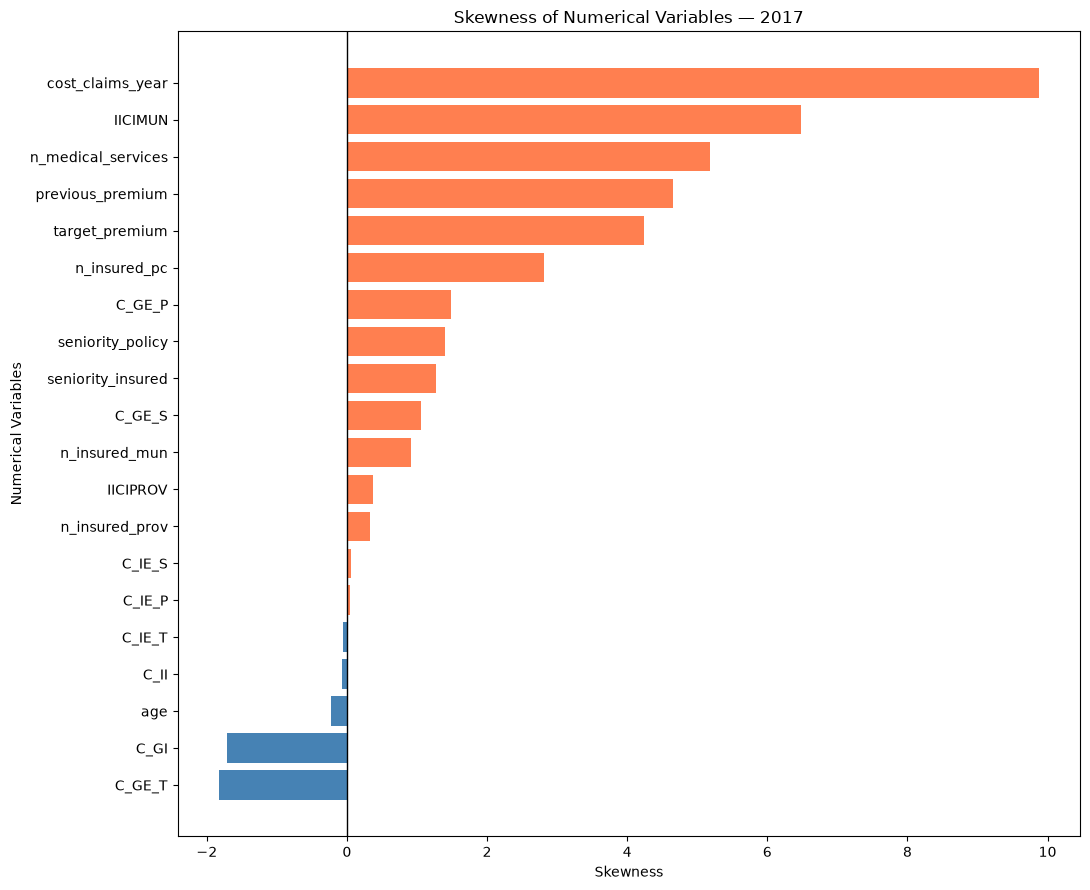

In [54]:
# EDA Step 03.2.3 — Skewness Visualization
#
# Research Question:
# Which numerical variables exhibit the strongest
# positive or negative skewness?
#
# Purpose:
# Compare the direction and magnitude of skewness.

skew_plot = shape_summary["Skewness"].sort_values()

plt.figure(figsize=(11, 9))

colors = [
    "steelblue" if value < 0 else "coral"
    for value in skew_plot
]

plt.barh(
    skew_plot.index,
    skew_plot.values,
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Skewness")
plt.ylabel("Numerical Variables")
plt.title("Skewness of Numerical Variables — 2017")

plt.tight_layout()
plt.show()

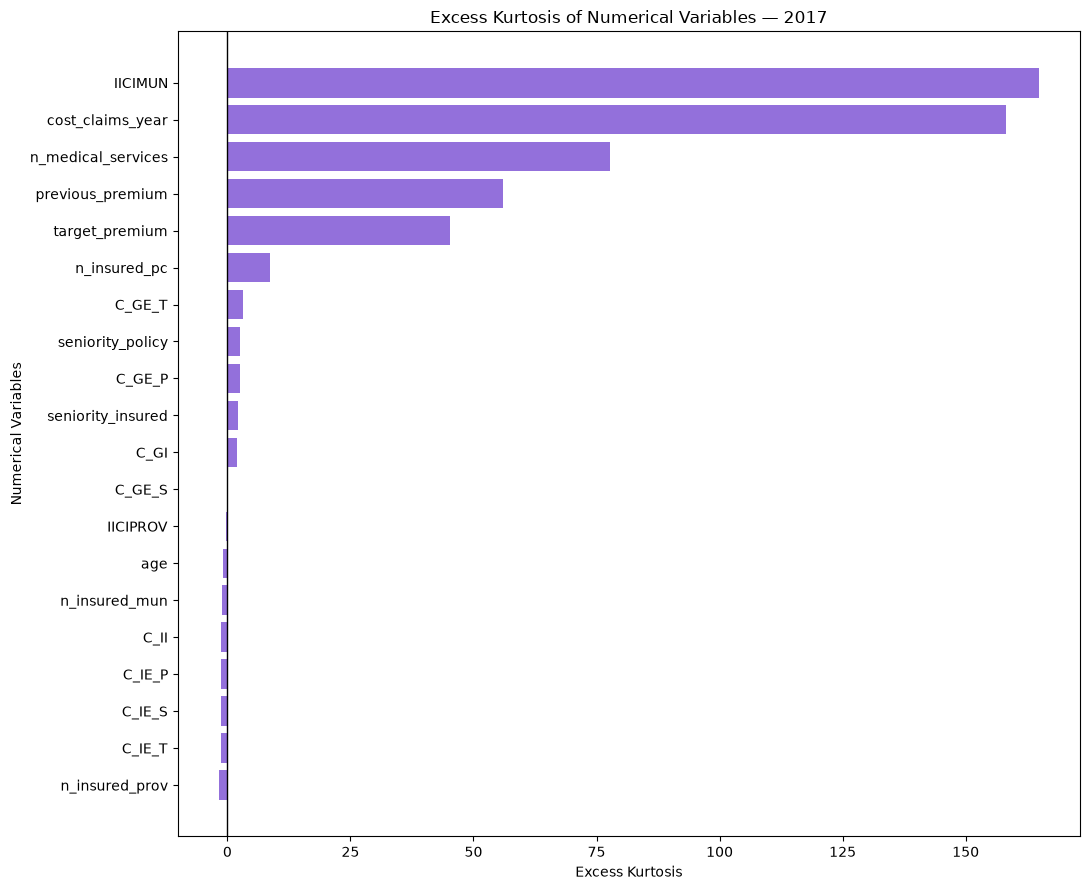

In [55]:
# EDA Step 03.2.4 — Kurtosis Visualization
#
# Research Question:
# Which variables exhibit unusually high
# excess kurtosis?
#
# Purpose:
# Identify variables with extreme-tail behavior.

kurt_plot = (
    shape_summary["Excess Kurtosis"]
    .sort_values()
)

plt.figure(figsize=(11, 9))

plt.barh(
    kurt_plot.index,
    kurt_plot.values,
    color="mediumpurple"
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Excess Kurtosis")
plt.ylabel("Numerical Variables")
plt.title("Excess Kurtosis of Numerical Variables — 2017")

plt.tight_layout()
plt.show()

The dataset contains several strongly skewed numerical variables and distributions with extreme upper-tail observations. 

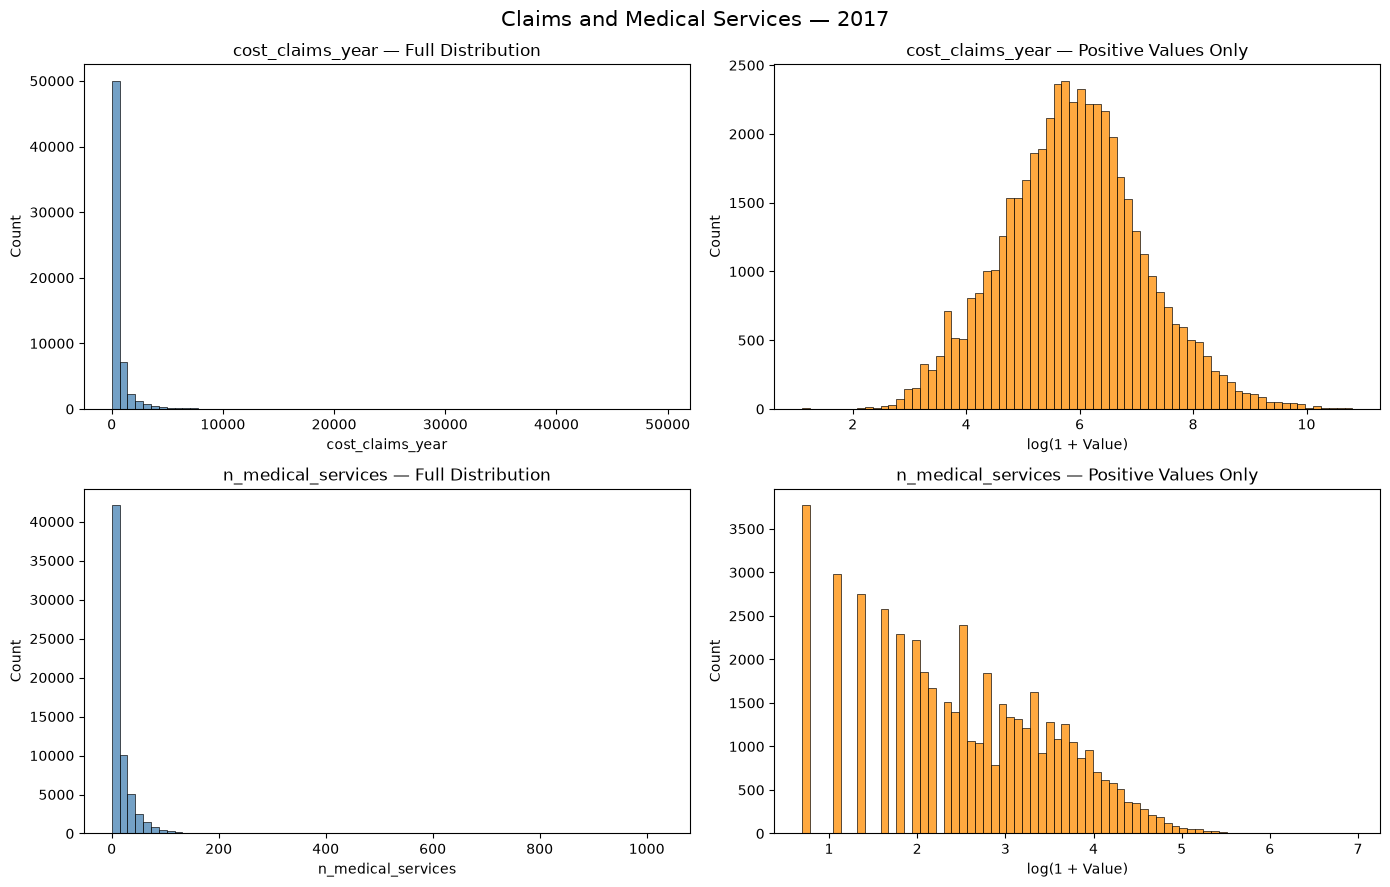

In [56]:
# EDA Step 03.3.2 — Claims and Medical Services
#
# Research Question:
# How are claims expenditure and medical-service
# counts distributed?
#
# Purpose:
# Examine zero-heavy distributions and positive
# values separately.

healthcare_columns = [
    "cost_claims_year",
    "n_medical_services"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, column in enumerate(healthcare_columns):

    values = development_df[column].dropna()
    positive_values = values[values > 0]

    # Full distribution
    sns.histplot(
        values,
        bins=70,
        ax=axes[i, 0],
        color="steelblue"
    )

    axes[i, 0].set_title(
        f"{column} — Full Distribution"
    )

    # Positive values on log-transformed scale
    sns.histplot(
        np.log1p(positive_values),
        bins=70,
        ax=axes[i, 1],
        color="darkorange"
    )

    axes[i, 1].set_title(
        f"{column} — Positive Values Only"
    )

    axes[i, 1].set_xlabel("log(1 + Value)")

plt.suptitle(
    "Claims and Medical Services — 2017",
    fontsize=15
)

plt.tight_layout()
plt.show()

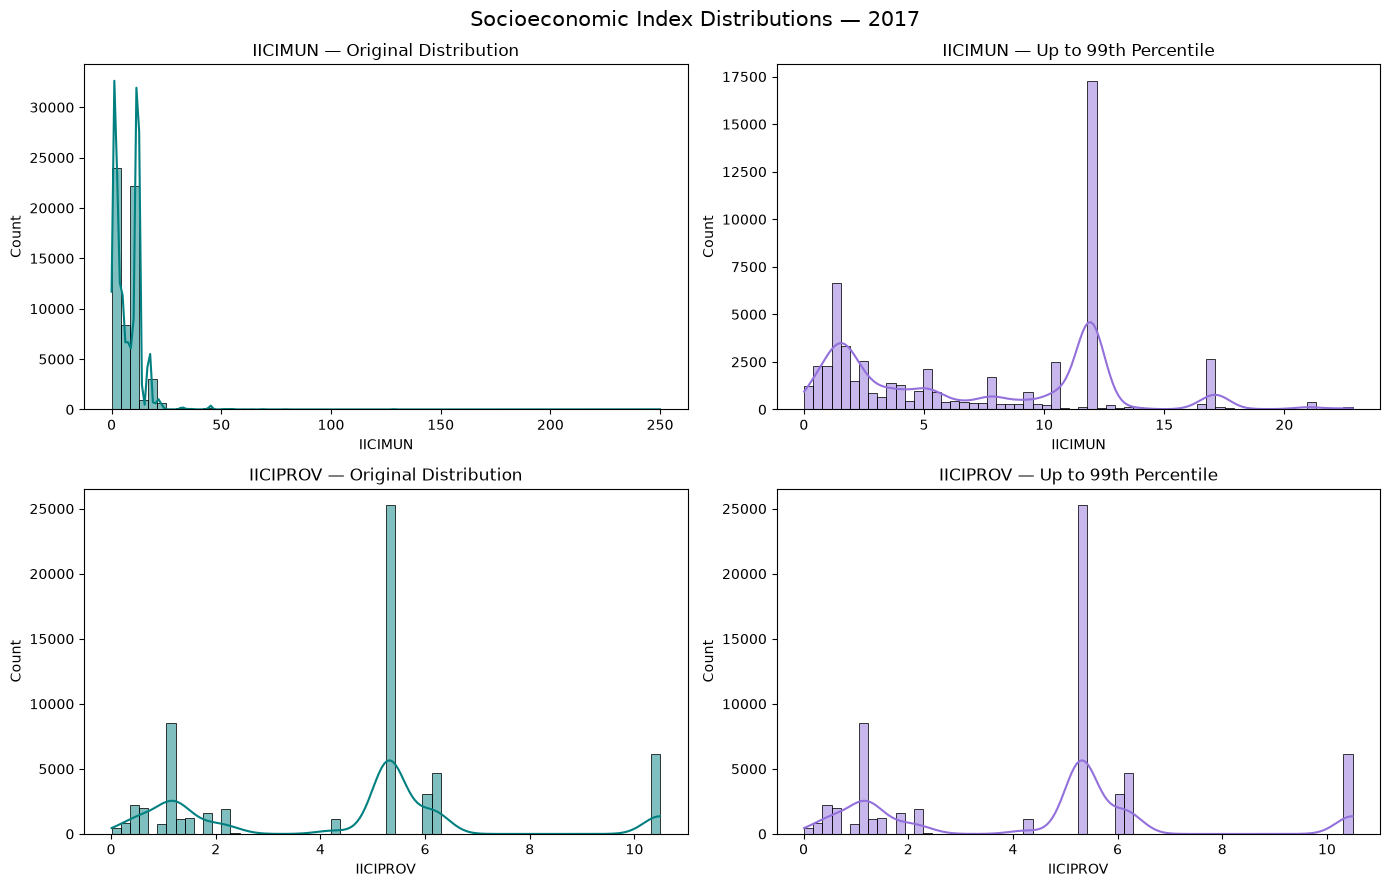

In [57]:
# EDA Step 03.3.3 — Socioeconomic Index Distributions
#
# Research Question:
# How are IICIMUN and IICIPROV distributed?
#
# Purpose:
# Examine distribution shapes and extreme
# values without modifying observations.

socioeconomic_columns = [
    "IICIMUN",
    "IICIPROV"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, column in enumerate(socioeconomic_columns):

    values = development_df[column].dropna()

    # Original distribution
    sns.histplot(
        values,
        bins=60,
        kde=True,
        ax=axes[i, 0],
        color="teal"
    )

    axes[i, 0].set_title(
        f"{column} — Original Distribution"
    )

    # Focus on central 99% of observed values
    upper_limit = values.quantile(0.99)

    sns.histplot(
        values[values <= upper_limit],
        bins=60,
        kde=True,
        ax=axes[i, 1],
        color="mediumpurple"
    )

    axes[i, 1].set_title(
        f"{column} — Up to 99th Percentile"
    )

plt.suptitle(
    "Socioeconomic Index Distributions — 2017",
    fontsize=15
)

plt.tight_layout()
plt.show()

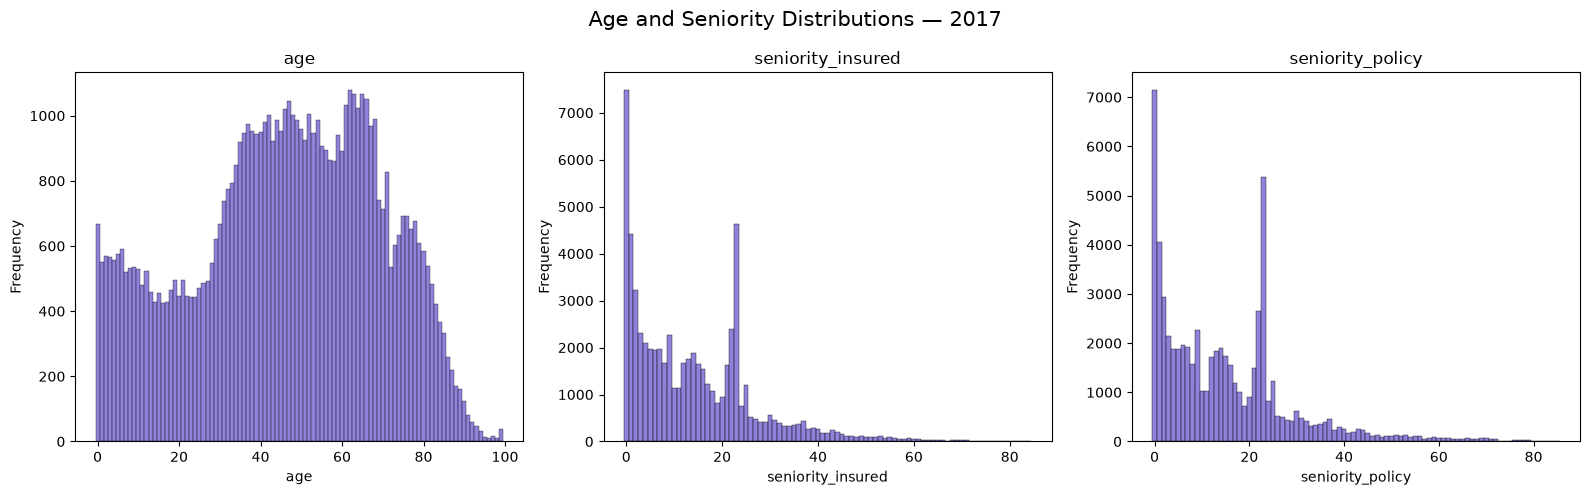

In [58]:
# EDA Step 03.3.4 — Age and Seniority
#
# Research Question:
# What are the distribution shapes of age,
# insured seniority, and policy seniority?
#
# Purpose:
# Examine discrete numerical distributions.

demographic_columns = [
    "age",
    "seniority_insured",
    "seniority_policy"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column in zip(axes, demographic_columns):

    sns.histplot(
        development_df[column].dropna(),
        discrete=True,
        ax=ax,
        color="slateblue"
    )

    ax.set_title(column)
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Age and Seniority Distributions — 2017",
    fontsize=15
)

plt.tight_layout()
plt.show()

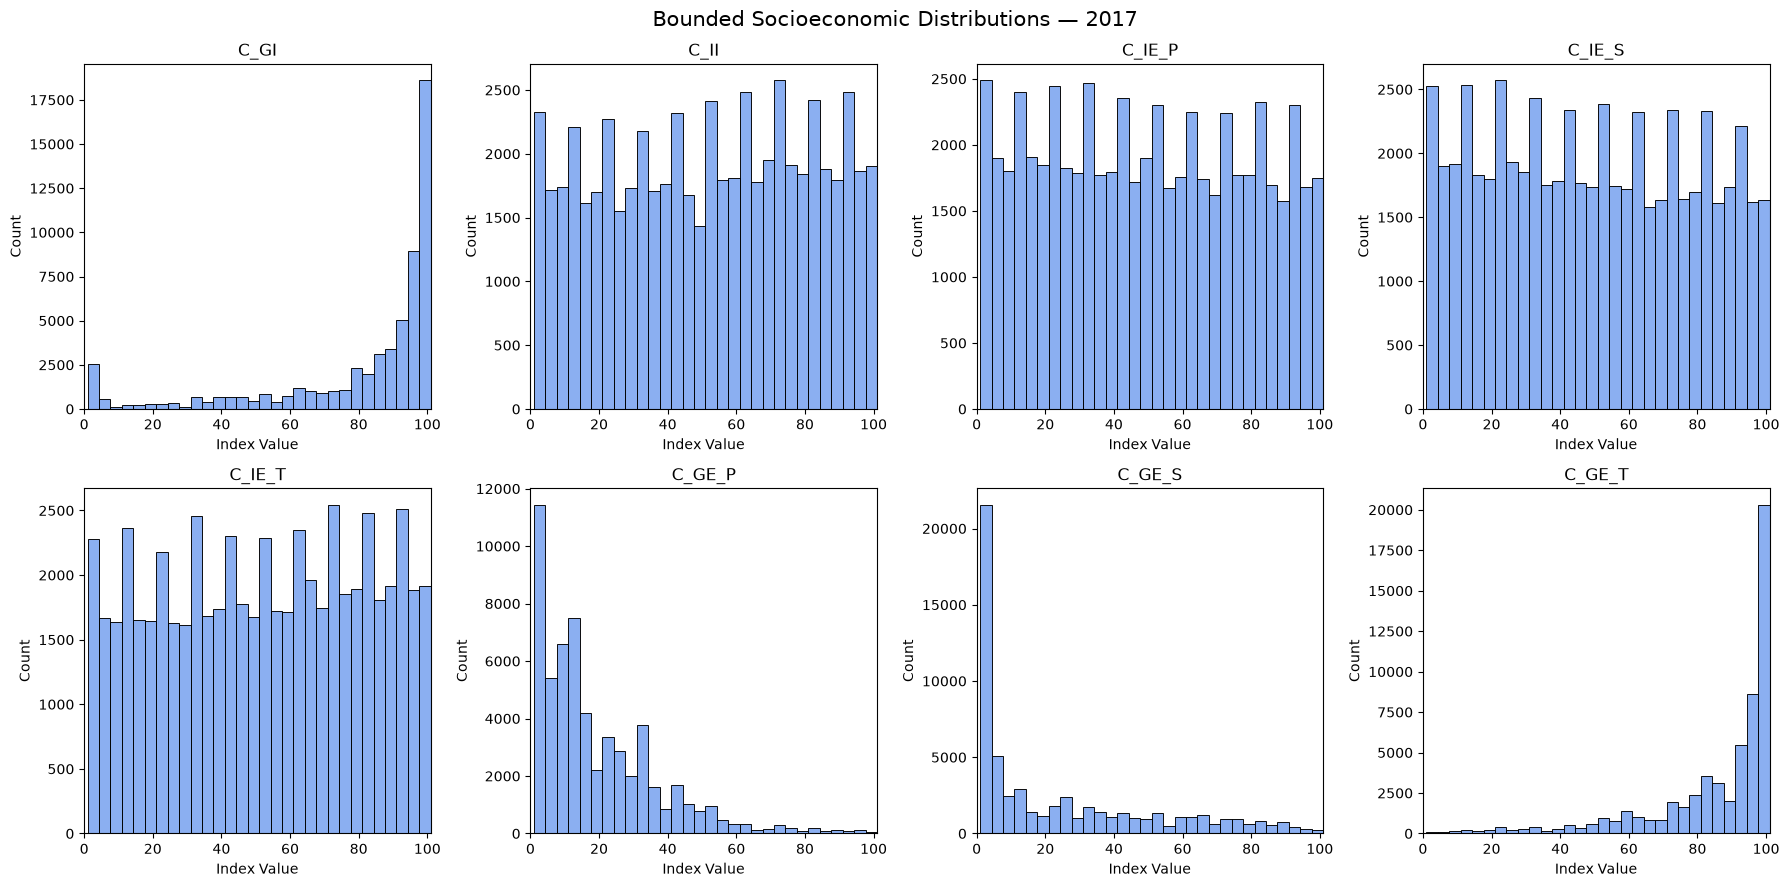

In [59]:
# EDA Step 03.3.5 — Bounded Socioeconomic Variables
#
# Research Question:
# How are the bounded socioeconomic indicators
# distributed between 1 and 100?
#
# Purpose:
# Examine concentration, asymmetry,
# and possible boundary effects.

bounded_columns = [
    "C_GI", "C_II",
    "C_IE_P", "C_IE_S", "C_IE_T",
    "C_GE_P", "C_GE_S", "C_GE_T"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for ax, column in zip(axes.flat, bounded_columns):

    sns.histplot(
        development_df[column].dropna(),
        bins=30,
        binrange=(1, 101),
        ax=ax,
        color="cornflowerblue"
    )

    ax.set_title(column)
    ax.set_xlim(0, 101)
    ax.set_xlabel("Index Value")

plt.suptitle(
    "Bounded Socioeconomic Distributions — 2017",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [60]:
     # Stage 02 — Discrete Numerical Frequencies
#
# Research Question:
# Which discrete numerical values occur most frequently?
#
# Purpose:
# Identify dominant values, concentrations, and
# frequency patterns without modifying the dataset.

discrete_columns = [
    "age",
    "seniority_insured",
    "seniority_policy",
    "n_medical_services",
    "n_insured_pc",
    "n_insured_mun",
    "n_insured_prov",
    "exposure_time"
]

discrete_summary = []

for column in discrete_columns:

    counts = development_df[column].value_counts(dropna=False)

    most_common_value = counts.index[0]
    most_common_count = counts.iloc[0]

    discrete_summary.append({
        "Variable": column,
        "Unique Values": development_df[column].nunique(),
        "Most Frequent Value": most_common_value,
        "Frequency": most_common_count,
        "Percentage (%)": round(
            most_common_count / len(development_df) * 100, 2
        )
    })

discrete_summary_df = pd.DataFrame(discrete_summary)

display(discrete_summary_df)

,Variable,Unique Values,Most Frequent Value,Frequency,Percentage (%)
0,age,100,62.0,1079,1.70
1,seniority_insured,85,0.0,7486,11.80
2,seniority_policy,86,0.0,7148,11.26
3,n_medical_services,271,0.0,14598,23.01
4,n_insured_pc,215,2518.0,2292,3.61
5,n_insured_mun,172,19315.0,17235,27.16
6,n_insured_prov,50,29465.0,25260,39.81
7,exposure_time,2,1.0,61687,97.21


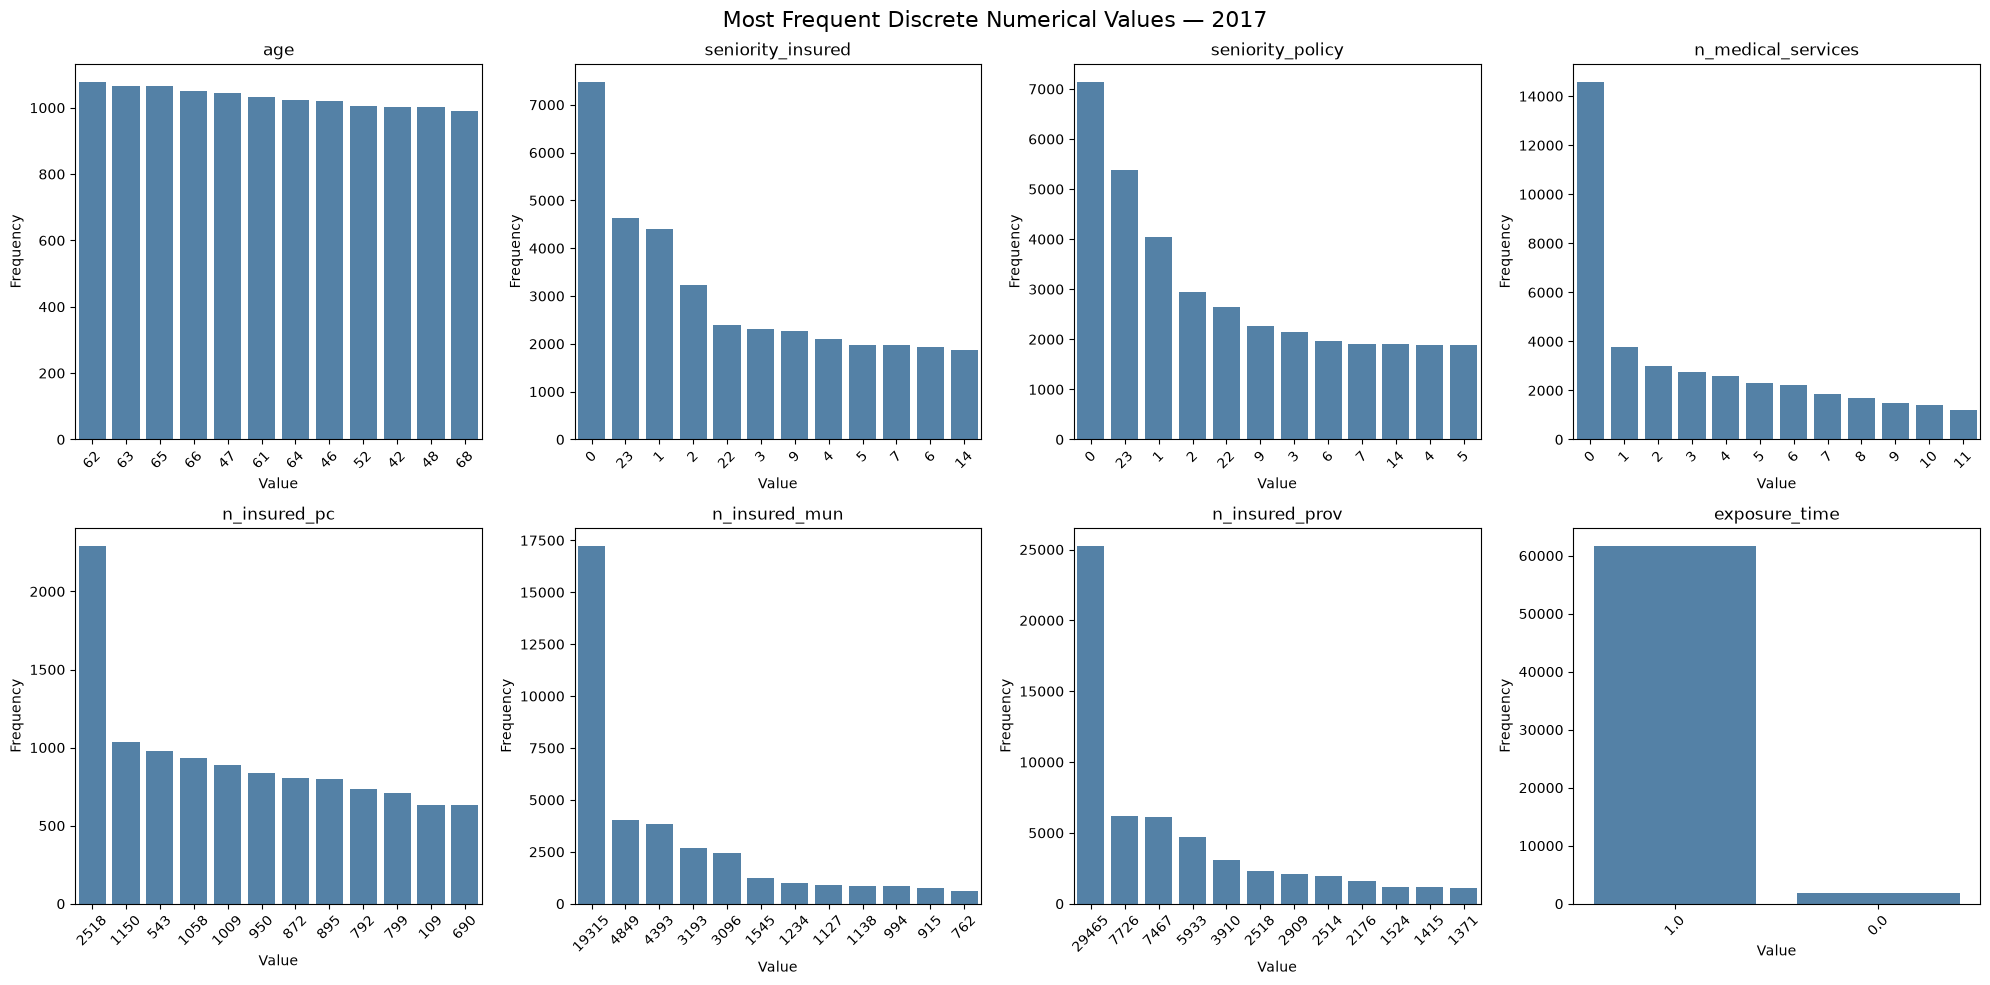

In [61]:
# Stage 02 — Discrete Frequency Visualization
#
# Research Question:
# Which exact numerical values dominate each
# discrete variable?
#
# Purpose:
# Visualize the most common values without
# repeating previous histograms.

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for ax, column in zip(axes.flat, discrete_columns):

    top_values = (
        development_df[column]
        .value_counts()
        .head(12)
    )

    sns.barplot(
        x=[str(v) for v in top_values.index],
        y=top_values.values,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(column)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle(
    "Most Frequent Discrete Numerical Values — 2017",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [62]:
# Stage 02 — Rare Discrete Values
#
# Research Question:
# How many distinct numerical values occur
# only once or twice?
#
# Purpose:
# Summarize rare exact-value frequencies
# without classifying them as outliers.

rare_value_summary = []

for column in discrete_columns:

    counts = development_df[column].value_counts()

    rare_value_summary.append({
        "Variable": column,
        "Unique Values": len(counts),
        "Values Occurring Once": (counts == 1).sum(),
        "Values Occurring Twice": (counts == 2).sum(),
        "Observations in Singleton Values": counts[
            counts == 1
        ].sum()
    })

display(pd.DataFrame(rare_value_summary))

,Variable,Unique Values,Values Occurring Once,Values Occurring Twice,Observations in Singleton Values
0,age,100,0,0,0
1,seniority_insured,85,0,1,0
2,seniority_policy,86,1,0,1
3,n_medical_services,271,56,32,56
4,n_insured_pc,215,0,0,0
5,n_insured_mun,172,0,0,0
6,n_insured_prov,50,0,0,0
7,exposure_time,2,0,0,0


## Target Premium Distribution

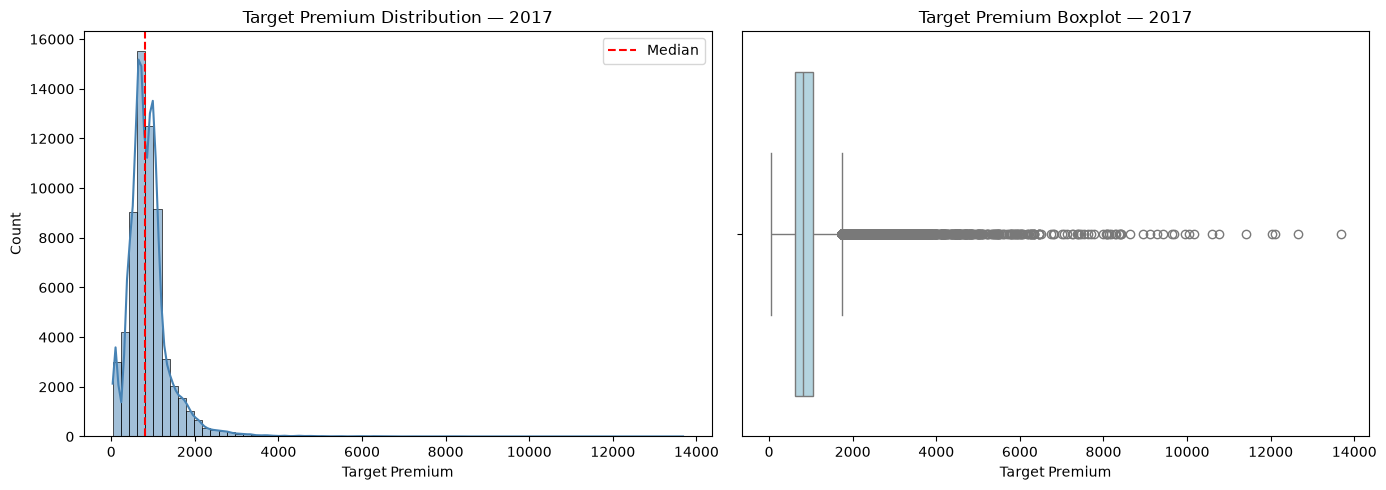

In [63]:
# Stage 03.1 — Target Premium Distribution
#
# Research Question:
# What is the shape and spread of target premiums?
#
# Purpose:
# Examine distribution, concentration, and
# unusually high premiums.

target = development_df["target_premium"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    target,
    bins=70,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].axvline(
    target.median(),
    color="red",
    linestyle="--",
    label="Median"
)

axes[0].set_title("Target Premium Distribution — 2017")
axes[0].set_xlabel("Target Premium")
axes[0].legend()

sns.boxplot(
    x=target,
    color="lightblue",
    ax=axes[1]
)

axes[1].set_title("Target Premium Boxplot — 2017")
axes[1].set_xlabel("Target Premium")

plt.tight_layout()
plt.show()

In [64]:
# Stage 03.1 — Target Validity and Tail Summary
#
# Research Question:
# Are there zero, negative, or unusually
# high target premiums?
#
# Purpose:
# Quantify target validity and upper-tail
# observations without removing them.

target_summary = pd.DataFrame({
    "Metric": [
        "Total Observations",
        "Missing Premiums",
        "Zero Premiums",
        "Negative Premiums",
        "Below 100",
        "Above 95th Percentile",
        "Above 99th Percentile",
        "Minimum",
        "Median",
        "95th Percentile",
        "99th Percentile",
        "Maximum"
    ],
    "Value": [
        len(development_df),
        development_df["target_premium"].isna().sum(),
        (target == 0).sum(),
        (target < 0).sum(),
        (target < 100).sum(),
        (target > target.quantile(0.95)).sum(),
        (target > target.quantile(0.99)).sum(),
        target.min(),
        target.median(),
        target.quantile(0.95),
        target.quantile(0.99),
        target.max()
    ]
})

display(target_summary)

,Metric,Value
0,Total Observations,63455.0000
1,Missing Premiums,0.0000
2,Zero Premiums,0.0000
3,Negative Premiums,0.0000
4,Below 100,1934.0000
5,Above 95th Percentile,3158.0000
6,Above 99th Percentile,635.0000
7,Minimum,34.3400
8,Median,813.0500
9,95th Percentile,1805.4000


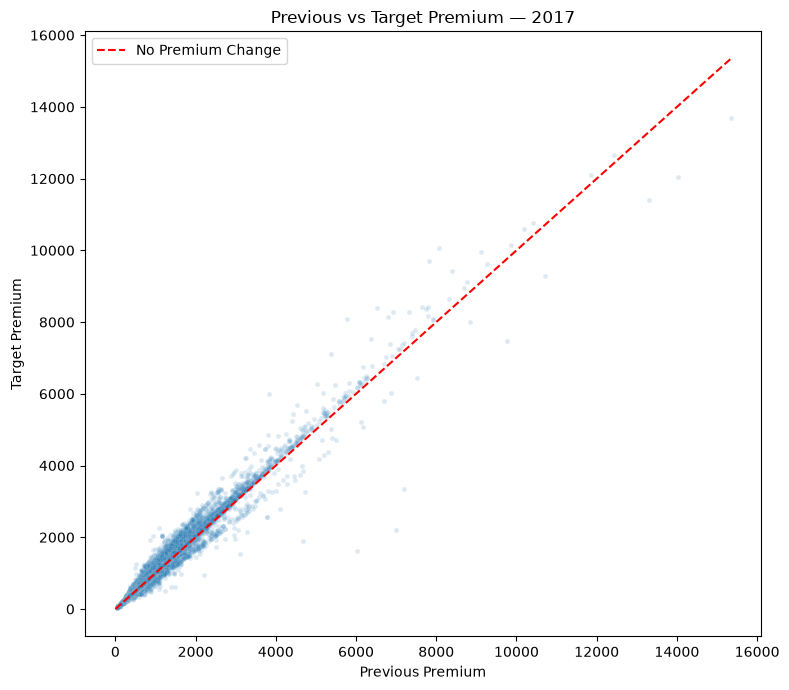

In [65]:
# Stage 03.2 — Previous vs Target Premium
#
# Research Question:
# How closely do previous and target premiums align?
#
# Purpose:
# Visualize renewal premium relationships and
# deviations from unchanged premiums.

premium_pair = development_df[
    ["previous_premium", "target_premium"]
].dropna()

plt.figure(figsize=(8, 7))

sns.scatterplot(
    data=premium_pair,
    x="previous_premium",
    y="target_premium",
    alpha=0.15,
    s=12
)

upper_limit = max(
    premium_pair["previous_premium"].max(),
    premium_pair["target_premium"].max()
)

plt.plot(
    [0, upper_limit],
    [0, upper_limit],
    color="red",
    linestyle="--",
    label="No Premium Change"
)

plt.xlabel("Previous Premium")
plt.ylabel("Target Premium")
plt.title("Previous vs Target Premium — 2017")
plt.legend()
plt.tight_layout()
plt.show()

In [66]:
# Stage 03.2 — Premium Correlation
#
# Research Question:
# How strong are the linear and monotonic
# relationships between premiums?
#
# Purpose:
# Calculate Pearson and Spearman correlations.

premium_correlations = pd.DataFrame({
    "Correlation": ["Pearson", "Spearman"],
    "Value": [
        premium_pair["previous_premium"].corr(
            premium_pair["target_premium"],
            method="pearson"
        ),
        premium_pair["previous_premium"].corr(
            premium_pair["target_premium"],
            method="spearman"
        )
    ]
})

display(premium_correlations.round(4))

,Correlation,Value
0,Pearson,0.9871
1,Spearman,0.9875


In [67]:
# Stage 03.3 — Renewal Premium Changes
#
# Research Question:
# How much do premiums change at renewal?
#
# Purpose:
# Calculate absolute and percentage changes
# without modifying development_df.

renewal_df = premium_pair.copy()

renewal_df["absolute_change"] = (
    renewal_df["target_premium"] -
    renewal_df["previous_premium"]
)

renewal_df["percentage_change"] = np.where(
    renewal_df["previous_premium"] > 0,
    renewal_df["absolute_change"] /
    renewal_df["previous_premium"] * 100,
    np.nan
)

display(
    renewal_df[
        ["absolute_change", "percentage_change"]
    ].describe(
        percentiles=[
            0.01, 0.05, 0.25,
            0.50, 0.75, 0.95, 0.99
        ]
    ).T.round(3)
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
absolute_change,63455.0,44.339,91.344,-4810.630,-141.580,-21.210,14.26,33.660,62.65,157.560,348.969,2316.420
percentage_change,63455.0,4.973,7.748,-73.054,-14.314,-6.931,2.02,4.015,7.96,18.719,31.259,137.812


,Direction,Count,Percentage (%)
0,Increase,53095,83.67
1,Decrease,8538,13.46
2,Unchanged,1822,2.87


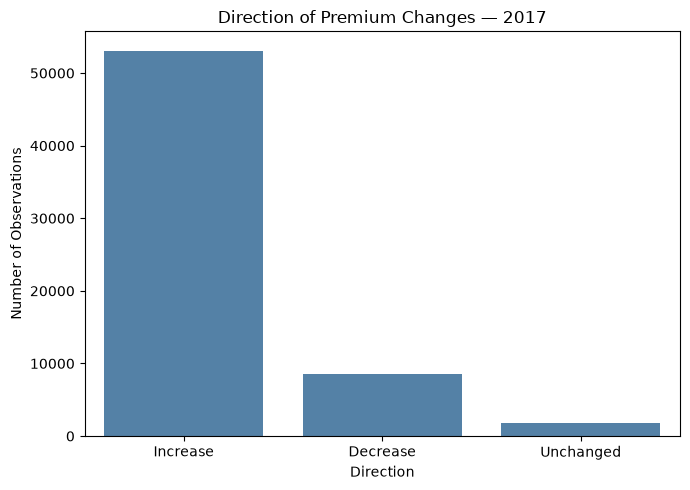

In [68]:
# Stage 03.3 — Renewal Direction
#
# Research Question:
# What proportion of premiums increase,
# decrease, or remain unchanged?
#
# Purpose:
# Summarize renewal adjustment directions.

renewal_df["change_direction"] = np.select(
    [
        renewal_df["absolute_change"] > 0,
        renewal_df["absolute_change"] < 0
    ],
    [
        "Increase",
        "Decrease"
    ],
    default="Unchanged"
)

direction_summary = (
    renewal_df["change_direction"]
    .value_counts()
    .rename_axis("Direction")
    .reset_index(name="Count")
)

direction_summary["Percentage (%)"] = (
    direction_summary["Count"] /
    len(renewal_df) * 100
).round(2)

display(direction_summary)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=direction_summary,
    x="Direction",
    y="Count",
    color="steelblue"
)

plt.title("Direction of Premium Changes — 2017")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

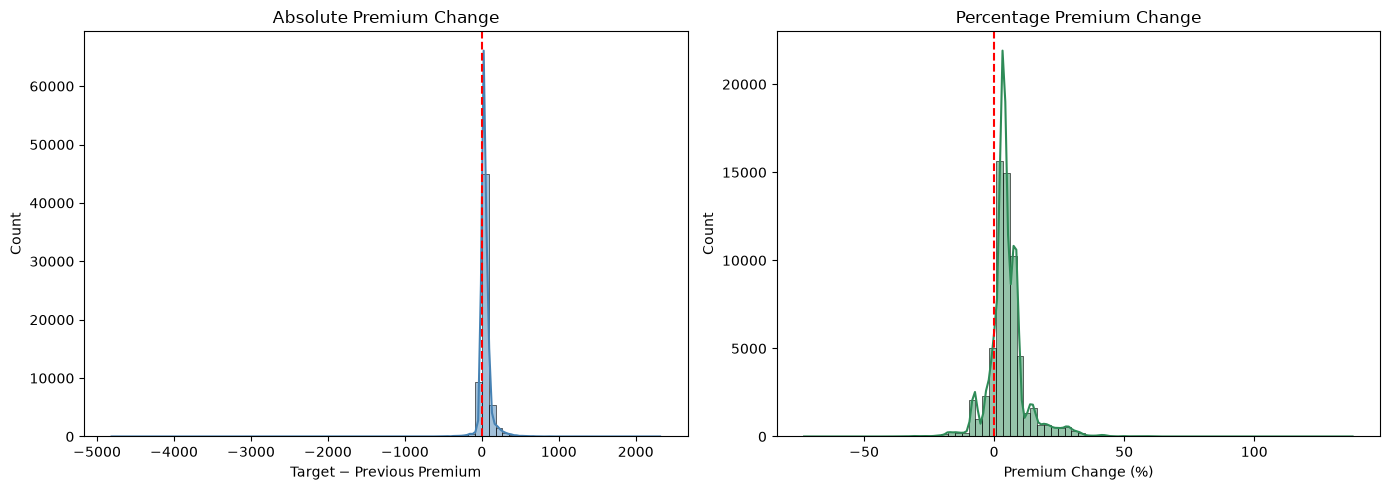

In [69]:
# Stage 03.4 — Premium Change Distributions
#
# Research Question:
# What are the distributions of absolute
# and percentage premium changes?
#
# Purpose:
# Examine asymmetry and extreme adjustments.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    renewal_df["absolute_change"],
    bins=80,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Absolute Premium Change")
axes[0].set_xlabel("Target − Previous Premium")

sns.histplot(
    renewal_df["percentage_change"].dropna(),
    bins=80,
    kde=True,
    color="seagreen",
    ax=axes[1]
)

axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Percentage Premium Change")
axes[1].set_xlabel("Premium Change (%)")

plt.tight_layout()
plt.show()

## Medical Utilisation and claim analysis 

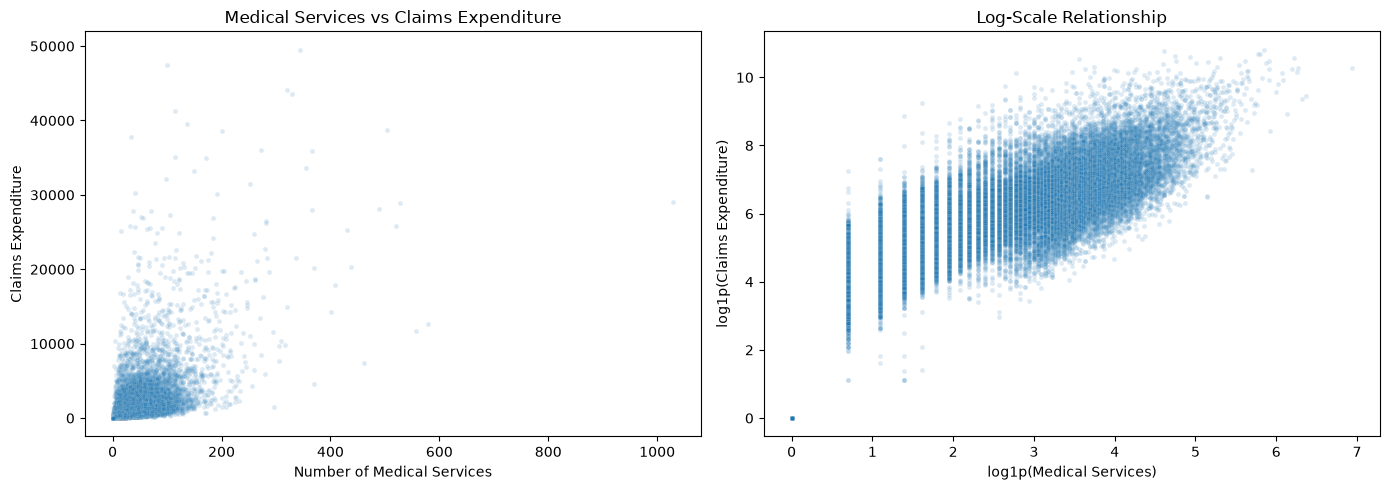

,cost_claims_year,n_medical_services
cost_claims_year,1.000,0.916
n_medical_services,0.916,1.000


In [70]:
# Step 04.1 — Claims vs Medical Services
#
# Research Question:
# Do more medical services correspond to higher claims costs?
#
# Purpose:
# Examine the relationship between service utilization
# and claims expenditure without modifying the dataset.

claims_df = development_df[
    [
        "cost_claims_year",
        "n_medical_services",
        "previous_premium",
        "target_premium"
    ]
].dropna().copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=claims_df,
    x="n_medical_services",
    y="cost_claims_year",
    alpha=0.15,
    s=12,
    ax=axes[0]
)

axes[0].set_title("Medical Services vs Claims Expenditure")
axes[0].set_xlabel("Number of Medical Services")
axes[0].set_ylabel("Claims Expenditure")

sns.scatterplot(
    x=np.log1p(claims_df["n_medical_services"]),
    y=np.log1p(claims_df["cost_claims_year"]),
    alpha=0.15,
    s=12,
    ax=axes[1]
)

axes[1].set_title("Log-Scale Relationship")
axes[1].set_xlabel("log1p(Medical Services)")
axes[1].set_ylabel("log1p(Claims Expenditure)")

plt.tight_layout()
plt.show()

display(
    claims_df[
        ["cost_claims_year", "n_medical_services"]
    ].corr(method="spearman").round(4)
)

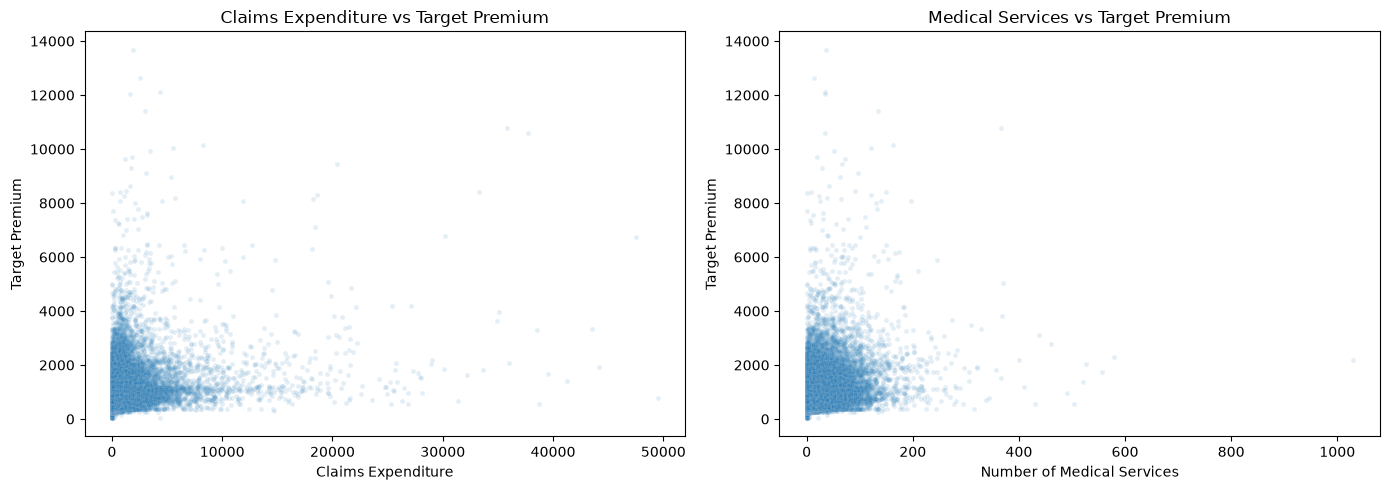

In [71]:
# Step 04.2 — Claims and Services vs Target Premium
#
# Research Question:
# How do claims expenditure and medical-service
# utilization relate to target_premium?
#
# Purpose:
# Examine potential nonlinear relationships
# and the influence of extreme values.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=claims_df,
    x="cost_claims_year",
    y="target_premium",
    alpha=0.12,
    s=12,
    ax=axes[0]
)

axes[0].set_title("Claims Expenditure vs Target Premium")
axes[0].set_xlabel("Claims Expenditure")
axes[0].set_ylabel("Target Premium")

sns.scatterplot(
    data=claims_df,
    x="n_medical_services",
    y="target_premium",
    alpha=0.12,
    s=12,
    ax=axes[1]
)

axes[1].set_title("Medical Services vs Target Premium")
axes[1].set_xlabel("Number of Medical Services")
axes[1].set_ylabel("Target Premium")

plt.tight_layout()
plt.show()

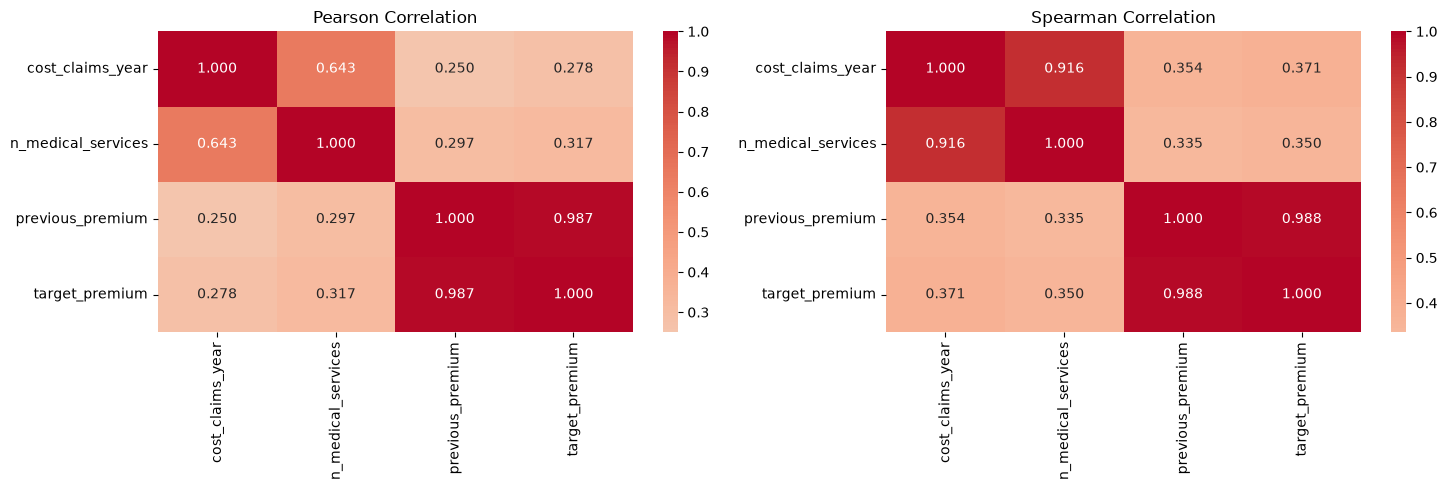

In [72]:
# Step 04.3 — Correlation Analysis
#
# Research Question:
# How strongly are claims, utilization,
# previous premium, and target premium related?
#
# Purpose:
# Compare Pearson and Spearman associations.

variables = [
    "cost_claims_year",
    "n_medical_services",
    "previous_premium",
    "target_premium"
]

pearson_corr = claims_df[variables].corr(method="pearson")
spearman_corr = claims_df[variables].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    ax=axes[0]
)

axes[0].set_title("Pearson Correlation")

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    ax=axes[1]
)

axes[1].set_title("Spearman Correlation")

plt.tight_layout()
plt.show()

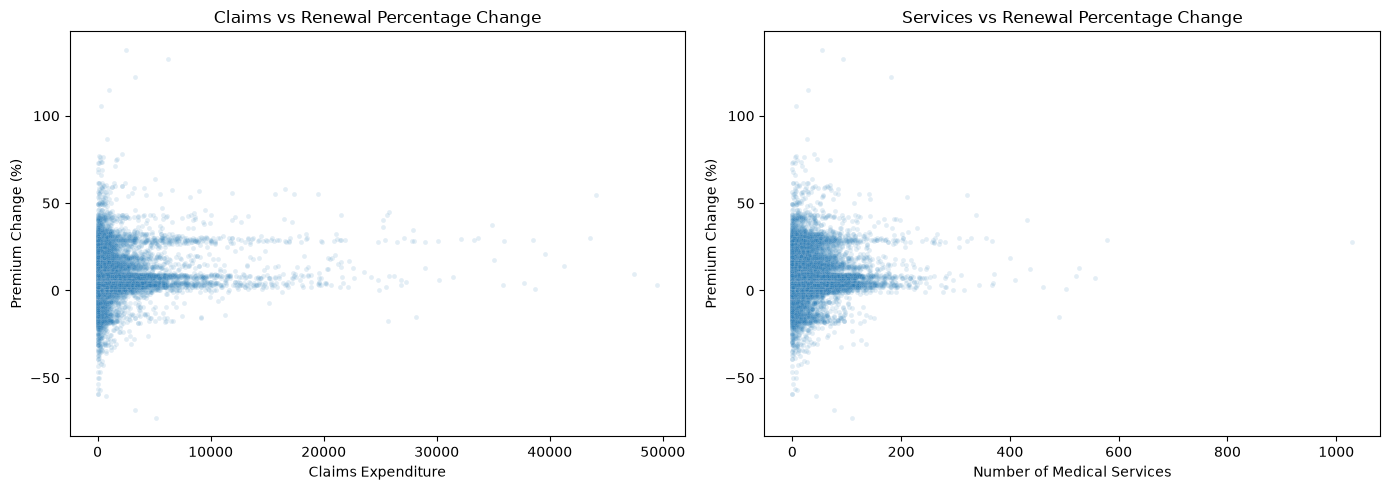

,cost_claims_year,n_medical_services,percentage_change
cost_claims_year,1.0000,0.9160,0.2314
n_medical_services,0.9160,1.0000,0.2149
percentage_change,0.2314,0.2149,1.0000


In [73]:
# Step 04.4 — Claims vs Renewal Changes
#
# Research Question:
# Are claims and utilization associated with
# the magnitude of premium renewal changes?
#
# Purpose:
# Examine potential relationships with
# percentage renewal adjustments.

claims_df["absolute_change"] = (
    claims_df["target_premium"]
    - claims_df["previous_premium"]
)

claims_df["percentage_change"] = (
    claims_df["absolute_change"]
    .div(
        claims_df["previous_premium"].where(
            claims_df["previous_premium"] > 0
        )
    ) * 100
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=claims_df,
    x="cost_claims_year",
    y="percentage_change",
    alpha=0.12,
    s=12,
    ax=axes[0]
)

axes[0].set_title("Claims vs Renewal Percentage Change")
axes[0].set_xlabel("Claims Expenditure")
axes[0].set_ylabel("Premium Change (%)")

sns.scatterplot(
    data=claims_df,
    x="n_medical_services",
    y="percentage_change",
    alpha=0.12,
    s=12,
    ax=axes[1]
)

axes[1].set_title("Services vs Renewal Percentage Change")
axes[1].set_xlabel("Number of Medical Services")
axes[1].set_ylabel("Premium Change (%)")

plt.tight_layout()
plt.show()

display(
    claims_df[
        [
            "cost_claims_year",
            "n_medical_services",
            "percentage_change"
        ]
    ].corr(method="spearman").round(4)
)

In [74]:
# Step 04.5 — Utilization Groups
#
# Research Question:
# Does renewal behavior differ by medical utilization?
#
# Purpose:
# Compare renewal changes across groups
# without applying permanent binning.

positive_services = claims_df.loc[
    claims_df["n_medical_services"] > 0,
    "n_medical_services"
]

q50 = positive_services.quantile(0.50)
q90 = positive_services.quantile(0.90)

claims_df["utilization_group"] = np.select(
    [
        claims_df["n_medical_services"] == 0,
        claims_df["n_medical_services"] <= q50,
        claims_df["n_medical_services"] <= q90
    ],
    [
        "No Utilization",
        "Low Utilization",
        "Moderate Utilization"
    ],
    default="High Utilization"
)

utilization_summary = (
    claims_df
    .groupby("utilization_group")
    .agg(
        Count=("percentage_change", "size"),
        Median_Claims=("cost_claims_year", "median"),
        Median_Target_Premium=("target_premium", "median"),
        Median_Renewal_Change=("percentage_change", "median"),
        Mean_Renewal_Change=("percentage_change", "mean")
    )
)

display(utilization_summary.round(3))

,Count,Median_Claims,Median_Target_Premium,Median_Renewal_Change,Mean_Renewal_Change
utilization_group,,,,,
High Utilization,4873,1801.84,1089.79,5.898,7.718
Low Utilization,25414,175.44,783.76,4.011,4.997
Moderate Utilization,18570,634.36,948.39,4.171,6.118
No Utilization,14598,0.00,656.88,3.007,2.560


In [75]:
# Step 04.6 — Claims Expenditure Groups
#
# Research Question:
# How do renewal changes vary across claims levels?
#
# Purpose:
# Compare zero-claim policies and positive
# claims expenditure groups.

positive_claims = claims_df.loc[
    claims_df["cost_claims_year"] > 0,
    "cost_claims_year"
]

claims_q50 = positive_claims.quantile(0.50)
claims_q90 = positive_claims.quantile(0.90)

claims_df["claims_group"] = np.select(
    [
        claims_df["cost_claims_year"] == 0,
        claims_df["cost_claims_year"] <= claims_q50,
        claims_df["cost_claims_year"] <= claims_q90
    ],
    [
        "No Claims",
        "Low Claims",
        "Moderate Claims"
    ],
    default="High Claims"
)

claims_group_summary = (
    claims_df
    .groupby("claims_group")
    .agg(
        Count=("percentage_change", "size"),
        Median_Services=("n_medical_services", "median"),
        Median_Target_Premium=("target_premium", "median"),
        Median_Renewal_Change=("percentage_change", "median"),
        Mean_Renewal_Change=("percentage_change", "mean")
    )
)

display(claims_group_summary.round(3))

,Count,Median_Services,Median_Target_Premium,Median_Renewal_Change,Mean_Renewal_Change
claims_group,,,,,
High Claims,4885,52.0,1072.02,6.900,8.551
Low Claims,24432,5.0,763.77,3.995,4.830
Moderate Claims,19540,21.0,956.47,4.104,6.061
No Claims,14598,0.0,656.88,3.007,2.560


## Features Relationship


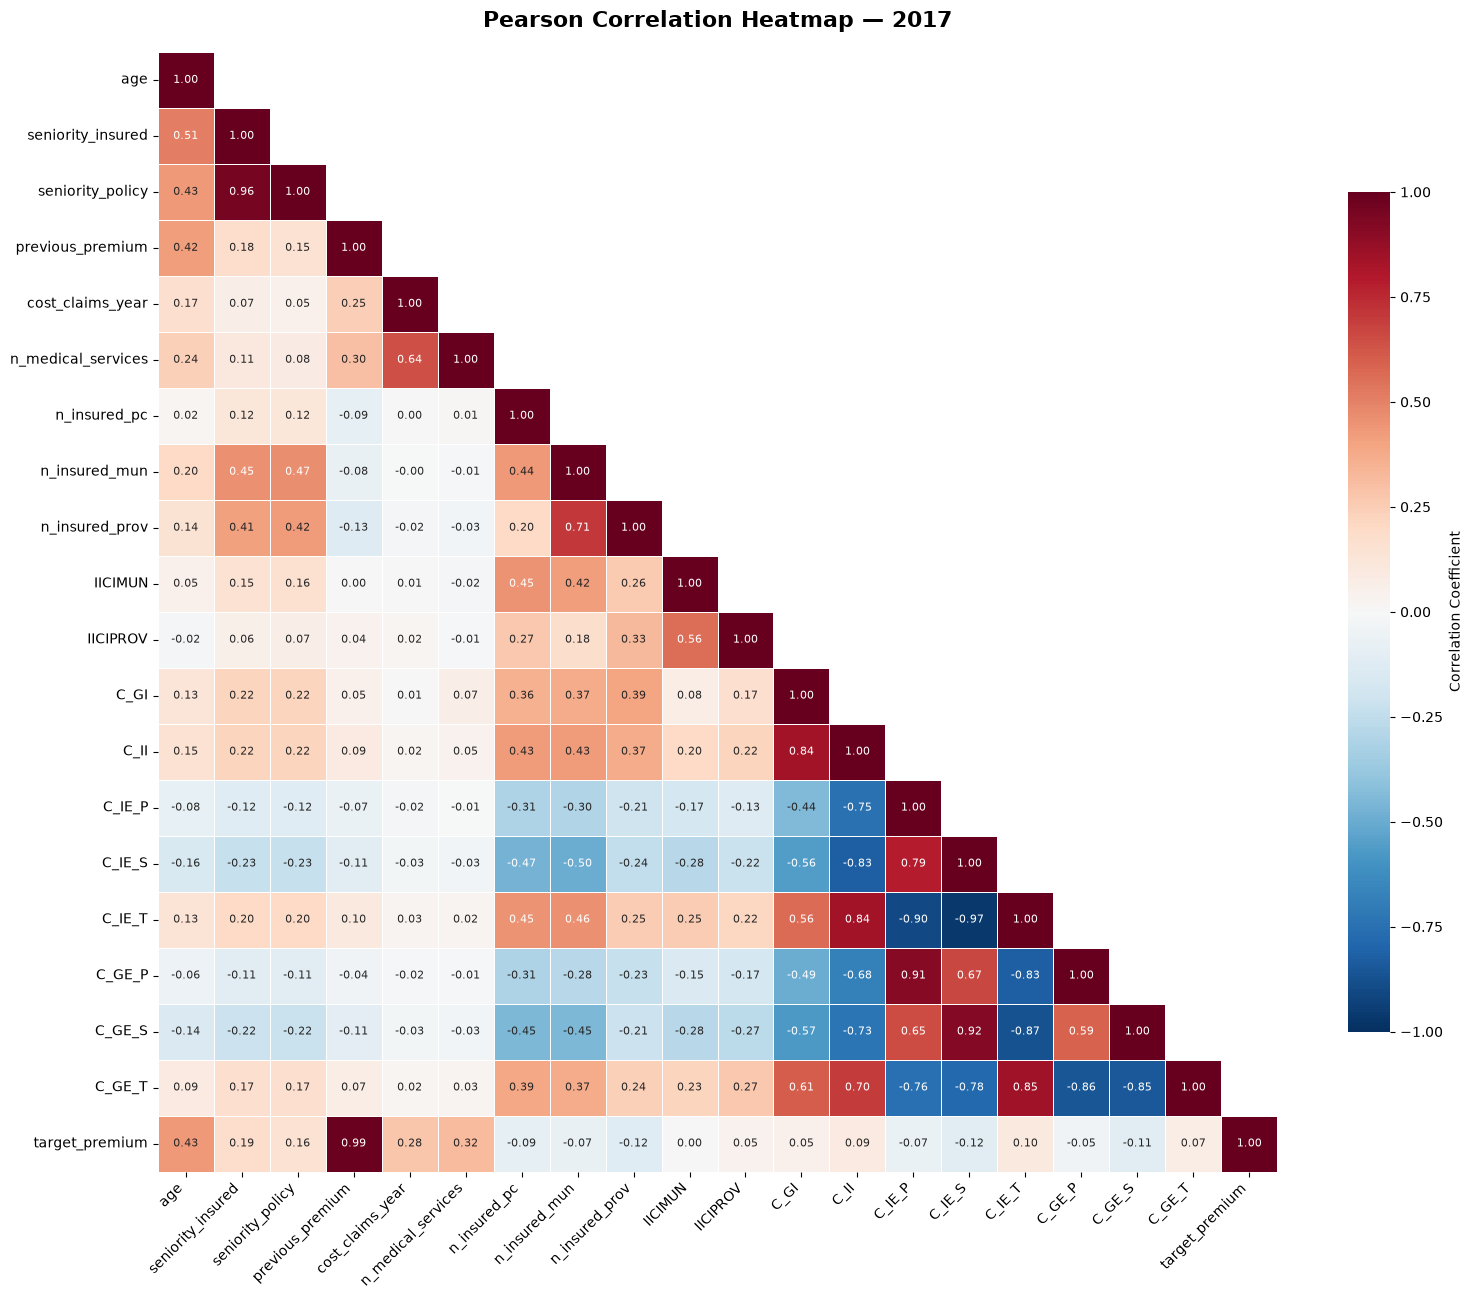

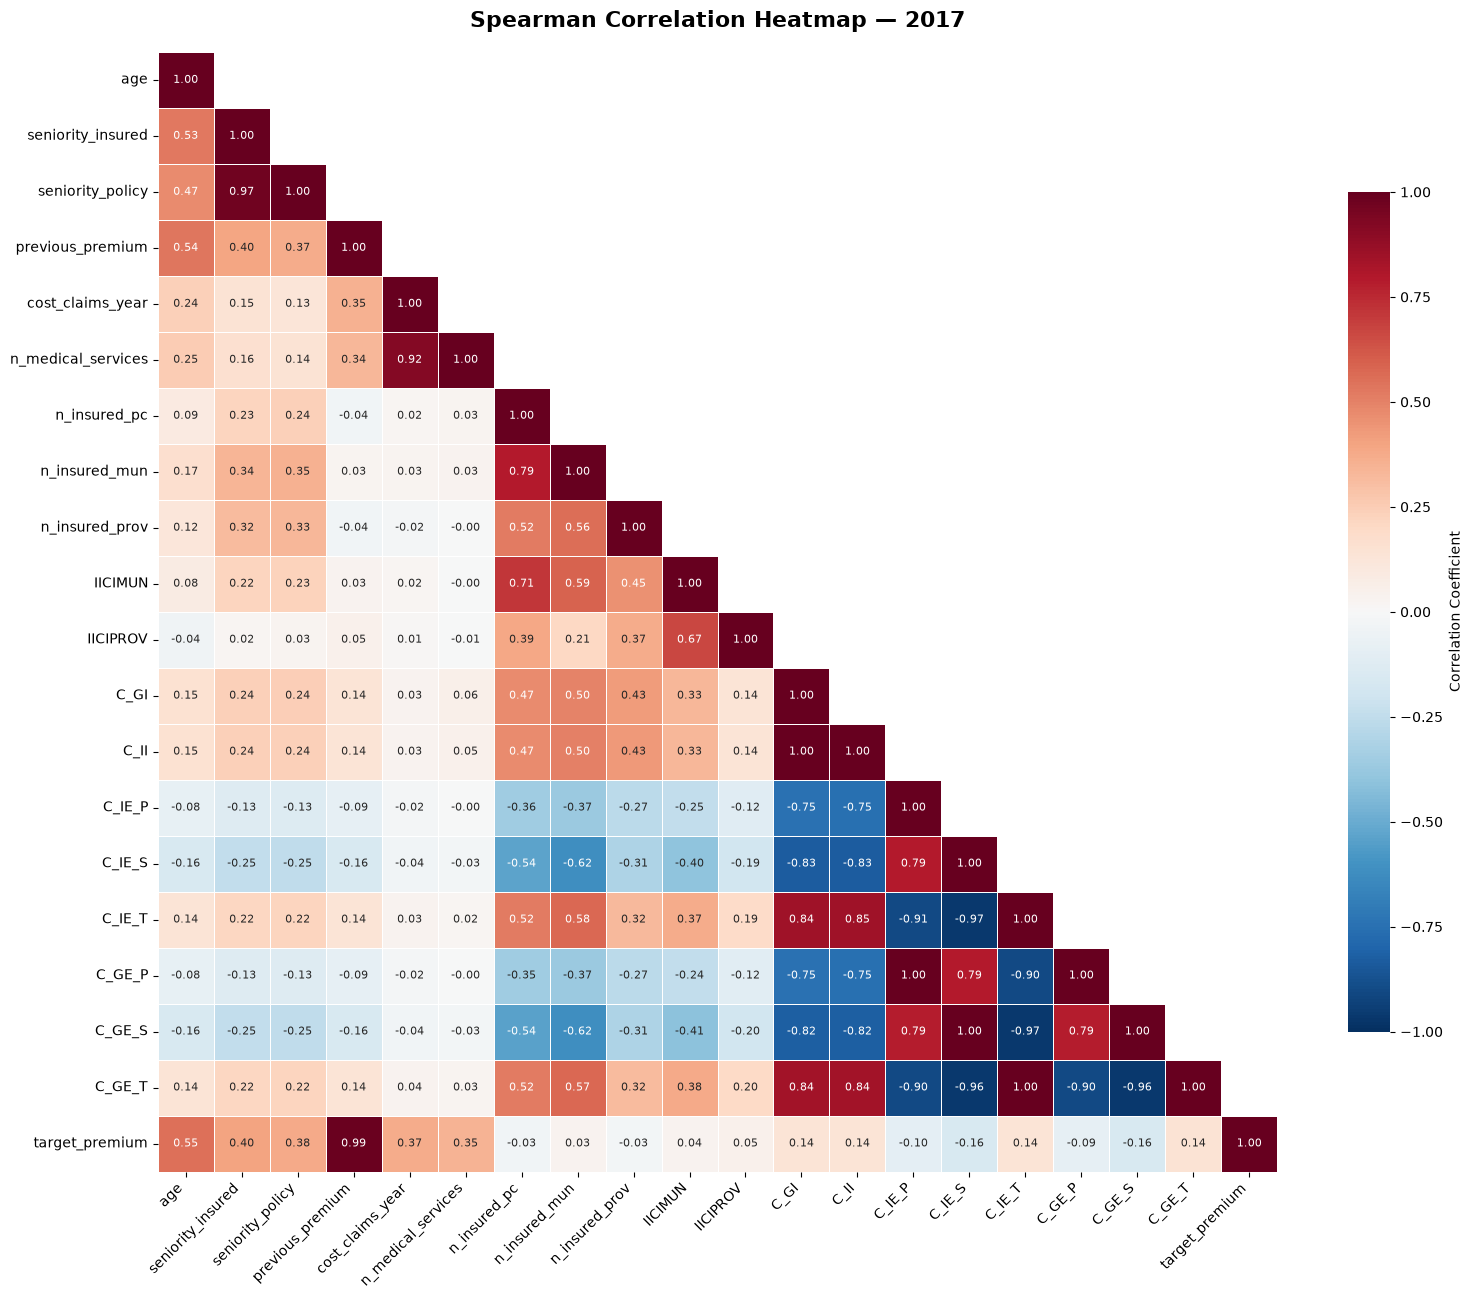

In [76]:
# Step 05.1 — Numerical Feature Correlation Heatmaps
#
# Research Question:
# Which numerical features are associated with each other
# and with target_premium?
#
# Purpose:
# Identify linear/monotonic relationships and potential
# feature redundancy for preprocessing decisions.

numeric_features = [
    "age",
    "seniority_insured",
    "seniority_policy",
    "previous_premium",
    "cost_claims_year",
    "n_medical_services",
    "n_insured_pc",
    "n_insured_mun",
    "n_insured_prov",
    "IICIMUN",
    "IICIPROV",
    "C_GI",
    "C_II",
    "C_IE_P",
    "C_IE_S",
    "C_IE_T",
    "C_GE_P",
    "C_GE_S",
    "C_GE_T",
    "target_premium"
]

numeric_data = development_df[numeric_features].copy()

pearson_corr = numeric_data.corr(method="pearson")
spearman_corr = numeric_data.corr(method="spearman")


# Function for clean, readable correlation heatmaps
def plot_correlation_heatmap(corr_matrix, title):

    plt.figure(figsize=(16, 13))

    mask = np.triu(
        np.ones_like(corr_matrix, dtype=bool),
        k=1
    )

    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.4,
        linecolor="white",
        annot_kws={"size": 8},
        cbar_kws={
            "label": "Correlation Coefficient",
            "shrink": 0.75
        }
    )

    plt.title(title, fontsize=16, fontweight="bold", pad=18)

    plt.xticks(rotation=45, ha="right", fontsize=10)
    plt.yticks(rotation=0, fontsize=10)

    plt.tight_layout()
    plt.show()


# Pearson: Linear relationships
plot_correlation_heatmap(
    pearson_corr,
    "Pearson Correlation Heatmap — 2017"
)

# Spearman: Monotonic relationships
plot_correlation_heatmap(
    spearman_corr,
    "Spearman Correlation Heatmap — 2017"
)

In [77]:
# Step 05.2 — Numerical Target Associations
#
# Research Question:
# Which numerical predictors are most strongly
# associated with target_premium?
#
# Purpose:
# Compare linear and monotonic associations.

target_associations = pd.DataFrame({
    "Pearson": pearson_corr["target_premium"],
    "Spearman": spearman_corr["target_premium"]
}).drop(index="target_premium")

target_associations["Max Absolute Correlation"] = (
    target_associations[["Pearson", "Spearman"]]
    .abs()
    .max(axis=1)
)

target_associations = target_associations.sort_values(
    "Max Absolute Correlation",
    ascending=False
)

display(target_associations.round(4))

,Pearson,Spearman,Max Absolute Correlation
previous_premium,0.9871,0.9875,0.9875
age,0.4313,0.5530,0.5530
seniority_insured,0.1872,0.4029,0.4029
seniority_policy,0.1556,0.3751,0.3751
cost_claims_year,0.2784,0.3710,0.3710
n_medical_services,0.3168,0.3499,0.3499
C_IE_S,-0.1153,-0.1612,0.1612
C_GE_S,-0.1101,-0.1585,0.1585
C_GE_T,0.0738,0.1423,0.1423
C_GI,0.0526,0.1404,0.1404


In [78]:
# Step 05.3 — Potential Feature Redundancy
#
# Research Question:
# Which numerical predictor pairs have
# strong monotonic relationships?
#
# Purpose:
# Flag pairs with |Spearman correlation| >= 0.80.

predictor_corr = spearman_corr.drop(
    index="target_premium",
    columns="target_premium"
)

upper_mask = np.triu(
    np.ones(predictor_corr.shape, dtype=bool),
    k=1
)

strong_pairs = (
    predictor_corr
    .where(upper_mask)
    .stack()
    .reset_index()
)

strong_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Spearman Correlation"
]

strong_pairs = strong_pairs[
    strong_pairs["Spearman Correlation"].abs() >= 0.80
].sort_values(
    "Spearman Correlation",
    key=lambda s: s.abs(),
    ascending=False
)

display(strong_pairs)

,Feature 1,Feature 2,Spearman Correlation
263,C_IE_P,C_GE_P,0.999413
283,C_IE_S,C_GE_S,0.997251
221,C_GI,C_II,0.997126
303,C_IE_T,C_GE_T,0.996068
21,seniority_insured,seniority_policy,0.970505
281,C_IE_S,C_IE_T,-0.968288
302,C_IE_T,C_GE_S,-0.965509
284,C_IE_S,C_GE_T,-0.964602
341,C_GE_S,C_GE_T,-0.964567
81,cost_claims_year,n_medical_services,0.916022


In [79]:
# Step 05.4 — Categorical Target Summary
#
# Research Question:
# Do target premiums differ across categories?
#
# Purpose:
# Compare category frequencies and target
# statistics without applying encoding.

categorical_features = [
    "gender",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "distribution_channel",
    "new_business"
]

for column in categorical_features:

    summary = (
        development_df
        .groupby(column, dropna=False)["target_premium"]
        .agg(["count", "median", "mean", "std"])
        .sort_values("count", ascending=False)
    )

    summary["Percentage (%)"] = (
        summary["count"] / len(development_df) * 100
    )

    print(f"\nFeature: {column}")
    display(summary.round(3))


Feature: gender


,count,median,mean,std,Percentage (%)
gender,,,,,
F,34508,840.32,919.105,565.379,54.382
M,28947,787.44,878.591,559.582,45.618



Feature: type_policy


,count,median,mean,std,Percentage (%)
type_policy,,,,,
I,37306,851.43,978.609,684.830,58.791
C,26149,749.70,789.364,281.615,41.209



Feature: type_policy_dg


,count,median,mean,std,Percentage (%)
type_policy_dg,,,,,
I,28607,923.14,1055.130,747.045,45.082
C3,16291,939.30,884.724,187.243,25.673
SE,8699,669.12,726.966,305.744,13.709
C1,6787,590.58,647.830,362.150,10.696
C4,1790,378.42,421.612,75.582,2.821
C2,1281,849.66,840.378,238.586,2.019


... (2 outputs left out)


Feature: distribution_channel


,count,median,mean,std,Percentage (%)
distribution_channel,,,,,
I,42166,850.420,916.976,558.513,66.450
A,21285,755.480,868.155,570.712,33.543
D,4,1267.045,1291.790,387.778,0.006



Feature: new_business


,count,median,mean,std,Percentage (%)
new_business,,,,,
No,55969,876.180,945.094,577.386,88.203
Yes,7486,527.785,568.140,264.465,11.797


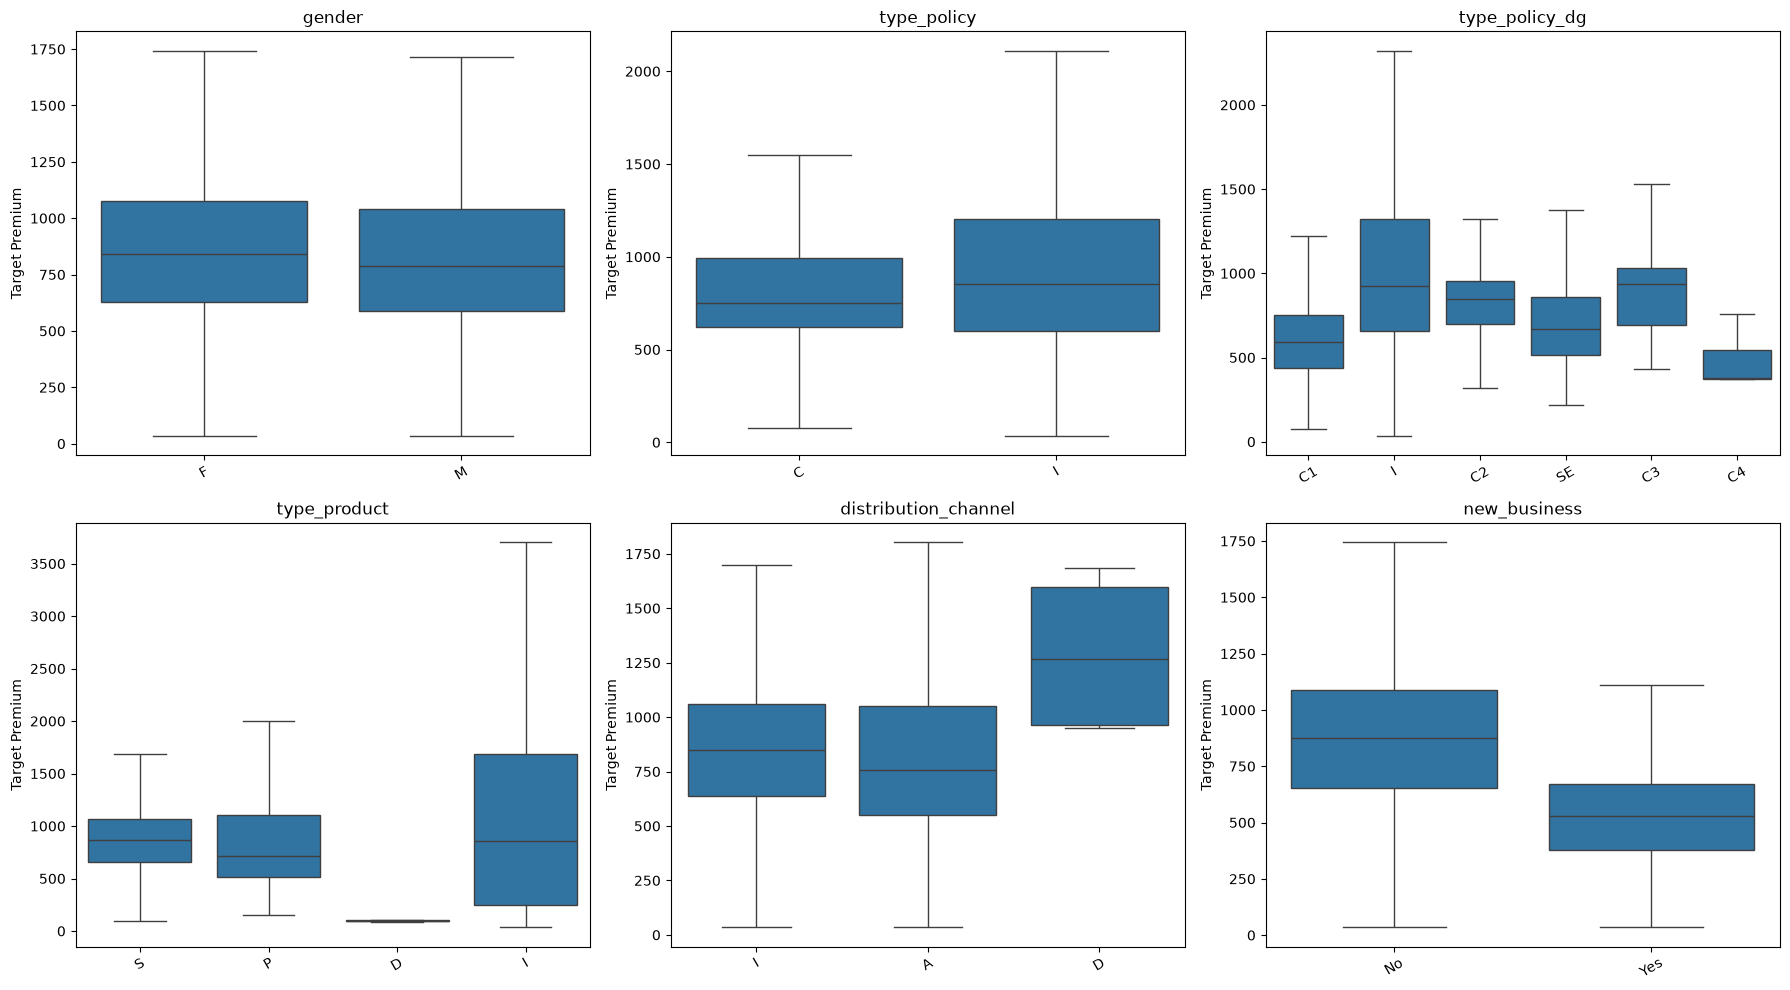

In [80]:
# Step 05.5 — Categorical Target Boxplots
#
# Research Question:
# How does the target distribution vary
# across different categorical features?
#
# Purpose:
# Compare median, spread, and category-level
# differences without removing observations.

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, column in zip(axes.flat, categorical_features):

    sns.boxplot(
        data=development_df,
        x=column,
        y="target_premium",
        showfliers=False,
        ax=ax
    )

    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("Target Premium")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [81]:
# Step 05.6 — Eta-Squared Effect Size
#
# Research Question:
# How much variation in target_premium is
# associated with categorical group differences?
#
# Purpose:
# Measure unadjusted categorical effect sizes.

def eta_squared(data, category, target="target_premium"):

    subset = data[[category, target]].dropna()

    overall_mean = subset[target].mean()

    grouped = subset.groupby(category)[target]

    between_ss = sum(
        len(values) * (values.mean() - overall_mean) ** 2
        for _, values in grouped
    )

    total_ss = (
        (subset[target] - overall_mean) ** 2
    ).sum()

    return between_ss / total_ss if total_ss > 0 else np.nan


eta_results = pd.DataFrame({
    "Feature": categorical_features,
    "Eta Squared": [
        eta_squared(development_df, col)
        for col in categorical_features
    ]
})

eta_results["Explained Variation (%)"] = (
    eta_results["Eta Squared"] * 100
)

eta_results = eta_results.sort_values(
    "Eta Squared",
    ascending=False
)

display(eta_results.round(6))

,Feature,Eta Squared,Explained Variation (%)
3,type_product,0.091788,9.178802
2,type_policy_dg,0.089386,8.938620
5,new_business,0.046631,4.663137
1,type_policy,0.027364,2.736447
4,distribution_channel,0.001706,0.170606
0,gender,0.001284,0.128424


In [82]:
## Outlier Analysis 

In [83]:
# Step 07.1 — Numerical Outlier Screening
#
# Research Question:
# Which numerical predictors contain extreme values?
#
# Purpose:
# Quantify potential outliers without removing them.

outlier_features = [
    "age",
    "previous_premium",
    "cost_claims_year",
    "n_medical_services",
    "seniority_insured",
    "seniority_policy",
    "IICIMUN",
    "IICIPROV"
]

outlier_results = []

for col in outlier_features:

    s = development_df[col].dropna()

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_results.append({
        "Feature": col,
        "Min": s.min(),
        "P1": s.quantile(0.01),
        "P99": s.quantile(0.99),
        "Max": s.max(),
        "IQR Outliers": ((s < lower) | (s > upper)).sum(),
        "Outlier (%)": (
            ((s < lower) | (s > upper)).mean() * 100
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(3))

,Feature,Min,P1,P99,Max,IQR Outliers,Outlier (%)
0,age,0.00,0.00,88.00,99.00,0,0.000
1,previous_premium,33.33,103.02,2755.14,15339.78,3906,6.156
2,cost_claims_year,0.00,0.00,6785.18,49509.19,5998,9.452
3,n_medical_services,0.00,0.00,113.00,1029.00,4319,6.806
4,seniority_insured,0.00,0.00,57.00,84.00,1225,1.931
5,seniority_policy,0.00,0.00,65.00,85.00,1497,2.359
6,IICIMUN,0.01,0.20,22.84,250.00,450,0.755
7,IICIPROV,0.01,0.20,10.49,10.49,0,0.000


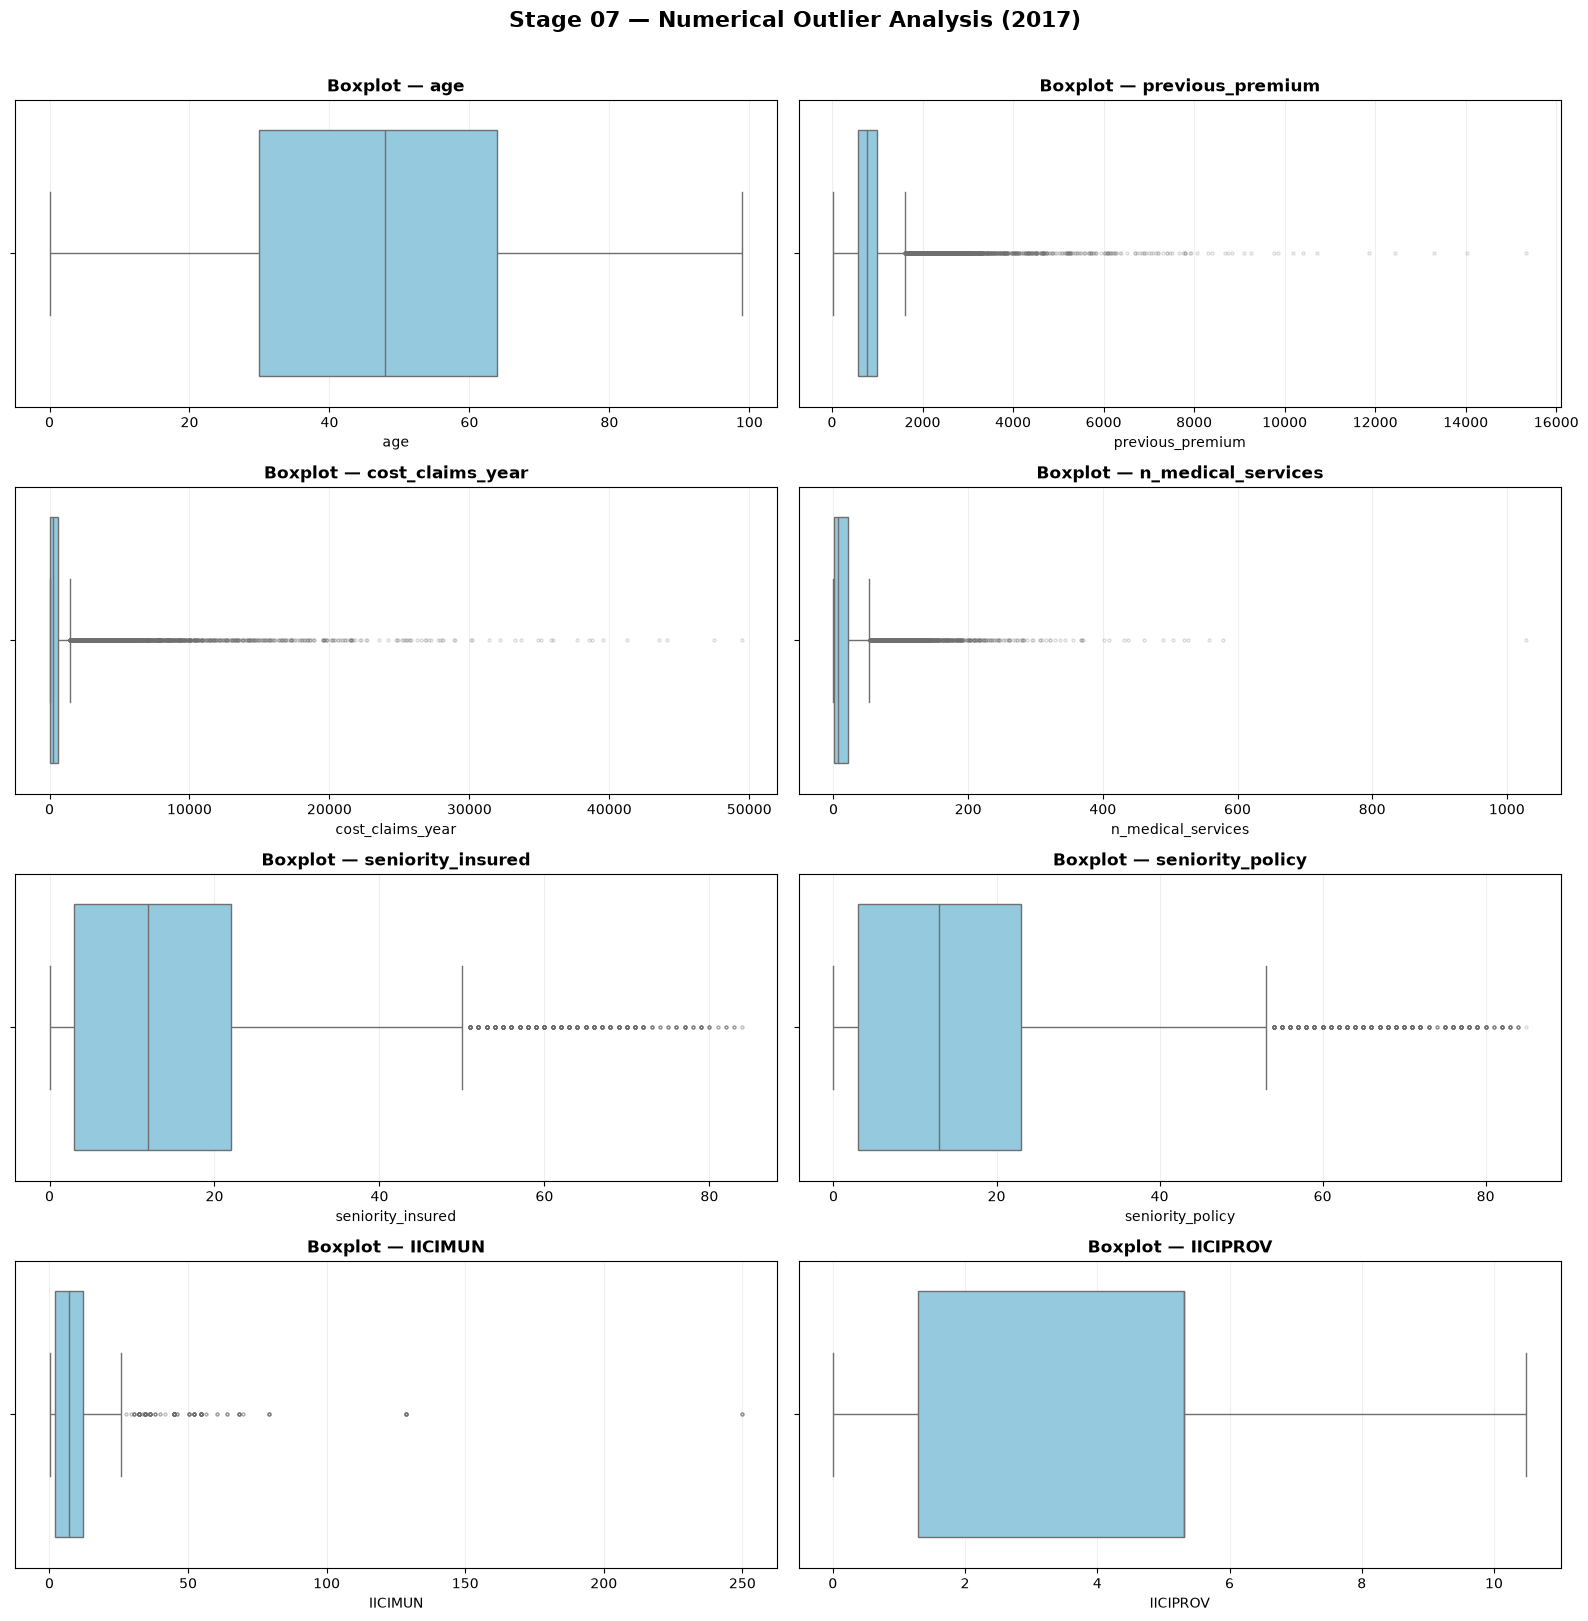

In [84]:
# Step 07.2 — Boxplots of Flagged Numerical Features
#
# Research Question:
# Which numerical features contain extreme observations?
#
# Purpose:
# Visualize outliers using the original feature distributions
# without removing or modifying any observations.

flagged_features = [
    "age",
    "previous_premium",
    "cost_claims_year",
    "n_medical_services",
    "seniority_insured",
    "seniority_policy",
    "IICIMUN",
    "IICIPROV"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 16))

for ax, feature in zip(axes.flat, flagged_features):

    sns.boxplot(
        x=development_df[feature].dropna(),
        ax=ax,
        color="skyblue",
        flierprops={
            "marker": "o",
            "markersize": 2,
            "alpha": 0.25
        }
    )

    ax.set_title(
        f"Boxplot — {feature}",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel(feature)
    ax.grid(axis="x", alpha=0.2)

plt.suptitle(
    "Stage 07 — Numerical Outlier Analysis (2017)",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

In [85]:
# Step 07.3.1 — Extreme Value Investigation
#
# Research Question:
# Which observations exceed the 99th percentile?
#
# Purpose:
# Quantify extreme values without removing observations.

extreme_summary = []

for feature in flagged_features:

    values = development_df[feature].dropna()

    p99 = values.quantile(0.99)

    extreme_summary.append({
        "Feature": feature,
        "P99": p99,
        "Maximum": values.max(),
        "Above P99": (values > p99).sum(),
        "Above P99 (%)": (values > p99).mean() * 100,
        "Max / P99": (
            values.max() / p99 if p99 != 0 else np.nan
        )
    })

extreme_summary = pd.DataFrame(extreme_summary)

display(extreme_summary.round(3))

,Feature,P99,Maximum,Above P99,Above P99 (%),Max / P99
0,age,88.00,99.00,592,0.933,1.125
1,previous_premium,2755.14,15339.78,635,1.001,5.568
2,cost_claims_year,6785.18,49509.19,634,0.999,7.297
3,n_medical_services,113.00,1029.00,624,0.983,9.106
4,seniority_insured,57.00,84.00,619,0.975,1.474
5,seniority_policy,65.00,85.00,607,0.957,1.308
6,IICIMUN,22.84,250.00,464,0.778,10.946
7,IICIPROV,10.49,10.49,0,0.000,1.000


In [87]:
# Step 07.3.2 — Inspect Extreme Observations
#
# Research Question:
# Are extreme observations consistent with
# other relevant insurance characteristics?
#
# Purpose:
# Examine actual records without modifying the dataset.

investigation_features = [
    "IICIMUN",
    "cost_claims_year",
    "n_medical_services",
    "previous_premium"
]

context_columns = [
    "ID",
    "age",
    "type_policy_dg",
    "type_product",
    "previous_premium",
    "cost_claims_year",
    "n_medical_services",
    "IICIMUN",
    "IICIPROV",
    "target_premium"
]

for feature in investigation_features:

    print(f"\nTop 10 extreme observations: {feature}")

    display(
        development_df.nlargest(
            10, feature
        )[context_columns]
    )


Top 10 extreme observations: IICIMUN


,ID,age,type_policy_dg,type_product,previous_premium,cost_claims_year,n_medical_services,IICIMUN,IICIPROV,target_premium
13263,13423_1,75,I,S,507.96,0.00,0,250.00,0.90,518.13
15454,14031_1,82,I,S,850.68,711.04,21,250.00,0.90,876.18
15456,14031_3,75,I,S,850.68,225.23,3,250.00,0.90,867.59
19708,15304_2,75,I,S,1083.24,200.94,2,250.00,0.90,1159.48
19710,15304_4,39,I,S,613.07,0.00,0,250.00,0.90,669.12
66942,29311_1,37,SE,S,566.10,0.00,0,128.71,6.07,641.35
66944,29311_2,43,SE,S,560.55,168.67,1,128.71,6.07,647.70
66946,29311_3,7,SE,S,381.48,0.00,0,128.71,6.07,435.54
66948,29311_4,64,SE,S,827.22,1976.57,2,128.71,6.07,1044.48
69526,29859_1,64,SE,S,851.70,538.33,6,128.71,6.07,1064.88



Top 10 extreme observations: cost_claims_year


,ID,age,type_policy_dg,type_product,previous_premium,cost_claims_year,n_medical_services,IICIMUN,IICIPROV,target_premium
102912,4557_1,48,C1,S,745.38,49509.19,344,2.66,1.88,767.60
4087,1109_1,84,I,P,6180.19,47477.94,100,7.84,6.07,6748.82
101019,4095_1,64,I,S,1239.27,44124.88,321,17.13,10.49,1913.95
74766,3115_2,71,I,P,2566.41,43566.35,329,1.52,1.19,3337.44
5873,11520_1,55,I,S,1226.14,41242.68,114,10.57,6.19,1400.46
110812,6512_1,60,SE,S,1367.54,39569.88,137,1.75,0.58,1654.44
75371,31306_193,56,C4,S,544.39,38736.54,504,NaN,NaN,549.78
117124,8226_1,63,SE,S,2556.31,38543.76,201,3.44,6.19,3291.59
100161,389_1,68,I,P,10191.91,37722.49,34,0.85,0.51,10600.86
115897,789_7,63,I,P,1607.52,35974.38,272,1.50,1.88,2062.44



Top 10 extreme observations: n_medical_services


,ID,age,type_policy_dg,type_product,previous_premium,cost_claims_year,n_medical_services,IICIMUN,IICIPROV,target_premium
74177,30975_2,68,I,S,1707.48,29000.64,1029,1.52,1.19,2178.72
102571,4484_1,73,I,P,1793.76,12687.78,579,1.52,1.19,2309.87
61473,27927_1,71,I,I,1638.22,11755.50,557,1.66,6.19,1753.38
108506,5948_1,59,SE,S,1809.48,28928.42,527,2.04,1.88,2047.27
122796,9889_2,69,I,S,1270.58,25817.22,521,1.52,1.19,1372.59
75371,31306_193,56,C4,S,544.39,38736.54,504,NaN,NaN,549.78
927,10247_2,68,C2,S,1124.04,28134.56,490,0.92,1.19,953.70
83530,331_1,94,I,P,2708.10,7427.64,461,1.52,1.19,2762.35
3071,10836_1,65,I,S,2764.20,20283.83,437,0.10,0.60,3105.75
79930,32202_1,31,SE,P,404.94,25276.26,431,1.82,1.19,568.63



Top 10 extreme observations: previous_premium


,ID,age,type_policy_dg,type_product,previous_premium,cost_claims_year,n_medical_services,IICIMUN,IICIPROV,target_premium
24357,1654_1,79,I,S,15339.78,1871.70,36,7.84,6.07,13679.44
108837,603_2,77,I,P,14027.89,1648.32,35,1.52,1.19,12040.21
111531,668_2,77,I,P,13303.72,2959.02,135,10.57,6.19,11401.89
7006,11799_7,57,I,S,12429.72,2521.97,13,1.02,1.13,12647.22
23363,162_2,79,I,P,11865.66,4400.57,35,17.13,10.49,12101.82
50783,2398_1,75,I,S,10723.17,1756.39,28,1.52,1.19,9282.00
70445,3001_1,72,I,P,10411.08,35838.84,367,1.52,1.19,10765.59
100161,389_1,68,I,P,10191.91,37722.49,34,0.85,0.51,10600.86
55838,2555_2,72,I,S,9859.62,8302.20,162,1.52,1.19,10155.55
120335,913_2,69,I,S,9755.28,2756.29,109,0.85,0.51,7468.95


In [88]:
# Step 07.3.3 — Investigate IICIMUN = 250
#
# Purpose:
# Determine how frequently this suspicious
# value occurs and inspect related attributes.

suspicious_iicimun = development_df.loc[
    development_df["IICIMUN"] == 250
]

print("Records with IICIMUN = 250:", len(suspicious_iicimun))

display(
    suspicious_iicimun[
        [
            "ID",
            "period",
            "IICIMUN",
            "IICIPROV",
            "n_insured_mun",
            "n_insured_prov",
            "type_policy_dg"
        ]
    ].head(20)
)

Records with IICIMUN = 250: 5


,ID,period,IICIMUN,IICIPROV,n_insured_mun,n_insured_prov,type_policy_dg
13263,13423_1,2017,250.0,0.9,6,479,I
15454,14031_1,2017,250.0,0.9,6,479,I
15456,14031_3,2017,250.0,0.9,6,479,I
19708,15304_2,2017,250.0,0.9,6,479,I
19710,15304_4,2017,250.0,0.9,6,479,I


# No outlier removal would be possible as the high and extreme vsalues seems to be consistent based on their discription and mainly for high premium 

## Checking distribution of variables on different period

In [89]:
# Step 07.4.1 — Numerical Temporal Stability
#
# Research Question:
# Did numerical feature distributions change across years?
#
# Purpose:
# Compare count, mean, median, standard deviation,
# and extreme percentiles without modifying the dataset.

temporal_numeric_features = [
    "age",
    "previous_premium",
    "cost_claims_year",
    "n_medical_services",
    "seniority_insured",
    "seniority_policy",
    "n_insured_pc",
    "n_insured_mun",
    "n_insured_prov",
    "IICIMUN",
    "IICIPROV"
]

temporal_summary = (
    df.loc[
        df["period"].isin([2017, 2018]),
        ["period"] + temporal_numeric_features
    ]
    .groupby("period")
    .agg(["count", "mean", "median", "std"])
)

display(temporal_summary.round(3))

age                        previous_premium                   \
        count    mean median     std            count     mean  median   
period                                                                   
2017    63455  46.052   48.0  22.994            63455  856.285  776.69   
2018    59814  46.738   48.0  23.031            59814  893.840  799.92   

                cost_claims_year           ... n_insured_prov             \
            std            count     mean  ...         median        std   
period                                     ...                             
2017    540.566            63455  628.872  ...         7467.0  12525.225   
2018    553.344            59814  638.437  ...         7013.0  11441.261   

       IICIMUN                      IICIPROV                       
         count   mean median    std    count   mean median    std  
period                                                             
2017     59610  7.552   6.94  6.795    61163  4.503   5.31  2.849  
2018     57649  7.098   6.29  6.394    59115  4.267   4.92  2.701  

[2 rows x 44 columns]

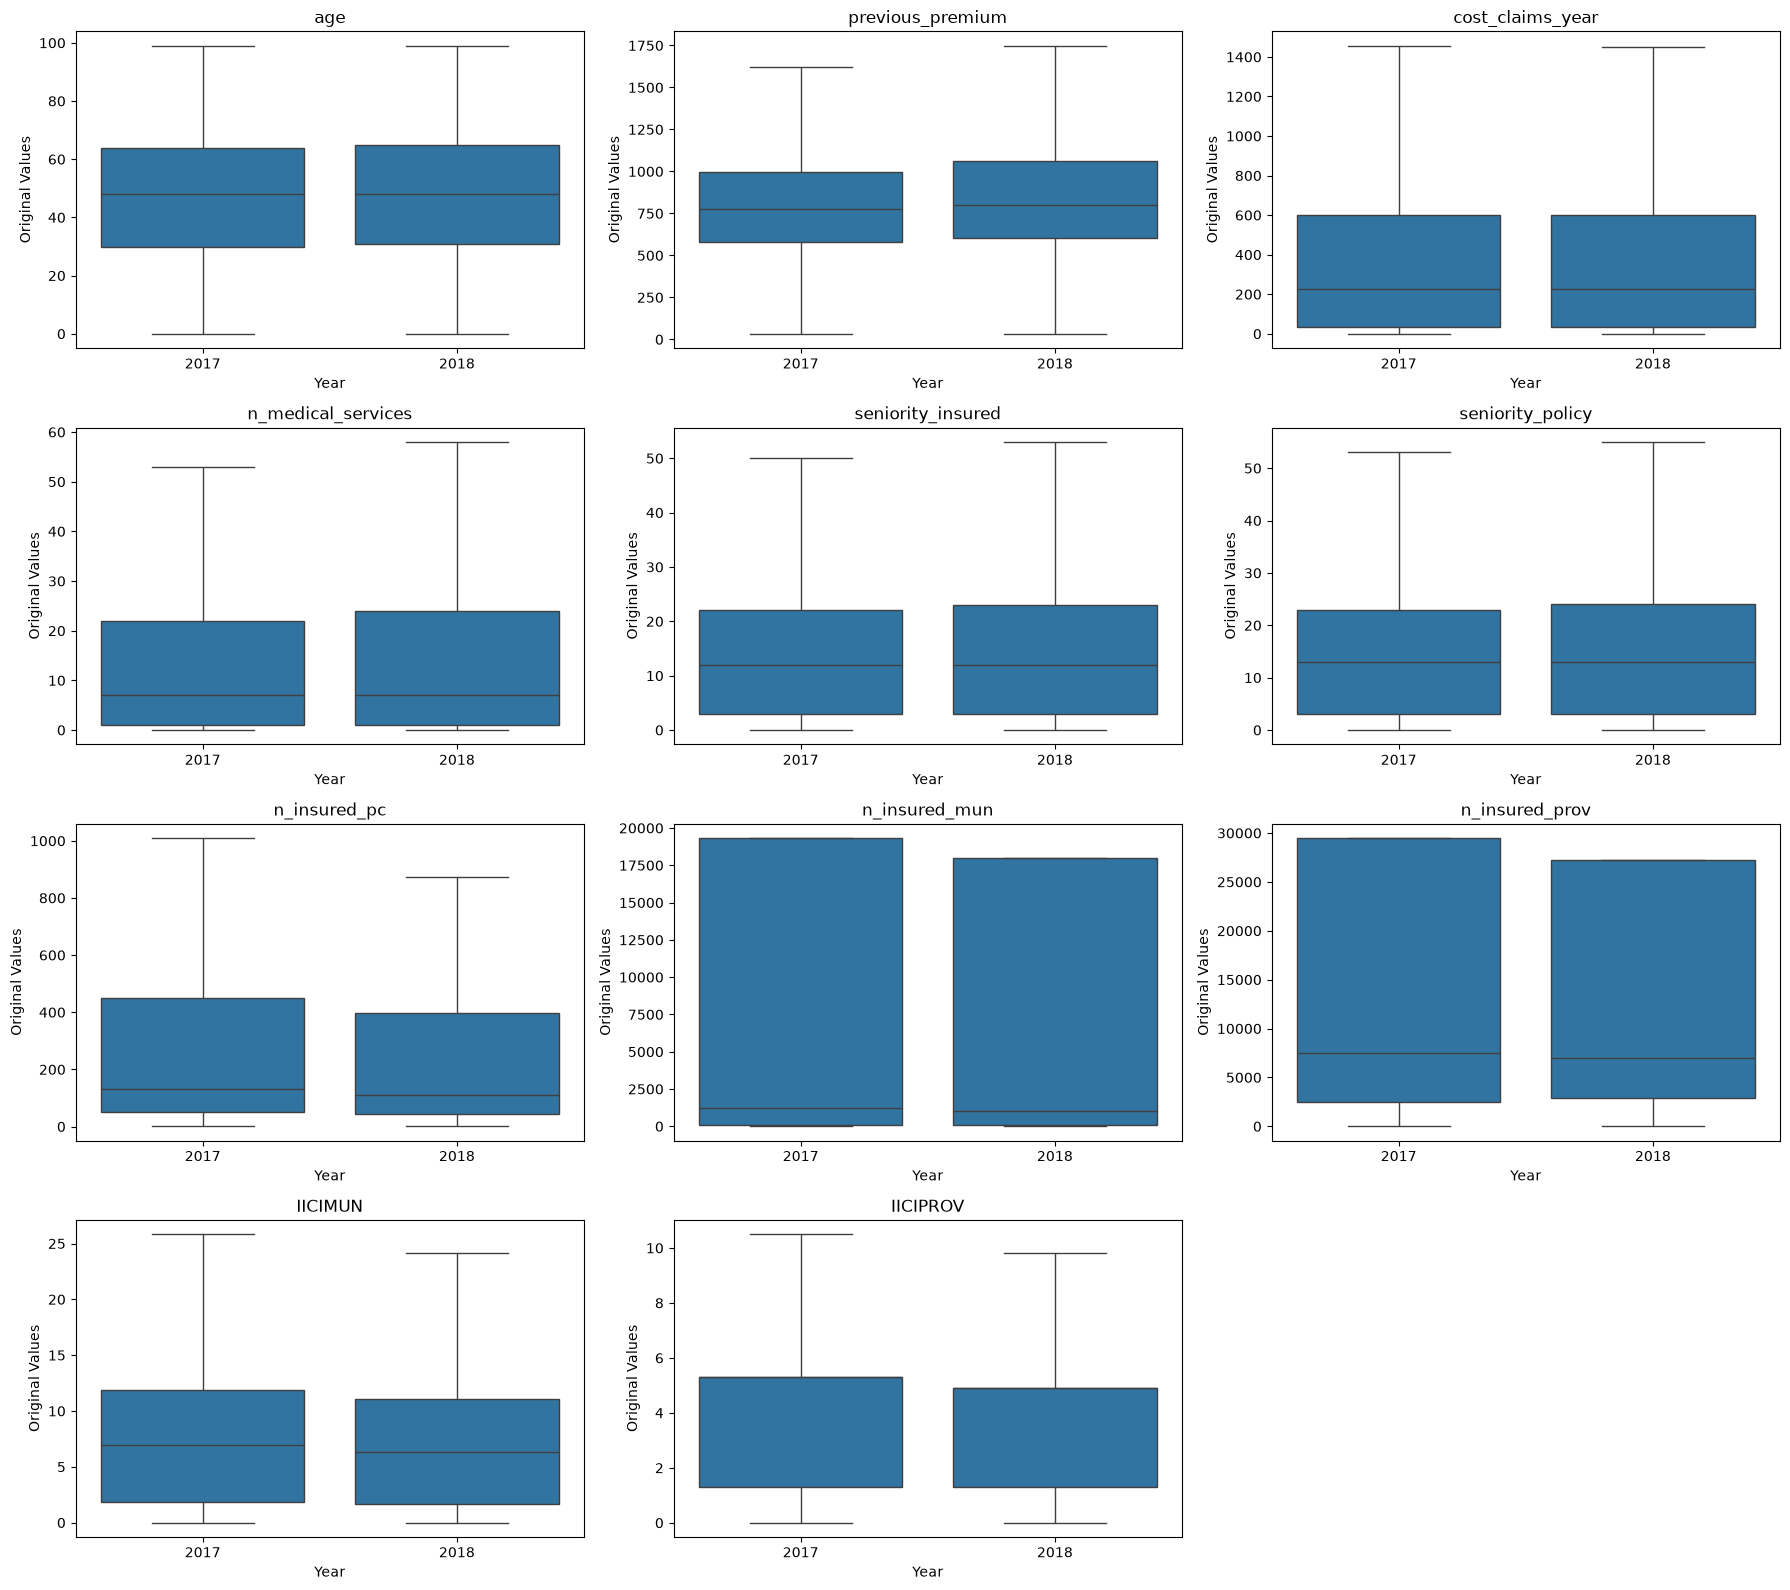

In [90]:
# Step 07.4.2 — Numerical Distribution Comparison
#
# Research Question:
# Are numerical predictor distributions stable?
#
# Purpose:
# Compare original-scale boxplots across years.

fig, axes = plt.subplots(4, 3, figsize=(18, 16))

for ax, feature in zip(axes.flat, temporal_numeric_features):

    sns.boxplot(
        data=df[df["period"].isin([2017, 2018])],
        x="period",
        y=feature,
        showfliers=False,
        ax=ax
    )

    ax.set_title(feature, fontsize=12)
    ax.set_xlabel("Year")
    ax.set_ylabel("Original Values")

for ax in axes.flat[len(temporal_numeric_features):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [91]:
# Step 07.5.1 — Categorical Temporal Stability
#
# Research Question:
# Did category proportions change across years?
#
# Purpose:
# Compare category percentages in 2017 and 2018.

temporal_categorical_features = [
    "gender",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "distribution_channel",
    "new_business"
]

for feature in temporal_categorical_features:

    proportions = pd.crosstab(
        df["period"],
        df[feature],
        normalize="index",
        dropna=False
    ) * 100

    print(f"\nFeature: {feature}")
    display(proportions.round(2))


Feature: gender


gender,F,M
period,,
2017,54.38,45.62
2018,54.89,45.11



Feature: type_policy


type_policy,C,I
period,,
2017,41.21,58.79
2018,37.35,62.65



Feature: type_policy_dg


type_policy_dg,C1,C2,C3,C4,I,SE
period,,,,,,
2017,10.70,2.02,25.67,2.82,45.08,13.71
2018,10.14,2.01,25.18,0.02,49.80,12.85


... (2 outputs left out)


Feature: distribution_channel


distribution_channel,A,D,I
period,,,
2017,33.54,0.01,66.45
2018,35.98,0.23,63.79



Feature: new_business


new_business,No,Yes
period,,
2017,88.20,11.80
2018,89.53,10.47


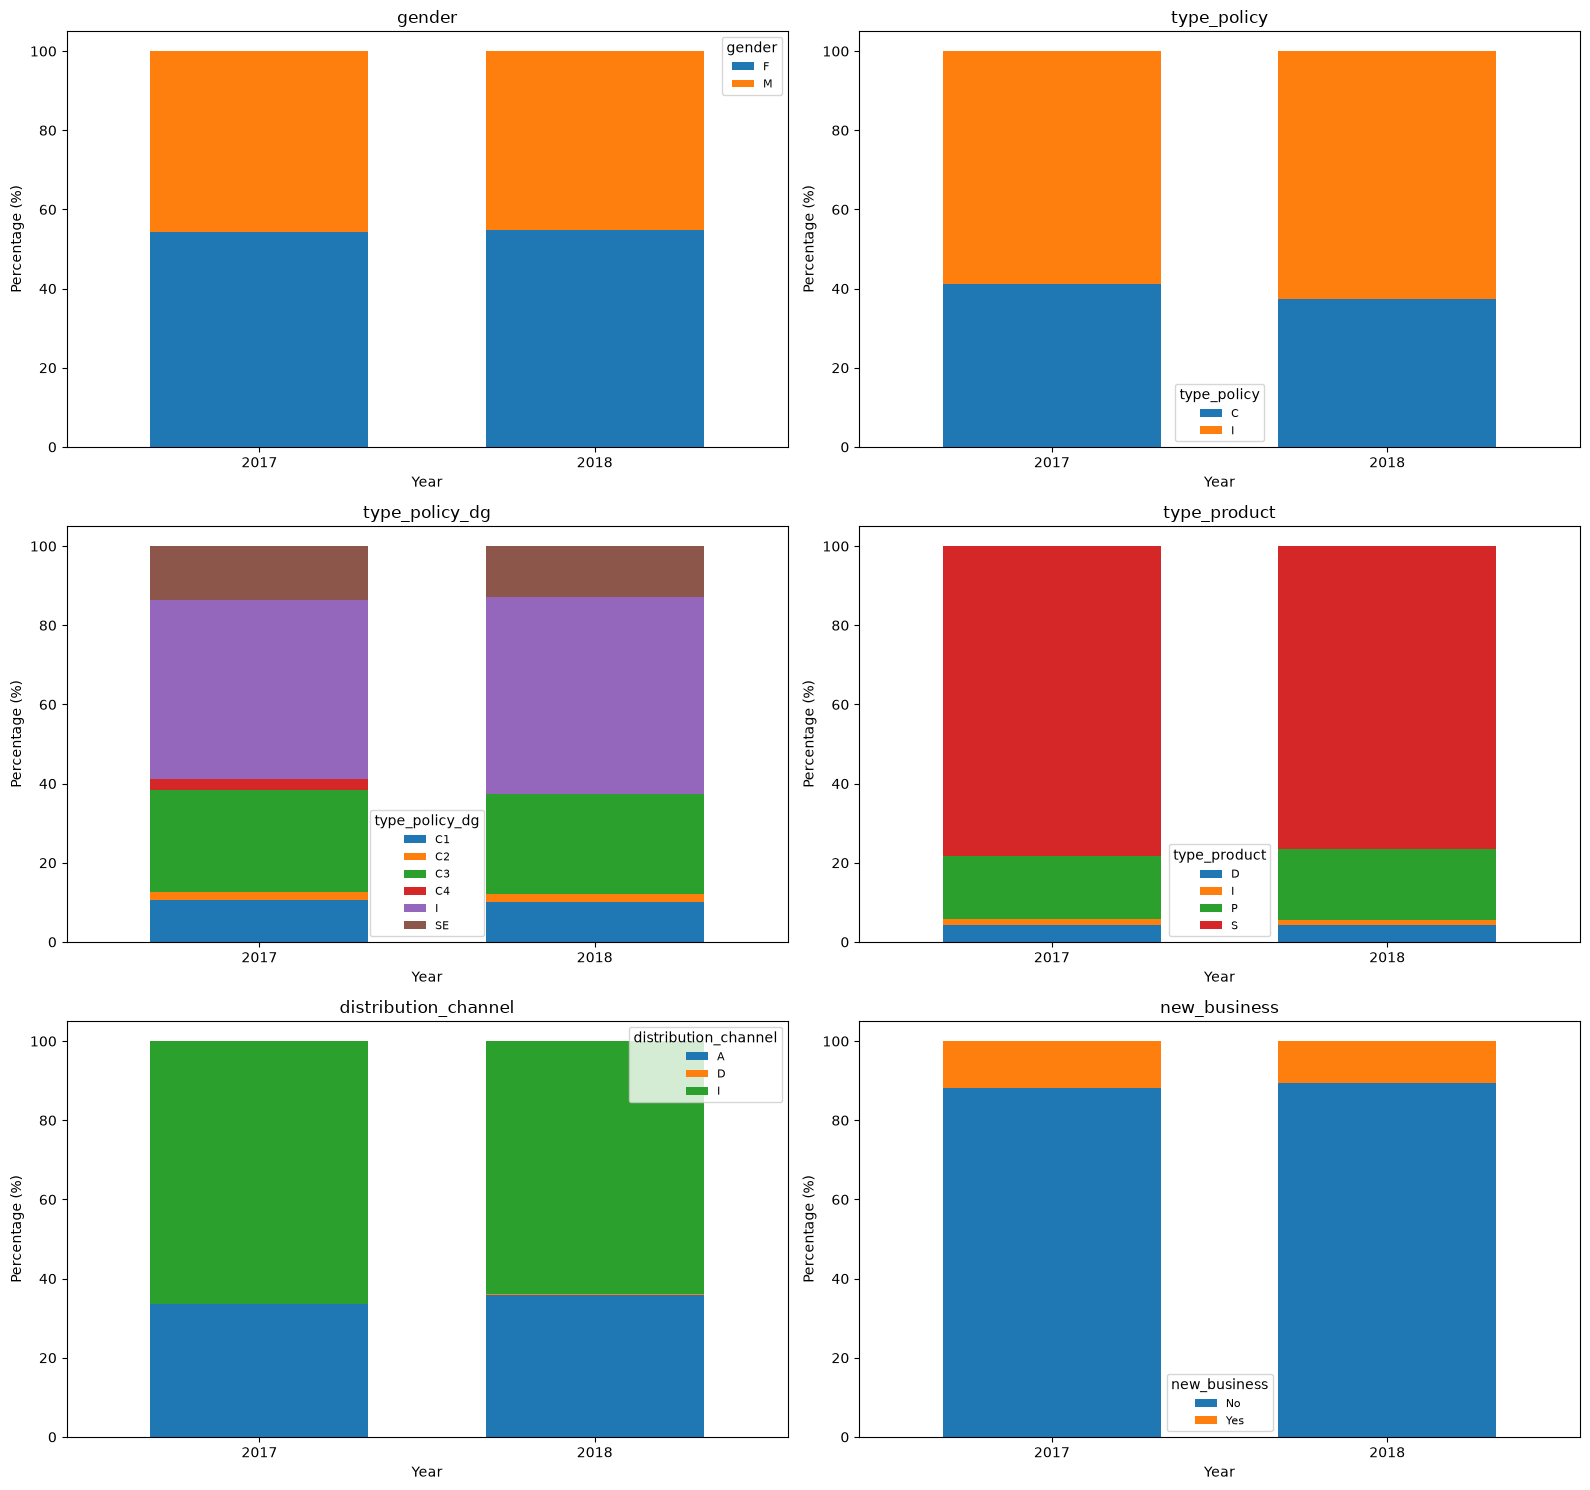

In [92]:
# Step 07.5.2 — Categorical Distribution Comparison
#
# Purpose:
# Visualize category composition by year.

fig, axes = plt.subplots(3, 2, figsize=(16, 15))

for ax, feature in zip(axes.flat, temporal_categorical_features):

    proportions = pd.crosstab(
        df["period"],
        df[feature],
        normalize="index"
    ) * 100

    proportions.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        width=0.65
    )

    ax.set_title(feature)
    ax.set_xlabel("Year")
    ax.set_ylabel("Percentage (%)")
    ax.legend(title=feature, fontsize=8)
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [93]:
# Step 07.6 — Missingness Stability
#
# Research Question:
# Did missingness patterns change between years?
#
# Purpose:
# Compare missing percentages across years,
# excluding the target and identifiers.

excluded_columns = [
    "ID",
    "ID_policy",
    "ID_insured",
    "period",
    "target_premium",
    "age_difference"
]

predictor_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

year_data = df.loc[
    df["period"].isin([2017, 2018]),
    ["period"] + predictor_columns
]

missing_2017 = (
    year_data.loc[year_data["period"] == 2017, predictor_columns]
    .isna()
    .mean() * 100
)

missing_2018 = (
    year_data.loc[year_data["period"] == 2018, predictor_columns]
    .isna()
    .mean() * 100
)

missing_stability = pd.DataFrame({
    "2017 Missing (%)": missing_2017,
    "2018 Missing (%)": missing_2018
})

missing_stability["Difference (pp)"] = (
    missing_stability["2018 Missing (%)"]
    - missing_stability["2017 Missing (%)"]
)

missing_stability = missing_stability[
    (missing_stability["2017 Missing (%)"] > 0)
    | (missing_stability["2018 Missing (%)"] > 0)
].sort_values(
    "Difference (pp)",
    key=lambda s: s.abs(),
    ascending=False
)

display(missing_stability.round(3))

,2017 Missing (%),2018 Missing (%),Difference (pp)
date_lapse_insured,77.326,90.501,13.175
year_lapse_insured,77.326,90.501,13.175
date_lapse_policy,80.292,91.997,11.705
year_lapse_policy,80.292,91.997,11.705
C_GI,7.218,4.740,-2.478
C_IE_S,7.218,4.740,-2.478
C_IE_P,7.218,4.740,-2.478
C_II,7.218,4.740,-2.478
C_GE_P,7.218,4.740,-2.478
C_GE_S,7.218,4.740,-2.478


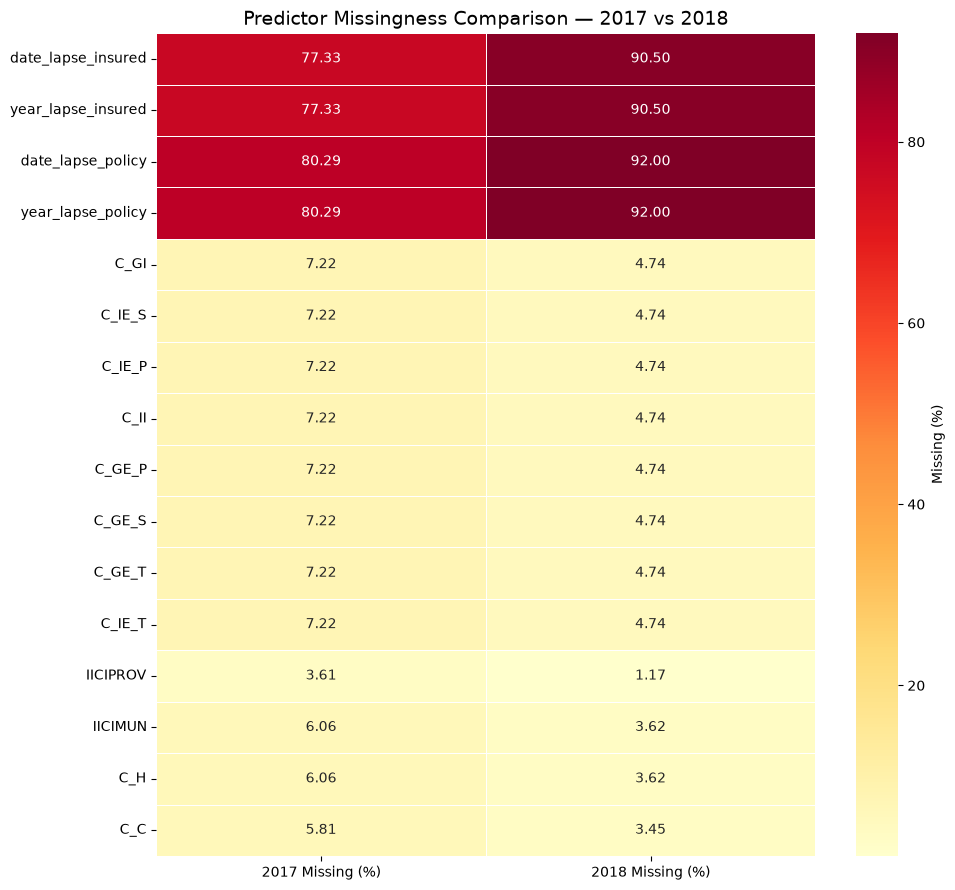

In [94]:
# Step 07.6.2 — Missingness Comparison Heatmap
#
# Purpose:
# Identify features with substantial changes
# in missingness percentages.

plt.figure(figsize=(10, 9))

sns.heatmap(
    missing_stability[
        ["2017 Missing (%)", "2018 Missing (%)"]
    ],
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Missing (%)"}
)

plt.title(
    "Predictor Missingness Comparison — 2017 vs 2018",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [95]:
# Step 07.7 — Population Stability Index (PSI)
#
# Research Question:
# Which numerical predictor distributions shifted
# between 2017 and 2018?
#
# Purpose:
# Quantify distribution differences using 2017
# as the reference distribution.

def calculate_psi(reference, comparison, bins=10):

    reference = reference.dropna()
    comparison = comparison.dropna()

    if reference.empty or comparison.empty:
        return np.nan

    edges = np.unique(
        np.quantile(reference, np.linspace(0, 1, bins + 1))
    )

    if len(edges) < 2:
        return np.nan

    edges[0] = -np.inf
    edges[-1] = np.inf

    ref_counts = np.histogram(reference, bins=edges)[0]
    comp_counts = np.histogram(comparison, bins=edges)[0]

    # Smooth empty bins to avoid log(0)
    epsilon = 1e-6

    ref_pct = np.maximum(
        ref_counts / ref_counts.sum(), epsilon
    )

    comp_pct = np.maximum(
        comp_counts / comp_counts.sum(), epsilon
    )

    return np.sum(
        (comp_pct - ref_pct) * np.log(comp_pct / ref_pct)
    )


psi_results = []

for feature in temporal_numeric_features:

    ref = df.loc[df["period"] == 2017, feature]
    comp = df.loc[df["period"] == 2018, feature]

    psi_results.append({
        "Feature": feature,
        "PSI": calculate_psi(ref, comp)
    })

psi_results = pd.DataFrame(psi_results).sort_values(
    "PSI",
    ascending=False
)

display(psi_results.round(4))

,Feature,PSI
10,IICIPROV,6.1689
9,IICIMUN,1.1261
8,n_insured_prov,0.1305
7,n_insured_mun,0.0471
1,previous_premium,0.0449
6,n_insured_pc,0.0415
4,seniority_insured,0.0253
5,seniority_policy,0.0225
3,n_medical_services,0.0057
0,age,0.0013


# Based on our analysis distribution seems to be almost same for both the years including missingness 

# Both year ID analysis

In [96]:
# Step 08.1 — Longitudinal Record Overlap
#
# Research Question:
# How many IDs occur in both 2017 and 2018?
#
# Purpose:
# Identify repeated entities and year-specific records
# without modifying the original dataset.

ids_2017 = set(
    df.loc[df["period"] == 2017, "ID"].dropna()
)

ids_2018 = set(
    df.loc[df["period"] == 2018, "ID"].dropna()
)

common_ids = ids_2017.intersection(ids_2018)

only_2017 = ids_2017 - ids_2018
only_2018 = ids_2018 - ids_2017

overlap_summary = pd.DataFrame({
    "Metric": [
        "Unique IDs in 2017",
        "Unique IDs in 2018",
        "IDs appearing in both years",
        "IDs exclusive to 2017",
        "IDs exclusive to 2018",
        "2017 ID overlap (%)",
        "2018 ID overlap (%)"
    ],
    "Value": [
        len(ids_2017),
        len(ids_2018),
        len(common_ids),
        len(only_2017),
        len(only_2018),
        len(common_ids) / len(ids_2017) * 100,
        len(common_ids) / len(ids_2018) * 100
    ]
})

display(overlap_summary.round(2))

,Metric,Value
0,Unique IDs in 2017,63455.00
1,Unique IDs in 2018,59814.00
2,IDs appearing in both years,53532.00
3,IDs exclusive to 2017,9923.00
4,IDs exclusive to 2018,6282.00
5,2017 ID overlap (%),84.36
6,2018 ID overlap (%),89.50


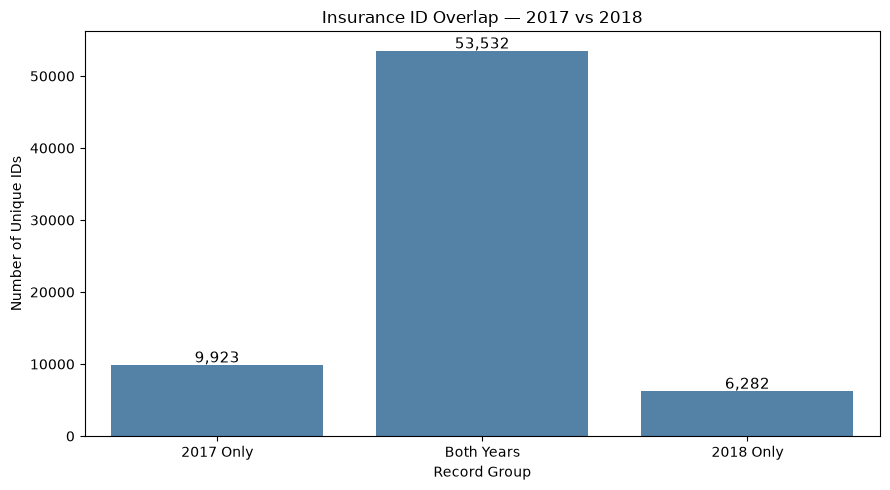

In [97]:
# Step 08.1.2 — Longitudinal Overlap Visualization
#
# Purpose:
# Compare IDs exclusive to each year
# and IDs shared across both years.

overlap_counts = pd.Series({
    "2017 Only": len(only_2017),
    "Both Years": len(common_ids),
    "2018 Only": len(only_2018)
})

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=overlap_counts.index,
    y=overlap_counts.values,
    color="steelblue"
)

for i, value in enumerate(overlap_counts.values):
    ax.text(
        i,
        value + 300,
        f"{value:,}",
        ha="center",
        fontsize=11
    )

plt.title("Insurance ID Overlap — 2017 vs 2018")
plt.xlabel("Record Group")
plt.ylabel("Number of Unique IDs")

plt.tight_layout()
plt.show()

In [98]:
# Step 08.1.3 — ID Uniqueness Verification
#
# Research Question:
# Can the same ID occur multiple times within a year?
#
# Purpose:
# Validate the interpretation of longitudinal overlap.

id_uniqueness = (
    df[df["period"].isin([2017, 2018])]
    .groupby("period")
    .agg(
        Total_Records=("ID", "size"),
        Unique_IDs=("ID", "nunique")
    )
)

id_uniqueness["Duplicate_ID_Records"] = (
    id_uniqueness["Total_Records"]
    - id_uniqueness["Unique_IDs"]
)

display(id_uniqueness)

,Total_Records,Unique_IDs,Duplicate_ID_Records
period,,,
2017,63455,63455,0
2018,59814,59814,0


In [99]:
# Step 08.1.4 — Inspect Longitudinal Records
#
# Research Question:
# How do records for the same ID differ across years?
#
# Purpose:
# Examine policy continuity without using
# the reserved 2018 target.

sample_ids = sorted(common_ids, key=str)[:10]

inspection_columns = [
    "ID",
    "ID_policy",
    "ID_insured",
    "period",
    "age",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "previous_premium",
    "seniority_insured",
    "seniority_policy"
]

longitudinal_sample = (
    df.loc[
        df["ID"].isin(sample_ids),
        inspection_columns
    ]
    .sort_values(["ID", "period"])
)

display(longitudinal_sample)

,ID,ID_policy,ID_insured,period,age,type_policy,type_policy_dg,type_product,previous_premium,seniority_insured,seniority_policy
0,10000_1,10000,1,2017,40,C,C1,S,573.24,13,13
1,10000_1,10000,1,2018,41,C,C1,S,630.36,14,14
2,10001_1,10001,1,2017,41,I,I,S,2885.57,13,13
3,10001_1,10001,1,2018,42,I,I,S,2882.54,14,14
4,10002_1,10002,1,2017,67,I,I,S,1877.82,13,13
5,10002_1,10002,1,2018,68,I,I,S,2010.91,14,14
6,10002_3,10002,3,2017,35,I,I,S,1137.26,13,13
7,10002_3,10002,3,2018,36,I,I,S,1230.18,14,14
8,10002_4,10002,4,2017,33,I,I,S,1065.90,13,13
9,10002_4,10002,4,2018,34,I,I,S,1242.36,14,14


In [100]:
# Step 08.2 — Identifier Relationship Analysis
#
# Research Question:
# What is the relationship between ID, ID_policy, and ID_insured?
#
# Purpose:
# Determine the dataset's entity structure and
# identify an appropriate grouping key for validation.

id_relationships = pd.DataFrame({
    "Metric": [
        "Unique IDs",
        "Unique Policy IDs",
        "Unique Insured IDs",
        "Policies with multiple IDs",
        "IDs linked to multiple policies",
        "IDs linked to multiple insured values",
        "Policy-insured combinations with multiple IDs"
    ],
    "Value": [
        df["ID"].nunique(),
        df["ID_policy"].nunique(),
        df["ID_insured"].nunique(),

        (
            df.groupby("ID_policy")["ID"]
            .nunique().gt(1).sum()
        ),

        (
            df.groupby("ID")["ID_policy"]
            .nunique().gt(1).sum()
        ),

        (
            df.groupby("ID")["ID_insured"]
            .nunique().gt(1).sum()
        ),

        (
            df.groupby(["ID_policy", "ID_insured"])["ID"]
            .nunique().gt(1).sum()
        )
    ]
})

display(id_relationships)

,Metric,Value
0,Unique IDs,69737
1,Unique Policy IDs,32543
2,Unique Insured IDs,1205
3,Policies with multiple IDs,16676
4,IDs linked to multiple policies,0
5,IDs linked to multiple insured values,0
6,Policy-insured combinations with multiple IDs,0


In [101]:
# Step 08.2.2 — Policy Composition
#
# Purpose:
# Understand how many distinct insured records
# are associated with each policy.

insured_per_policy = (
    df.groupby("ID_policy")["ID"]
    .nunique()
)

display(
    insured_per_policy.describe(
        percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

print(
    "Maximum insured records under one policy:",
    insured_per_policy.max()
)

count    32543.000000
mean         2.142919
std          7.493906
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
95%          4.000000
99%          7.000000
max       1196.000000
Name: ID, dtype: float64

Maximum insured records under one policy: 1196


In [102]:
# Step 08.4 — Policy-Level Leakage Assessment
#
# Research Question:
# Do multiple insured records share the same policy?
#
# Purpose:
# Quantify within-policy dependence and prepare
# for group-aware validation without training models.

policy_structure = (
    development_df.groupby("ID_policy")
    .agg(
        total_records=("ID", "size"),
        unique_insured=("ID", "nunique")
    )
)

print("Total 2017 policies:", len(policy_structure))

print(
    "Policies with multiple insured records:",
    (policy_structure["unique_insured"] > 1).sum()
)

print(
    "Records belonging to multi-insured policies:",
    policy_structure.loc[
        policy_structure["unique_insured"] > 1,
        "total_records"
    ].sum()
)

print(
    "Maximum records under one policy:",
    policy_structure["total_records"].max()
)

Total 2017 policies: 29970
Policies with multiple insured records: 15220
Records belonging to multi-insured policies: 48705
Maximum records under one policy: 1196


In [103]:
# Step 08.5 — Group-Aware Train/Validation Split
#
# Research Question:
# Can we create training and validation sets
# without sharing policies between them?
#
# Purpose:
# Prepare independent policy groups for validation.
# Keep 2018 reserved for final evaluation.

from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        development_df,
        groups=development_df["ID_policy"]
    )
)

train_df = development_df.iloc[train_idx].copy()
val_df = development_df.iloc[val_idx].copy()

train_policies = set(train_df["ID_policy"])
val_policies = set(val_df["ID_policy"])

print("Training records:", len(train_df))
print("Validation records:", len(val_df))

print("Training policies:", len(train_policies))
print("Validation policies:", len(val_policies))

print(
    "Shared policies:",
    len(train_policies.intersection(val_policies))
)

print(
    "Shared IDs:",
    len(set(train_df["ID"]).intersection(val_df["ID"]))
)

print(
    "Total records preserved:",
    len(train_df) + len(val_df) == len(development_df)
)

Training records: 51286
Validation records: 12169
Training policies: 23976
Validation policies: 5994
Shared policies: 0
Shared IDs: 0
Total records preserved: True


# A random split could place individuals from the same policy in both training and validation, potentially giving misleading results.
# We chose a policy-based split to make validation more reliable and kept 2018 separate to check how well our model predicts premiums in the following year.